# 05 — Investment Appraisal

In Notebook 04 "Adaptive Planning", a series of analyses were carried out to evaluate the timing of infrastructure stages/projects over a set of transient scenarios, i.e., including the temporal trajectories of uncertainties. This Notebook 05 "Appraisal" expands these analyses by adding the quantification of (welfare) benefits alongside other key performance indicators. Therefore the main question this notebook helps analyse is **which plan is worth its cost to society, how robust is that verdict across uncertain scenarios, and which assumptions could overturn it?** It also asks **whether the plan protects the planning objectives.** It performs the discounted life-cycle appraisal of the six plans for the SBB MehrSpur case study. Like the previous notebooks, it is a demonstrative tutorial that you should adapt to your own case study.

As mentioned in the exercise sheets (and in the previous notebooks) you will be presented with different types of calculations and tasks:
- **Tutorials/Supporting task (optional):** building understanding but are not meant as report deliverable.
- **Mandatory/Expected task:** producing a definition, assumption, or result needed later in the project.
- **Advanced task (optional):** extends the model beyond the supplied example.


## Roadmap and learning objectives

The notebook follows one continuous argument: **prepare the paired appraisal -> compare value, risk and objective protection -> examine the value and price of waiting -> explain results and test assumptions -> improve the plan and recommend**. Part 1 imports or defines the planning requirements and prepares the dataset; Part 2 compares economic performance, regret and requirement protection; Part 3 examines waiting and investments avoided; Part 4 identifies drivers, vulnerabilities and appraisal sensitivity; and Part 5 explores trigger thresholds and supports the final recommendation.

By the end of this notebook, you will be able to:
1. Compare infrastructure investment plans using **Net Present Value (NPV)** relative to the baseline discounted at the configured discount rate (e.g., $2.0\%$) across shared uncertain scenarios.
2. Decompose life-cycle costs and user benefits into capital expenditure ($C_{\text{INV}}$), operating & maintenance costs ($C_{\text{OP}}$), in-vehicle and waiting travel time savings (Rule of a Half), and environmental/safety externalities (NIBA).
3. Evaluate plan robustness across uncertain scenarios (demand growth, mode preference shifts, technology changes and cost overruns) using **Minimax Regret**, target achievement rates (the configured performance requirements), and PRIM vulnerability diagnostics.
4. Combine monetary indicators (NPV) with other performance indicators (corridor travel time and wait time savings, modal shift to sustainable transport, $\text{CO}_2$ emissions).

### Link to Notebooks 02–04

- **Notebook 02:** Established the corridor context and integrated the Canton Zürich FSM transport model skims across infrastructure stages (baseline, stations only, tunnel only, and both packages).
- **Notebook 03:** Defines the uncertainty distributions and prepares the shared transport surrogate and response table.
- **Notebook 04:** Selects temporal trajectories, monitoring rules and performance requirements, and evaluates the planning scenarios. Notebook 05 reuses its saved experiment when available.
- **Notebook 05 (This Notebook):** Performs the comprehensive economic and multi-criteria appraisal. It evaluates plan performance across sampled scenarios, computes incremental net present value (NPV), evaluates economic regret and vulnerability, and compares monetary and performance trade-offs.

## Estimated time for Notebook 05

> - **Execution time:** with `USE_CACHED_DATASET = True` and a matching cached dataset, most cells run quickly. Building the appraisal dataset from scratch, the optional `RECHECK_GP_APPRAISAL` audit, the trigger-threshold grid search (Part 5) and the sensitivity analysis (Section 4.5) can each take several minutes.
> - **Reading and understanding:** allow approximately **2 hours** to work through the notebook without adapting it to your own case study.
> - **Case-study adaptation:** significant additional time is required to justify monetary values, costs, targets and residual values, and to document decisions.
>
> Plan your work accordingly. Execution time is fast but reading and understanding the notebook can take a few hours. Extra hour are needed to adapt the notebook to your project, troubleshooting and interpreting results.

## Scope

This notebook performs the **discounted life-cycle appraisal**: it uses the same shared transport response, uncertainty family and plans as Notebooks 03 and 04, and adds monetary valuation, discounting, residual values and regret.

## Setup

> **Case-study adaptation:** this notebook loads the shared response table prepared in Notebook 03, Section 3.1. After changing the corridor, physical stages, transport inputs or assignment behavior, return to Notebook 03 to rebuild the GP and prepare the response table, then review Notebook 03 diagnostics and rerun Notebook 04. Monetary values, discounting, emissions factors, CAPEX/OPEX and external cohort counts do not normally require retraining the GP surrogate as they remain in the appraisal layer. See `code/surrogate_model/README.md`.

Restart the kernel after updating source modules. If an appraisal/planning change affects the NB04 outputs checked by the handover, rerun NB04 before NB05; this does not require GP retraining. After changing a notebook display or comparator selection, rerun all affected figure cells together. 

Figures and tables save immediately to `figures/05_appraisal/` and `results/05_appraisal/`. Reruns replace matching files. Set `SAVE_OUTPUTS = False` to disable these exports.


In [1]:
# Install the shared project requirements into the active notebook kernel
from pathlib import Path
_PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
%pip install --quiet -r "$_PROJECT_ROOT/requirements.txt"


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys
import warnings
import importlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)

# 1. Path setup
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
CODE_DIR    = PROJECT_ROOT / 'code'
FIGURES_DIR = PROJECT_ROOT / 'figures' / '05_appraisal'
RESULTS_DIR = PROJECT_ROOT / 'results' / '05_appraisal'

sys.path.insert(0, str(CODE_DIR))
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# 2. Project modules & auto-reload
import parameters as p
from parameters import (
    N_YEARS, 
    DISCOUNT_RATE, 
    STRUCTURAL_UNCERTAINTIES, 
    NOMINAL_PARAMS,
)
import simulation_engine as m
import adaptive_planning as ap
import transport_model_interface as tmi
import stages as st
from additional import section_flows as sf
from additional import uncertainty as uc
from additional.uncertainty import ALL
from surrogate_model.transport_surrogate import load_transport_surrogate

importlib.reload(uc)
importlib.reload(p)
importlib.reload(sf)
importlib.reload(st)
importlib.reload(tmi)
importlib.reload(m)
importlib.reload(ap)
CASE_STAGE_SPECS = st.get_stages(p.NOMINAL_PARAMS)
CASE_STAGE_IDS = list(st.STATE_IDS)
STATIONS_STATE = st.state_for_components(True, False)
TUNNEL_STATE = st.state_for_components(False, True)
COMBINED_STATE = st.state_for_components(True, True)
CASE_STAGE_COLORS = dict(st.STATE_COLORS)
CASE_STAGE_LABELS = {stage: CASE_STAGE_SPECS[stage].get("name", f"Stage {stage}") for stage in CASE_STAGE_IDS}

# 3. Load the shared response prepared in Notebook 03, Section 3.1.
# Return there for missing/stale artifacts; inspect saved diagnostics in NB03.
# Valuation and external cohort counts are applied by the appraisal engine.
transport_emulator = load_transport_surrogate(PROJECT_ROOT)
# Stage IDs and nominal physical inputs come from the validated artefact and
# parameters.py; ordinary case-study adaptation requires no edits here.
nominal_transport_inputs = uc.nominal_transport_surrogate_inputs()
STAGE_METRICS = {
    stage: transport_emulator.predict(
        stage=stage, **nominal_transport_inputs,
    )
    for stage in map(int, transport_emulator.manifest["stages"])
}

# 4. Only import what's actually used from ema_workbench
from ema_workbench.analysis import prim

# 5. Plan display names and colours; additional plans receive automatic colours.
PLANS = list(ap.PLANS)
COLORS = {
    "baseline": "#7f7f7f", "static1": "#4C78A8", "static2": "#B279A2",
    "staged1": "#E45756", "staged2": "#54A24B",
}
PLAN_LABELS = {}
for index, (name, spec) in enumerate(ap.PLANS.items()):
    adaptive = any((spec.get(key) or {}).get("type") == "trigger" for key in ("to1", "to2"))
    COLORS.setdefault(name, "#72B7B2" if adaptive else plt.get_cmap("tab20")(index % 20))
    PLAN_LABELS[name] = str(spec.get("name", name)).replace("Flexible", "Adaptive").replace("flexible", "adaptive")
PLAN_COLORS = COLORS

def plan_label(plan):
    return PLAN_LABELS.get(plan, str(plan).replace('_', ' ').title())

plt.style.use("seaborn-v0_8-whitegrid")

# Per-cell runtime display (live): shows a running stopwatch while each
# subsequent cell executes, using tqdm so long MSA/Sobol cells give visible
# feedback instead of going silent. Purely a teaching/debugging aid.
import threading as _cellclock_threading
from tqdm.auto import tqdm as _cellclock_tqdm

# Re-running Setup replaces its previous timer hooks and closes the active timer.
_cell_events = get_ipython().events
_previous_clock = globals().get("_CELL_CLOCK", {})
if _previous_clock.get("stop_event") is not None:
    _previous_clock["stop_event"].set()
if _previous_clock.get("thread") is not None:
    _previous_clock["thread"].join(timeout=2.0)
if _previous_clock.get("bar") is not None:
    _previous_clock["bar"].close()
for _event, _hook_name in (("pre_run_cell", "_cell_runtime_start"),
                          ("post_run_cell", "_cell_runtime_end")):
    for _hook in list(_cell_events.callbacks.get(_event, [])):
        if getattr(_hook, "__name__", "") == _hook_name:
            _cell_events.unregister(_event, _hook)

_CELL_CLOCK = {}

def _cell_runtime_start(_info):
    _cell_runtime_end(None)
    bar = _cellclock_tqdm(total=None, desc="cell running", bar_format="{desc}: {elapsed}")
    stop_event = _cellclock_threading.Event()

    def _tick():
        while not stop_event.wait(1.0):
            bar.update(0)

    thread = _cellclock_threading.Thread(target=_tick, daemon=True)
    thread.start()
    _CELL_CLOCK.update(bar=bar, stop_event=stop_event, thread=thread)

def _cell_runtime_end(_result):
    stop_event = _CELL_CLOCK.get("stop_event")
    if stop_event is not None:
        stop_event.set()
    thread = _CELL_CLOCK.get("thread")
    if thread is not None:
        thread.join(timeout=2.0)
    bar = _CELL_CLOCK.get("bar")
    if bar is not None:
        bar.close()
    _CELL_CLOCK.clear()

get_ipython().events.register("pre_run_cell", _cell_runtime_start)
get_ipython().events.register("post_run_cell", _cell_runtime_end)

years = np.arange(1, N_YEARS + 1)

print(f'Project root:   {PROJECT_ROOT}')
print(f'Discount rate:  {DISCOUNT_RATE:.1%}')
print(f'Horizon:        {N_YEARS} years')
print(f'Plans ({len(PLANS)}):      {", ".join(PLANS)}')

print("Transport source: shared response table prepared in Notebook 03.")


# Completed figures and numerical tables replace the corresponding exports.
SAVE_OUTPUTS = True
from additional import notebook_exports as exports
exports.configure(PROJECT_ROOT, "05_appraisal", enabled=SAVE_OUTPUTS)

def export_table(table, name, index=None):
    frame = table.to_frame() if isinstance(table, pd.Series) else table
    if index is False:
        frame = frame.reset_index(drop=True)
    elif index is True:
        frame = frame.reset_index()
    exports.save_outputs(name, tables={"": frame})

def save_figure(filename, **kwargs):
    exports.save_outputs(Path(filename).stem, figure=plt.gcf())


/Users/sebastian.bischoff/IP-HS26-MehrSpur-CaseStudy/code/surrogate_model/transport_surrogate.py:522: UserWarning: Surrogate validation warning: OD-delay accuracy, appraisal total_benefit_mae did not meet the configured targets. Continuing; review validation.json and manifest.json in data/processed/transport_surrogate.
  warn_surrogate_validation(manifest)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/ema_workbench/em_framework/__init__.py:101: UserWarning: ipyparallel not installed - IpyparalleEvaluator not available
  warnings.warn("ipyparallel not installed - IpyparalleEvaluator not available")


Project root:   /Users/sebastian.bischoff/IP-HS26-MehrSpur-CaseStudy
Discount rate:  2.0%
Horizon:        40 years
Plans (6):      baseline, static1, static2, staged1, staged2, flexible
Transport source: shared response table prepared in Notebook 03.


### Supporting functions — run without editing

The next cell defines functions to import the NB04 experiment, check matching scenarios and requirements, and prepare the appraisal tables. There are no project settings to change here; use the configuration sections below.

If a check stops execution, read the final error message:

- **Incomplete or inconsistent NB04 results:** rerun NB04's final trajectory selection and ensemble with the current settings, then NB05. Set `USE_NB04_OUTPUTS = False` in Section 1.1 only when intentionally creating a separate experiment.
- **Unavailable requirement indicator:** correct the selected requirement in NB04, or in Section 1.1 for a standalone experiment.
- **Appraisal totals do not reconcile:** rerun Section 1.3 with `USE_CACHED_DATASET = False`, then the subsequent analyses. Report the error if it persists.

Ordinary stale appraisal caches rebuild automatically. The surrogate-accuracy warnings in Section 1.4 are advisory and do not stop the notebook.


In [3]:
# NB03 supplies the validated transport response. NB04 supplies the experiment.
import ast
import copy
import json
import operator
from ema_workbench import Model, RealParameter
from ema_workbench.em_framework.samplers import sample_uncertainties


def add_appraisal_indicators(frame):
    result = frame.copy()
    result["operating_co2_tonnes"] = result["car_co2_tonnes"] + result["pt_co2_tonnes"]
    result["total_peak_trips"] = result[[mode + "_trips" for mode in ("car", "pt", "bike", "walk")]].sum(axis=1)
    if "mode_metrics" in result:
        keys = ("pt_tt_hours", "pt_wait_hours", "pt_access_hours", "pt_egress_hours", "pt_transfer_walk_hours")
        result["pt_journey_time_min"] = result["mode_metrics"].map(
            lambda values: 60 * sum(float(values[key]) for key in keys) / values["pt_trips"]
            if values.get("pt_trips", 0) > 0 else np.nan)
    result["section_crowding_penalty_min"] = (result["section_crowding_multiplier"] - 1) * result["section_reference_minutes"]
    section = sf.section_config(ANALYSIS_PARAMS)
    if not section["active"]:
        for key in [key for key in result if key.startswith("section_") and key not in ("section_active", "section_signature")]:
            result[key] = np.nan
    elif not section["crowding_enabled"]:
        result["section_load_ratio"] = np.nan
        result["section_crowding_penalty_min"] = np.nan
    return result.drop(columns=["mode_metrics", "assignment_diagnostics"], errors="ignore")


def _lhs_draws(names, number, seed):
    """Use the same EMA Workbench LHS sampler as NB04 without evaluating a model."""
    if not names:
        return pd.DataFrame(index=range(number))
    model = Model("AppraisalScenarios", function=lambda: None)
    model.uncertainties = [RealParameter(name, 0.0, 1.0) for name in names]
    random_state = np.random.get_state()
    try:
        np.random.seed(seed)
        return pd.DataFrame([dict(draw) for draw in sample_uncertainties(model, number)])
    finally:
        np.random.set_state(random_state)


def _nb04_saved_seed(default):
    """Read a literal seed from NB04; never execute another notebook's cells."""
    path = PROJECT_ROOT / "notebooks" / "04_adaptive_planning.ipynb"
    if not path.exists():
        return default
    notebook = json.loads(path.read_text(encoding="utf-8"))
    value = default
    for cell in notebook["cells"]:
        if cell["cell_type"] != "code":
            continue
        try:
            statements = ast.parse("".join(cell["source"])).body
        except SyntaxError:
            continue
        for statement in statements:
            if isinstance(statement, ast.Assign) and any(isinstance(target, ast.Name) and target.id == "EXPERIMENT_SEED" for target in statement.targets):
                try:
                    value = int(ast.literal_eval(statement.value))
                except (ValueError, TypeError):
                    pass
    return value


def _physical_endpoints(draws, params):
    result = draws.copy()
    for name in SAMPLED_NAMES:
        def endpoint(value):
            path = uc.get_trajectory(name, float(value), nominal=params)
            bounds = uc.TRANSPORT_SURROGATE_INPUTS.get(name)
            if bounds:
                path = np.clip(path, bounds["minimum"], bounds["maximum"])
            return float(path[-1])
        result[name] = result[name].map(endpoint)
    return result


def physical_inputs(frame):
    """Public tables show applied physical inputs; quantiles remain in the cache."""
    result = frame.copy()
    physical = physical_scenario_inputs.set_index("scenario")
    for name in SAMPLED_NAMES:
        if name in result and "scenario" in result:
            result[name] = result["scenario"].map(physical[name])
    for name in result:
        if name.endswith(("opening_year", "activation_year")) or name in ("decision1_year", "decision2_year"):
            result[name] = result[name].where(result[name] > 0)
    return result


def _check_nb03_schema():
    paths = [PROJECT_ROOT / "results" / "03_uncertainty_schema.json",
             PROJECT_ROOT / "results" / "03_uncertainty_modeling" / "03_uncertainty_schema.json"]
    existing = [path for path in paths if path.exists()]
    if not existing:
        print("NB03 teaching export is absent; the shared surrogate loader has validated the fitted model and response table.")
        return
    path = max(existing, key=lambda item: item.stat().st_mtime)
    schema = json.loads(path.read_text(encoding="utf-8-sig"))
    expected = {"surrogate_fingerprint": transport_emulator.manifest["model_fingerprint"],
                "surrogate_artifact_sha256": transport_emulator.manifest["artifact_sha256"],
                "response_table_fingerprint": transport_emulator.manifest["response_table"]["fingerprint"]}
    if any(schema.get(key) != value for key, value in expected.items()):
        print(f"NB03 teaching export {path.name} refers to a different model identity. The loader validated the current artifacts; NB04's imported physical outcomes will also be checked. Rerun NB03 to update its teaching export.")
        return
    print("NB03 model, fitted surrogate and response-table identities verified.")


def _load_nb04_experiment():
    """Load physical exports, replay their LHS and validate every exported endpoint."""
    directory = PROJECT_ROOT / "results" / "04_adaptive_planning"
    files = {key: directory / filename for key, filename in {
        "scenarios": "04_pathways_scenarios.csv", "annual": "04_pathways_trajectories.csv",
        "summary": "04_pathways_summary.csv", "plans": "04_plan_definitions.csv",
        "triggers": "04_trigger_rules.csv", "requirements": "04_performance_requirements.csv",
        "shapes": "02_5_selected_shapes_choices.csv"}.items()}
    present = [path.exists() for path in files.values()]
    if not any(present):
        return None
    if not all(present):
        missing = [path.name for path in files.values() if not path.exists()]
        raise ValueError(f"Incomplete NB04 exports: {missing}. Run NB04 through its ensemble, or explicitly select standalone mode below.")
    saved = {key: pd.read_csv(path) for key, path in files.items()}
    for key in ("annual", "summary", "plans"):
        saved[key]["plan"] = saved[key]["plan"].replace({"adaptive": "flexible"})
    scenarios = saved["scenarios"].sort_values("scenario").reset_index(drop=True)
    if scenarios["scenario"].duplicated().any() or not np.array_equal(scenarios["scenario"], np.arange(len(scenarios))):
        raise ValueError("NB04 scenario IDs must be unique integers 0..N-1.")
    names = [name for name in scenarios if name != "scenario" and not name.endswith("__shape")]
    unknown = set(names) - set(p.STRUCTURAL_UNCERTAINTIES)
    if unknown:
        raise ValueError(f"NB04 uses uncertainties no longer configured: {sorted(unknown)}. Restore the definitions or rerun NB04.")
    if any(uc.is_deterministic(name) for name in names):
        raise ValueError("NB04's sampled uncertainty definitions changed. Rerun NB04 before appraising those scenarios.")
    saved["names"] = names
    saved["seed"] = _nb04_saved_seed(EXPERIMENT_SEED)
    saved["draws"] = _lhs_draws(names, len(scenarios), saved["seed"])
    saved["scenarios"] = scenarios
    saved["files"] = files
    return saved


def _saved_plan_specs(saved, params):
    """Retain NB04's package schedules as well as its monitoring rules."""
    plans = ap.get_plans(params)
    definitions = saved["plans"].set_index("plan")
    summary = saved["summary"]
    annual = saved["annual"]
    if set(definitions.index) != set(summary["plan"]) or set(definitions.index) != set(annual["plan"]):
        raise ValueError("NB04 plan definitions, summaries and annual rows have different plans.")
    rules = ap.get_triggers(params)
    for name, definition in definitions.iterrows():
        if name not in plans:
            raise ValueError(f"NB04 plan {name!r} is no longer defined in adaptive_planning.py.")
        plan = plans[name]
        initial = annual.loc[(annual["plan"] == name) & (annual["year"] == 1), "stage"].unique()
        if len(initial) != 1:
            raise ValueError(f"NB04 {name}: inconsistent initial transport states.")
        plan["initial_stage"] = int(initial[0])
        for package, column in ((1, "Station package"), (2, "Tunnel package")):
            kind = str(definition[column])
            if kind == "no later addition":
                plan[f"to{package}"] = None
            elif kind == "fixed":
                dates = summary.loc[summary["plan"] == name, f"stage{package}_scheduled_opening_year"].dropna().unique()
                if len(dates) != 1:
                    raise ValueError(f"NB04 {name}: fixed opening year is missing or inconsistent.")
                plan[f"to{package}"] = {"type": "fixed", "year": int(dates[0])}
            else:
                rule = rules[f"trigger{package}"]
                if kind != rule["description"]:
                    raise ValueError(f"NB04 {name}: package {package} rule does not match the saved monitoring-rule table.")
                plan[f"to{package}"] = {"type": "trigger", **rule}
        plan["name"], plan["description"] = definition["name"], definition["description"]
        initially_active = st.stage_components(plan["initial_stage"])
        for package in (1, 2):
            included = initially_active[package - 1] or plan[f"to{package}"] is not None
            plan[f"inv_stage{package}"] = params[f"C_INV_STAGE{package}"] if included else 0.0
            plan[f"op_stage{package}"] = plan[f"inv_stage{package}"] * params["OPEX_RATE"]
        plan["upfront_fee"] = params["C_FLEX"] * sum(
            bool(plan[key] and plan[key]["type"] == "trigger") for key in ("to1", "to2"))
    return {name: plans[name] for name in definitions.index}


def requirement_tests(annual):
    tests = {}
    operations = {"<": operator.lt, "<=": operator.le, ">": operator.gt, ">=": operator.ge}
    for rule in ACTIVE_REQUIREMENTS:
        key = rule["indicator"]
        if key not in annual:
            raise ValueError(f"Required indicator {key!r} is absent. Select a numeric annual model result.")
        active = annual["year"].between(rule["start_year"], rule["end_year"])
        values = pd.to_numeric(annual[key], errors="coerce")
        if not np.isfinite(values[active]).all():
            raise ValueError(f"Required indicator {key!r} is unavailable. Check its physical inputs or select another requirement.")
        tests[rule["id"]] = ~active | operations[rule["operator"]](values, rule["threshold"])
    return pd.DataFrame(tests, index=annual.index)


def evaluate_requirements(annual):
    tests = requirement_tests(annual)
    output = []
    for (scenario, plan), group in annual.groupby(["scenario", "plan"], sort=False):
        failures = ~tests.loc[group.index]
        failed = failures.any(axis=1)
        row = {"scenario": scenario, "plan": plan,
               "all_requirements_met": not bool(failed.any()),
               "failure_years": int(failed.sum()), "pct_acceptable_years": 100 * (1 - failed.mean()),
               "first_failure_year": group.loc[failed, "year"].min() if failed.any() else np.nan}
        for rule in ACTIVE_REQUIREMENTS:
            mask = failures[rule["id"]]
            row[rule["id"] + "_failed"] = bool(mask.any())
            row[rule["id"] + "_failure_years"] = int(mask.sum())
            row[rule["id"] + "_first_failure_year"] = group.loc[mask, "year"].min() if mask.any() else np.nan
        output.append(row)
    return pd.DataFrame(output).set_index(["scenario", "plan"])


def validate_nb04_handover(summary, annual):
    if NB04_EXPERIMENT is None:
        return
    saved = NB04_EXPERIMENT
    keys = ["scenario", "plan", "year"]
    reference = saved["annual"].set_index(keys).sort_index()
    current = annual.set_index(keys).sort_index()
    if not reference.index.is_unique or not reference.index.equals(current.index):
        raise ValueError("NB04 and NB05 do not contain the same scenario-plan-year rows.")
    physical = ["stage", "pt_share", "car_share", "bike_trips", "walk_trips", "pt_trips", "car_trips",
                "section_combined_daily", "section_load_ratio", "avg_tt_min", "congestion_delay_hours",
                "operating_co2_tonnes", "inv_cost", "op_cost", "upfront_cost", "construction_co2_tonnes"]
    physical += [rule["indicator"] for rule in ACTIVE_REQUIREMENTS]
    for key in dict.fromkeys(physical):
        if key not in reference:
            continue
        if key not in current or not np.allclose(reference[key], current[key], rtol=1e-8, atol=1e-7, equal_nan=True):
            raise ValueError(f"NB04 handover differs for {key!r}. Saved paths, physical inputs or plan definitions are stale; rerun NB04 before comparing its results with this appraisal.")
    old = saved["summary"].set_index(["scenario", "plan"]).sort_index()
    new = summary.set_index(["scenario", "plan"]).sort_index()
    dates = {"stage1_activation_year": "stage1_opening_year", "stage2_activation_year": "stage2_opening_year",
             "stage1_scheduled_opening_year": "stage1_scheduled_opening_year", "stage2_scheduled_opening_year": "stage2_scheduled_opening_year",
             "decision1_year": "decision1_year", "decision2_year": "decision2_year"}
    for source, target in dates.items():
        if not np.allclose(old[source].fillna(0), new[target].fillna(0)):
            raise ValueError(f"NB04 and NB05 have different {target}; check monitoring rules and saved outputs.")
    print("NB04 handover verified: identical physical outcomes, decisions and openings for every scenario, plan and year.")


def combined_time_components(summary, annual, component_columns):
    """Combine like benefits across passenger cohorts without changing appraisal totals."""
    external_columns = [f"NPV_external_{part}_MCHF" for part in ("time", "delay", "crowding")]
    combined = summary[[c for c in component_columns if c not in external_columns]].copy()
    external_details = pd.DataFrame(index=summary.index)
    external_cost_columns = [c.replace("NPV_", "NPC_") for c in external_columns]
    if not any(c in summary and summary[c].abs().max() > 1e-9 for c in external_cost_columns):
        return combined, external_details

    mode = annual["external_flow_mode"].astype(str).str.upper()
    external_time = annual["external_time_cost"]
    external_delay = annual["external_delay_cost"]
    external_crowding = annual["external_crowding_cost"]
    active = external_time.abs() + external_delay.abs() + external_crowding.abs() > 1e-8
    if (~mode.isin(["CAR", "PT", "BIKE", "WALK"]) & active).any():
        raise ValueError("External-flow reporting requires a supported transport mode.")
    if (external_delay.loc[~mode.eq("CAR")].abs() > 1e-8).any() or (
        external_crowding.loc[~mode.eq("PT")].abs() > 1e-8
    ).any():
        raise ValueError("External road delay and PT crowding must match their transport mode.")

    # The saved ordinary-time cost contains IVT plus any PT walking components.
    parts = pd.DataFrame(0.0, index=annual.index, columns=[
        "car_time", "pt_time", "pt_access", "pt_egress", "pt_transfer_walk",
        "bike_time", "walk_time",
    ])
    pt_annual_passengers = annual["external_flow_peak"] * annual["welfare_p2a_pt"]
    for component, vot in (("access", "access"), ("egress", "access"), ("transfer_walk", "transfer")):
        parts[f"pt_{component}"] = (
            pt_annual_passengers * annual[f"section_reference_{component}_minutes"]
            / 60 * annual[f"welfare_vot_pt_{vot}"]
        ).where(mode.eq("PT"), 0.0)
    for transport_mode in ("CAR", "PT", "BIKE", "WALK"):
        parts[f"{transport_mode.lower()}_time"] = external_time.where(mode.eq(transport_mode), 0.0)
    parts["pt_time"] -= parts[["pt_access", "pt_egress", "pt_transfer_walk"]].sum(axis=1)
    if not np.allclose(parts.sum(axis=1), external_time) or (parts.min().min() < -1e-5):
        raise ValueError("Supplementary travel-time components do not reconcile with the saved appraisal.")

    rate = annual["discount_rate"]
    if not np.isfinite(rate).all() or (rate <= -1).any():
        raise ValueError("Saved annual discount rates must be finite and greater than -1.")
    discount = (1 + rate) ** -(annual["year_idx"] + 1) / 1e6
    keys = pd.MultiIndex.from_frame(summary[["scenario", "plan"]])

    def discounted(costs):
        return costs.mul(discount, axis=0).groupby([annual.scenario, annual.plan]).sum().reindex(keys)

    # Check against the engine's discounted totals before regrouping the displays.
    saved_costs = discounted(pd.DataFrame({
        "time": parts.sum(axis=1), "delay": external_delay, "crowding": external_crowding,
    }))
    for component in saved_costs:
        if not np.allclose(saved_costs[component], summary[f"NPC_external_{component}_MCHF"], atol=1e-6):
            raise ValueError(f"Supplementary {component} costs differ from the saved summary; rerun Section 1.3.")

    parts["car_time"] += external_delay
    parts["pt_crowding"] = external_crowding
    discounted_parts = discounted(parts)
    baseline = discounted_parts.xs("baseline", level="plan")
    for component in discounted_parts:
        benefit = summary.scenario.map(baseline[component]).to_numpy() - discounted_parts[component].to_numpy()
        external_details[f"NPV_external_{component}_MCHF"] = benefit
        target = f"NPV_{component}_MCHF"
        combined[target] = combined.get(target, 0.0) + benefit

    if not np.allclose(combined.sum(axis=1), summary[component_columns].sum(axis=1), atol=1e-6):
        raise ValueError("Combined passenger-cohort reporting changed total NPV.")
    return combined, external_details


cell running: 00:00

# Part 1 — Define and prepare the appraisal

## 1.1 Planning requirements and analysis handover (mandatory task)

Use the saved Notebook 04 experiment when available: the same scenarios, trajectory shapes, monitoring rules and requirements are appraised here. The handover checks the saved results and implementation dates before accepting a comparison.

For MehrSpur, the requirements are strategic PT passenger-kilometre share **>35% from Year 20 onwards**, and peak section load/capacity **<110% throughout the horizon**. The comfort requirement applies only to an active PT counting section. For another project, use its saved requirements or select ordinary indicators such as `bike_trips`, `bike_share_trips` or `pt_trips` in the standalone configuration below.

Economic value (i.e., indicators that are monetised) and objective protection (i.e., indicators that are not monetised) remain separate. A positive NPV does not guarantee that every requirement is met. A requirement such as capacity/comfort may constrain a plan even though it could be partially monetised already (i.e., through crowding). For the appraisal one needs to be aware of these overlaps to avoid potential "double counting".


In [4]:
# Import the completed NB04 experiment when available. Standalone mode uses LHS.
USE_NB04_OUTPUTS = True
N_SCENARIOS = 200                 # Standalone ensemble size.
EXPERIMENT_SEED = 42              # Standalone seed; also fallback if NB04 is absent.
SCENARIO_UNCERTAINTIES = ALL      # Standalone selection; use a list for a subset.
UNCERTAINTY_SHAPES = {"EBIKE_SHARE": "logistic"} if "EBIKE_SHARE" in p.STRUCTURAL_UNCERTAINTIES else {}
TRIGGER_OVERRIDES = {
    # "TRIGGER1_MONITORING_INDICATOR": "bike_trips",
    # "TRIGGER1_THRESHOLD": 10_000,
}
# Standalone requirements. Imported NB04 requirements replace these defaults.
PERFORMANCE_REQUIREMENTS = [
    {"indicator": "pt_share", "operator": ">", "threshold": 0.35, "start_year": 20},
]
ANALYSIS_PARAMS = {**p.NOMINAL_PARAMS, **TRIGGER_OVERRIDES}
for package in (1, 2):
    key = f"TRIGGER{package}_MONITORING_INDICATOR"
    if key in ANALYSIS_PARAMS:
        ANALYSIS_PARAMS[f"TRIGGER{package}_SIGNPOST"] = ANALYSIS_PARAMS.pop(key)
section = sf.section_config(ANALYSIS_PARAMS)
if section["active"] and section["mode"] == "PT" and section["crowding_enabled"]:
    PERFORMANCE_REQUIREMENTS.append({"indicator": "section_load_ratio", "operator": "<", "threshold": 1.10})

_check_nb03_schema()
NB04_EXPERIMENT = _load_nb04_experiment() if USE_NB04_OUTPUTS else None
if NB04_EXPERIMENT is not None:
    saved = NB04_EXPERIMENT
    SAMPLED_NAMES = saved["names"]
    N_SCENARIOS = len(saved["scenarios"])
    EXPERIMENT_SEED = saved["seed"]
    for package in (1, 2):
        selected = saved["triggers"].loc[saved["triggers"]["name"] == f"Trigger {package}"]
        if len(selected) != 1:
            raise ValueError(f"NB04 must export exactly one Trigger {package} rule.")
        rule = selected.iloc[0]
        for field in ("threshold", "persistence", "lead_time"):
            value = float(rule[field]) if field == "threshold" else int(rule[field])
            ANALYSIS_PARAMS[f"TRIGGER{package}_{field.upper()}"] = value
        ANALYSIS_PARAMS[f"TRIGGER{package}_SIGNPOST"] = str(rule["monitoring_indicator"])
    SELECTED_SHAPES = saved["shapes"].set_index("parameter")["shape"].to_dict()
    SCENARIO_NAMES = list(dict.fromkeys(SAMPLED_NAMES + list(SELECTED_SHAPES)))
    TRANSIENT_NAMES = [name for name in SCENARIO_NAMES if p.STRUCTURAL_UNCERTAINTIES[name]["transient"]]
    shape_names = [name for name in saved["scenarios"] if name.endswith("__shape")]
    if set(shape_names) != {name + "__shape" for name in TRANSIENT_NAMES}:
        raise ValueError("NB04 scenario columns and selected trajectory shapes disagree. Rerun its final shape selection and ensemble.")
    for name, shape in SELECTED_SHAPES.items():
        if name not in uc.supported_parameters() or shape not in ap.SHAPES:
            raise ValueError(f"Unsupported saved trajectory: {name} = {shape!r}.")
        if not saved["scenarios"][name + "__shape"].eq(shape).all():
            raise ValueError("NB04 trajectory choices changed after its ensemble was saved. Rerun the ensemble.")
    scenario_definitions = saved["draws"].copy()
    scenario_definitions.insert(0, "scenario", saved["scenarios"]["scenario"].to_numpy())
    physical_scenario_inputs = _physical_endpoints(scenario_definitions, ANALYSIS_PARAMS)
    if not np.allclose(physical_scenario_inputs[SAMPLED_NAMES], saved["scenarios"][SAMPLED_NAMES], rtol=1e-10, atol=1e-12):
        raise ValueError("Cannot reproduce NB04's saved LHS with its current seed and uncertainty definitions. Restore the seed/distributions used by NB04 or rerun NB04. Physical exports are not sampling quantiles.")
    for name in shape_names:
        scenario_definitions[name] = saved["scenarios"][name]
    PERFORMANCE_REQUIREMENTS = saved["requirements"].where(pd.notna(saved["requirements"]), None).to_dict("records")
    PLAN_SPECS = _saved_plan_specs(saved, ANALYSIS_PARAMS)
    HANDOVER_SOURCE = "NB04 saved LHS, trajectories, monitoring rules and requirements"
else:
    SCENARIO_NAMES = uc.select_uncertainties(SCENARIO_UNCERTAINTIES, use="scenarios")
    SAMPLED_NAMES = [name for name in SCENARIO_NAMES if not uc.is_deterministic(name)]
    TRANSIENT_NAMES = [name for name in SCENARIO_NAMES if p.STRUCTURAL_UNCERTAINTIES[name]["transient"]]
    SELECTED_SHAPES = {name: UNCERTAINTY_SHAPES.get(name, "linear") for name in TRANSIENT_NAMES}
    scenario_definitions = _lhs_draws(SAMPLED_NAMES, N_SCENARIOS, EXPERIMENT_SEED)
    scenario_definitions.insert(0, "scenario", np.arange(N_SCENARIOS))
    physical_scenario_inputs = _physical_endpoints(scenario_definitions, ANALYSIS_PARAMS)
    for name, shape in SELECTED_SHAPES.items():
        scenario_definitions[name + "__shape"] = shape
    PLAN_SPECS = ap.get_plans(ANALYSIS_PARAMS)
    HANDOVER_SOURCE = "standalone LHS from the current uncertainty configuration"

PLANS = list(PLAN_SPECS)
SHAPE_COLUMNS = {name: name + "__shape" for name in TRANSIENT_NAMES}
TRAJECTORY_SHAPES = list(dict.fromkeys(SELECTED_SHAPES.values()))
ANALYSIS_TRIGGERS = ap.get_triggers(ANALYSIS_PARAMS)
ACTIVE_REQUIREMENTS = []
for index, definition in enumerate(PERFORMANCE_REQUIREMENTS):
    rule = {key: value for key, value in definition.items() if value is not None and not (isinstance(value, float) and np.isnan(value))}
    rule["id"] = f"requirement_{index + 1}"
    rule["threshold"] = float(rule["threshold"])
    if rule["operator"] not in ("<", "<=", ">", ">=") or not np.isfinite(rule["threshold"]):
        raise ValueError("Each requirement needs a finite threshold and <, <=, > or >=.")
    for key, default in (("start_year", 1), ("end_year", N_YEARS)):
        value = float(rule.get(key, default))
        if not value.is_integer():
            raise ValueError("Requirement start/end years must be whole model years.")
        rule[key] = int(value)
    if not 1 <= rule["start_year"] <= rule["end_year"] <= N_YEARS:
        raise ValueError(f"Requirement years must lie within 1..{N_YEARS}.")
    if rule["indicator"].startswith("section_") and not section["active"]:
        raise ValueError("A section requirement was selected but SECTION is disabled. Use ordinary corridor indicators for projects without a section.")
    if rule["indicator"] == "section_load_ratio" and not section["crowding_enabled"]:
        raise ValueError("section_load_ratio requires an active PT comfort-capacity model.")
    rule["label"] = f"{rule['indicator']} {rule['operator']} {rule['threshold']:g}, Years {rule['start_year']}–{rule['end_year']}"
    ACTIVE_REQUIREMENTS.append(rule)
if not ACTIVE_REQUIREMENTS:
    raise ValueError("Select at least one physical performance requirement for this exercise.")
PERFORMANCE_REQUIREMENTS = ACTIVE_REQUIREMENTS
print(f"Experiment: {HANDOVER_SOURCE}; {N_SCENARIOS} scenarios and {len(PLANS)} plans.")
print("Requirements are checked in each applicable year; a year failing either requirement is counted once.")
display(pd.DataFrame(ACTIVE_REQUIREMENTS)[["indicator", "operator", "threshold", "start_year", "end_year"]])
export_table(pd.DataFrame(ACTIVE_REQUIREMENTS), "05_performance_requirements")
export_table(pd.DataFrame(ANALYSIS_TRIGGERS.values()).rename(columns={"signpost": "monitoring_indicator"}), "05_monitoring_rules")
export_table(physical_scenario_inputs, "05_scenario_inputs")


cell running: 00:00

NB03 model, fitted surrogate and response-table identities verified.
Experiment: NB04 saved LHS, trajectories, monitoring rules and requirements; 200 scenarios and 6 plans.
Requirements are checked in each applicable year; a year failing either requirement is counted once.


,indicator,operator,threshold,start_year,end_year
0,bike_share_trips,>,0.16,10,40
1,bike_share,>,0.10,10,40
2,operating_co2_tonnes,<,260000.00,10,40


## 1.2 Select plans and display indicators

Select the displayed plans, the adaptive plan and its comparator plans here. All evaluated plans remain in the economic regret benchmark. Individual figures provide their own indicator and analysis settings; the catalogue below supplies common labels, units and favourable directions. Edit those directions to match your planning objectives.


In [5]:
# These choices affect displays and paired comparisons, not the evaluated plans.
DISPLAY_PLANS = PLANS.copy()       # Or a list of plan keys to display.
COMPARISON_PLANS = ["staged1", "static2"]  # Shared comparators for this notebook.
ADAPTIVE_PLAN = next((name for name, spec in PLAN_SPECS.items()
                      if any((spec.get(key) or {}).get("type") == "trigger"
                             for key in ("to1", "to2"))), None)
# Set ADAPTIVE_PLAN to another plan key if your project has several adaptive rules.
PLAN_LABELS = {"baseline": "Baseline", "static1": "Static 1", "static2": "Static 2",
               "staged1": "Staged 1", "staged2": "Staged 2"}  # Optional short display names.
if ADAPTIVE_PLAN is not None:
    PLAN_LABELS.setdefault(ADAPTIVE_PLAN, "Adaptive")

if not DISPLAY_PLANS or len(set(DISPLAY_PLANS)) != len(DISPLAY_PLANS):
    raise ValueError("DISPLAY_PLANS must contain distinct plan keys.")
if set(DISPLAY_PLANS) - set(PLANS):
    raise ValueError(f"Select display plans from {PLANS}.")
missing_comparators = set(COMPARISON_PLANS) - set(PLANS)
if missing_comparators:
    print(f"Comparators unavailable in this project: {sorted(missing_comparators)}. "
          "Choose alternatives in COMPARISON_PLANS.")
COMPARISON_PLANS = list(dict.fromkeys(name for name in COMPARISON_PLANS
                                     if name in PLANS and name != ADAPTIVE_PLAN))
if ADAPTIVE_PLAN is not None and ADAPTIVE_PLAN not in PLANS:
    raise ValueError(f"Select ADAPTIVE_PLAN from {PLANS}, or None to skip adaptive comparisons.")
for index, (name, spec) in enumerate(PLAN_SPECS.items()):
    PLAN_LABELS.setdefault(name, str(spec.get("name", name)).replace("Flexible", "Adaptive").replace("flexible", "adaptive"))
    COLORS.setdefault(name, plt.get_cmap("tab20")(index % 20))

# Indicator catalogue for display selection. Final-year values come from the annual results.
# Requirements and monitoring rules remain defined in the planning experiment above.
ANNUAL_DISPLAY_INDICATORS = {
    **{f"{mode}_trips": {"label": f"{label} trips", "unit": "trips/peak hour", "direction": "lower" if mode == "car" else "higher"}
       for mode, label in (("pt", "PT"), ("bike", "Cycling"), ("walk", "Walking"), ("car", "Car"))},
    **{f"{mode}_share_trips": {"label": f"{label} trip share", "unit": "fraction", "direction": direction}
       for mode, label, direction in (("pt", "PT", "higher"), ("bike", "Cycling", "higher"),
                                      ("walk", "Walking", "higher"), ("car", "Car", "lower"))},
    **{f"{mode}_share": {"label": f"{label} passenger-km share", "unit": "fraction", "direction": direction}
       for mode, label, direction in (("pt", "PT", "higher"), ("bike", "Cycling", "higher"),
                                      ("walk", "Walking", "higher"), ("car", "Car", "lower"))},
    "pt_journey_time_min": {"label": "Average PT journey time", "unit": "minutes", "direction": "lower"},
    "avg_tt_min": {"label": "Average journey time", "unit": "minutes", "direction": "lower"},
    "congestion_delay_hours": {"label": "Annual road delay", "unit": "person-hours/year", "direction": "lower"},
    "operating_co2_tonnes": {"label": "Annual operating CO2", "unit": "tonnes/year", "direction": "lower"},
    "section_combined_daily": {"label": "Combined section demand", "unit": "trips/day", "direction": "higher"},
    "section_load_ratio": {"label": "Peak section load/capacity", "unit": "ratio", "direction": "lower"},
}
print("Displayed plans:", ", ".join(plan_label(name) for name in DISPLAY_PLANS))
print("Paired comparators:", ", ".join(plan_label(name) for name in COMPARISON_PLANS) or "none selected")
print("Adaptive plan:", plan_label(ADAPTIVE_PLAN) if ADAPTIVE_PLAN is not None else "none selected")
print("After changing these display choices, rerun the affected comparison and figure cells.")


cell running: 00:00

Displayed plans: Baseline, Static 1, Static 2, Staged 1, Staged 2, Adaptive
Paired comparators: Staged 1, Static 2
Adaptive plan: Adaptive
After changing these display choices, rerun the affected comparison and figure cells.


## 1.3 Build or load the paired appraisal dataset (mandatory task)

The appraisal uses the same uncertainty family and surrogate model as Notebooks 03 and 04.

### Scenario sampling

With the Notebook 04 handover enabled, this notebook uses its saved LHS scenarios, selected trajectory shapes, requirements and trigger rules. Scenario IDs remain comparable.

In standalone mode, `SCENARIO_UNCERTAINTIES = ALL` selects all parameters marked `use="scenarios"`; a list selects a subset and `[]` keeps nominal paths. The configured LHS sample and seed provide paired scenarios for every plan. Transient inputs use the selected shapes and non-transient inputs retain their sampled value. The final sensitivity section separately varies parameters marked `use="sensitivity"` around the nominal path.

### Matched welfare and the Rule of a Half

The surrogate model and response table from NB03 matches quantities and time components for each original zone OD and mode before aggregation. It saves the summaries needed for the Rule of a Half. Appraisal includes car, cycling and walking time, plus PT in-vehicle, waiting, access, egress and transfer walking time. The shared appraisal engine applies the current monetary and annualisation assumptions.

Time benefits use person-trips. Road distance-based externalities use vehicle-kilometres after dividing passenger-car distance by occupancy. Train externalities use the assumptions of the configured train service.

### Counting section / external flow and annualisation

The optional section is calibrated once against nominal baseline counts (i.e., 120 000 daily passengers for the MehrSpur project) in Notebook 02. The external flow receives full section time savings while the modeled users retain matched OD/submode rule-of-half welfare. Access/egress and transfer benefits for modeled passengers remain separate.

Ordinary time uses the configured mode-specific peak-to-day conversion (NPVM-derived for car/PT, teaching assumptions for cycling/walking) and `EQUIVALENT_DAYS_PER_YEAR` (nominal 300). Crowding and road congestion accrue for `NUMBER_OF_PEAK_HOURS` each day (nominal 4) (the final sensitivity analysis tests 3 and 5, in this example).

Changing physical section coverage or stage savings requires rebuilding the GP and preparing its response table in Notebook 03, Section 3.1.  With the NB04 handover enabled, rerun NB04 first when a change affects its saved physical outcomes, decisions, investment, operation or upfront costs. Then rerun this appraisal. Valuation-only sensitivity in this notebook evaluates its own matched baseline without changing the saved NB04 experiment.

### Adaptive option premiums and residual value

Adaptive (Flexibility) options are purchased at **time zero**, even when their triggers never fire. `C_FLEX` in `parameters.py` specifies the premium per adaptive package before cost uncertainty. The investment component includes this undiscounted premium; exported `upfront_cost` records it separately from annual CAPEX. Ordinary annual costs and benefits retain year-end discounting.

The final appraisal year credits the remaining value of built assets using each package's `appraisal` settings in `PACKAGES` in `stages.py`: paid construction cost × eligible capital share × remaining lifetime / lifetime. The example assigns 60% of each package's capital an 80-year life. Age starts at opening. Options and operating costs receive no residual value. The credit is discounted from the end of the horizon and reported separately.

### Construction emissions

`PACKAGES[package]["appraisal"]["construction_co2_tonnes"]` in `stages.py` gives each package's physical construction total (omission means zero). Emissions are spread evenly across its construction lead time. Emissions before Year 1 are booked at time zero using the starting carbon value and no discount. The remaining emissions use the carbon value and discount factor of their construction year. An untriggered package emits nothing. Work extending beyond the horizon contributes only its in-horizon construction emissions.


### Appraisal assumptions and coverage

`OPEX_RATE` approximates infrastructure operation and maintenance. The appraisal does not provide detailed vehicle or additional-train operating-resource costs, reliability benefits, construction travel disruption, ecological effects or distributional effects. Optional cycling/walking health benefits apply only when enabled in `parameters.py`. Record relevant unpriced effects alongside the recommendation rather than assigning them an implicit value of zero.

Matched welfare is stored using baseline-anchored equivalent costs. These internal NPC values support incremental NPV. The reported economic comparisons use differences from the same scenario's baseline.


In [6]:
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
import hashlib
import json

USE_CACHED_DATASET = True
APPRAISAL_METHOD_VERSION = m.APPRAISAL_WELFARE_VERSION
APPRAISAL_RESIDUAL_VERSION = m.APPRAISAL_RESIDUAL_VERSION
APPRAISAL_CONSTRUCTION_VERSION = m.APPRAISAL_CONSTRUCTION_VERSION
CACHE_DIR = PROJECT_ROOT / "cache" / "05_appraisal"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
_export_path = CACHE_DIR / "05_niba_pathway_summary.csv"
_export_traj_path = CACHE_DIR / "05_niba_pathway_trajectories.csv.gz"
_reference_path = CACHE_DIR / "05_niba_tunnel_reference.csv.gz"
# Reuse results only for the same model, economic assumptions and plan rules.
_cache_inputs = {
    "method": APPRAISAL_METHOD_VERSION, "notebook_schema": "nb04_handover_requirements_v1",
    "scenarios": scenario_definitions.to_dict("records"), "seed": EXPERIMENT_SEED,
    "residual_method": APPRAISAL_RESIDUAL_VERSION,
    **st.package_appraisal_settings(), "construction_method": APPRAISAL_CONSTRUCTION_VERSION,
    "targets": PERFORMANCE_REQUIREMENTS, "plans": PLAN_SPECS,
    "triggers": ANALYSIS_TRIGGERS, "stages": CASE_STAGE_SPECS,
    "parameters": ANALYSIS_PARAMS, "surrogate": transport_emulator.manifest,
    "scenario_names": SCENARIO_NAMES, "trajectory_shapes": TRAJECTORY_SHAPES,
    "uncertainties": p.STRUCTURAL_UNCERTAINTIES,
    "section_and_external": sf.appraisal_signature(),
    "sources": {Path(module.__file__).name: hashlib.sha256(Path(module.__file__).read_bytes()).hexdigest()
                for module in (p, ap, m, st, sf, uc)},
}
APPRAISAL_SIGNATURE = hashlib.sha256(json.dumps(_cache_inputs, sort_keys=True, default=str).encode()).hexdigest()

def validate_appraisal_cache(summary, annual, reference):
    """Require one complete, consistently priced set of scenario-plan-year rows."""
    scenario_ids = range(N_SCENARIOS)
    expected = (
        pd.MultiIndex.from_product([scenario_ids, PLANS]),
        pd.MultiIndex.from_product([scenario_ids, PLANS, range(1, N_YEARS + 1)]),
        pd.MultiIndex.from_product([scenario_ids, ["_tunnel_only"], range(1, N_YEARS + 1)]),
    )
    checks = (
        (summary, ["scenario", "plan"], "appraisal_method_version"),
        (annual, ["scenario", "plan", "year"], "appraisal_welfare_version"),
        (reference, ["scenario", "plan", "year"], "appraisal_welfare_version"),
    )
    for (frame, keys, method_column), required_keys in zip(checks, expected):
        if not set(keys).issubset(frame.columns):
            raise ValueError("Cache is missing its scenario/plan/year keys.")
        actual_keys = pd.MultiIndex.from_frame(frame[keys])
        if (not actual_keys.is_unique or len(actual_keys) != len(required_keys)
                or not actual_keys.difference(required_keys).empty):
            raise ValueError("Cache has duplicate, missing or invalid scenario/plan/year rows (possibly a merge conflict).")
        for column, value in ((method_column, APPRAISAL_METHOD_VERSION),
                              ("appraisal_signature", APPRAISAL_SIGNATURE),
                              ("appraisal_residual_version", APPRAISAL_RESIDUAL_VERSION),
                              ("appraisal_construction_version", APPRAISAL_CONSTRUCTION_VERSION)):
            if column not in frame or not frame[column].eq(value).all():
                raise ValueError("Cache contains missing, mixed or outdated appraisal identities.")
    required_summary = {"NPC_residual_MCHF", "NPC_construction_co2_MCHF", "total_construction_co2_tonnes", "total_car_co2_tonnes", "total_pt_co2_tonnes",
                        "NPC_total_MCHF", "NPV_MCHF", "final_pt_share"}
    if (not required_summary.issubset(summary.columns)
            or not {"residual_value", "construction_co2_tonnes", "construction_co2_cost",
                        "upfront_construction_co2_cost"}.issubset(annual.columns)
            or not {"residual_value", "construction_co2_tonnes", "construction_co2_cost",
                        "upfront_construction_co2_cost"}.issubset(reference.columns)):
        raise ValueError("Cache is missing current appraisal fields.")
    numeric_columns = [column for column in summary if column.startswith("NPC_") or column == "NPV_MCHF"]
    numeric_values = summary[numeric_columns].apply(pd.to_numeric, errors="coerce")
    if not np.isfinite(numeric_values.to_numpy()).all():
        raise ValueError("Cache contains invalid numeric appraisal values.")


_cache_is_current = False
if USE_CACHED_DATASET and _export_path.exists() and _export_traj_path.exists() and _reference_path.exists():
    try:
        df = pd.read_csv(_export_path)
        traj_df = pd.read_csv(_export_traj_path)
        tunnel_reference_df = pd.read_csv(_reference_path)
        validate_appraisal_cache(df, traj_df, tunnel_reference_df)
        _cache_is_current = True
    except (ValueError, KeyError, OSError, UnicodeError, pd.errors.ParserError, pd.errors.EmptyDataError) as error:
        print(f"Saved appraisal cache is not reusable: {error} Rebuilding from the shared response table.")

if _cache_is_current:
    print(f"Loaded {len(df):,} cached GP appraisal rows.")
else:
    rows, traj_rows, reference_rows = [], [], []
    for definition in tqdm(scenario_definitions.to_dict("records"), desc="Appraising paired scenarios"):
        scenario = int(definition["scenario"])
        draws = {name: float(definition[name]) for name in SAMPLED_NAMES}
        shapes = {name: str(definition[SHAPE_COLUMNS[name]]) for name in TRANSIENT_NAMES}
        shape_record = {SHAPE_COLUMNS[name]: value for name, value in shapes.items()}
        scenario_params = dict(ANALYSIS_PARAMS)
        run_kwargs = {
            **draws, "shapes": shapes,
            "params": scenario_params, "transport_emulator": transport_emulator,
            "include_welfare": True, "return_details": True,
        }

        base_res, base_meta = ap.run_plan(PLAN_SPECS["baseline"], STAGE_METRICS, **run_kwargs)
        base_res = add_appraisal_indicators(base_res)
        base_adjusted = m.matched_appraisal_trajectory(base_res, baseline_results=base_res)
        base_npc = m.npc_by_component(base_adjusted)
        base_total_npc = base_npc.get("total", 0.0)

        # Tunnel-only is an internal annual reference for threshold optimization.
        tunnel_res, _ = ap.run_plan(ap.get_reference_plan(TUNNEL_STATE, scenario_params), STAGE_METRICS, **run_kwargs)
        tunnel_res = add_appraisal_indicators(tunnel_res)
        tunnel_adjusted = m.matched_appraisal_trajectory(tunnel_res, baseline_results=base_res)
        reference = tunnel_adjusted.drop(columns=["_welfare_od", "_welfare_summary"], errors="ignore").copy()
        reference["scenario"] = scenario
        reference["plan"] = "_tunnel_only"
        reference["appraisal_signature"] = APPRAISAL_SIGNATURE
        reference["appraisal_residual_version"] = APPRAISAL_RESIDUAL_VERSION
        reference_rows.append(reference)

        for plan in PLANS:
            if plan == "baseline":
                res, adjusted, meta, npc = base_res, base_adjusted, base_meta, base_npc
            else:
                res, meta = ap.run_plan(PLAN_SPECS[plan], STAGE_METRICS, **run_kwargs)
                res = add_appraisal_indicators(res)
                adjusted = m.matched_appraisal_trajectory(res, baseline_results=base_res)
                npc = m.npc_by_component(adjusted)
            acceptable = requirement_tests(res).all(axis=1)
            rec = {
                "scenario": scenario, "plan": plan,
                "appraisal_method_version": APPRAISAL_METHOD_VERSION,
                "appraisal_residual_version": APPRAISAL_RESIDUAL_VERSION,
                "appraisal_construction_version": APPRAISAL_CONSTRUCTION_VERSION,
                "appraisal_signature": APPRAISAL_SIGNATURE, **draws, **shape_record,
                "NPC_total_MCHF": npc.get("total", 0.0),
                "NPV_MCHF": base_total_npc - npc.get("total", 0.0),
                "NPC_inv_MCHF": npc.get("inv", 0.0), "NPC_op_MCHF": npc.get("op", 0.0),
                "NPC_residual_MCHF": npc.get("residual", 0.0),
                "NPC_construction_co2_MCHF": npc.get("construction_co2", 0.0),
                "NPC_car_time_MCHF": npc.get("car_time", 0.0), "NPC_pt_time_MCHF": npc.get("pt_time", 0.0),
                "NPC_pt_crowding_MCHF": npc.get("pt_crowding", 0.0),
                "NPC_external_time_MCHF": npc.get("external_time", 0.0),
                "NPC_external_delay_MCHF": npc.get("external_delay", 0.0),
                "NPC_external_crowding_MCHF": npc.get("external_crowding", 0.0),
                "section_modeled_daily_final": res["section_modeled_daily"].iloc[-1],
                "section_external_daily_final": res["section_external_daily"].iloc[-1],
                "section_combined_daily_final": res["section_combined_daily"].iloc[-1],
                "section_crowding_multiplier_final": res["section_crowding_multiplier"].iloc[-1],
                "NPC_pt_waiting_MCHF": npc.get("pt_waiting", 0.0),
                "NPC_pt_access_MCHF": npc.get("pt_access", 0.0),
                "NPC_pt_egress_MCHF": npc.get("pt_egress", 0.0),
                "NPC_pt_transfer_walk_MCHF": npc.get("pt_transfer_walk", 0.0),
                "NPC_bike_time_MCHF": npc.get("bike_time", 0.0), "NPC_walk_time_MCHF": npc.get("walk_time", 0.0),
                "NPC_bike_health_MCHF": npc.get("bike_health", 0.0), "NPC_walk_health_MCHF": npc.get("walk_health", 0.0),
                "NPC_pt_socioeconomic_MCHF": npc.get("pt_socioeconomic", 0.0),
                "NPC_car_co2_MCHF": npc.get("car_co2", 0.0), "NPC_pt_co2_MCHF": npc.get("pt_co2", 0.0),
                "NPC_car_noise_MCHF": npc.get("car_noise", 0.0), "NPC_pt_noise_MCHF": npc.get("pt_noise", 0.0),
                "NPC_car_air_MCHF": npc.get("car_air", 0.0), "NPC_pt_air_MCHF": npc.get("pt_air", 0.0),
                "NPC_car_acc_MCHF": npc.get("car_acc", 0.0), "NPC_pt_acc_MCHF": npc.get("pt_acc", 0.0),
                "final_pt_share": res["pt_share"].iloc[-1], "final_car_share": res["car_share"].iloc[-1],
                "avg_tt_min_final": res["avg_tt_min"].iloc[-1], "max_travel_time": res["avg_tt_min"].max(),
                "pct_acceptable_years": acceptable.mean() * 100, "total_co2_tonnes": res["co2_tonnes"].sum(),
                "total_car_co2_tonnes": res["car_co2_tonnes"].sum(),
                "total_pt_co2_tonnes": res["pt_co2_tonnes"].sum(),
                "total_construction_co2_tonnes": res["construction_co2_tonnes"].sum(),
                "final_stage": int(res["stage"].iloc[-1]), "years_in_stage1": int((res["stage"] == 1).sum()),
                "years_in_stage2": int((res["stage"] == 2).sum()),
                "years_in_stage3": int((res["stage"] == 3).sum()),
                "stage1_opening_year": meta["opening1_year"] or 0,
                "stage2_opening_year": meta["opening2_year"] or 0,
                "stage1_scheduled_opening_year": meta["activation1_year"] or meta["opening1_year"] or 0,
                "stage2_scheduled_opening_year": meta["activation2_year"] or meta["opening2_year"] or 0,
                "decision1_year": meta["decision1_year"] or 0, "decision2_year": meta["decision2_year"] or 0,
            }
            for indicator in [rule["indicator"] for rule in ACTIVE_REQUIREMENTS]:
                rec["final_" + indicator] = float(res[indicator].iloc[-1])
            rows.append(rec)
            # Save adjusted scalar costs without the internal welfare payloads.
            one = adjusted.drop(columns=["_welfare_od", "_welfare_summary"], errors="ignore").copy()
            one["appraisal_signature"] = APPRAISAL_SIGNATURE
            one["appraisal_residual_version"] = APPRAISAL_RESIDUAL_VERSION
            one["scenario"] = scenario; one["plan"] = plan
            traj_rows.append(one)

    df = pd.DataFrame(rows)
    traj_df = pd.concat(traj_rows, ignore_index=True)
    tunnel_reference_df = pd.concat(reference_rows, ignore_index=True)
    validate_appraisal_cache(df, traj_df, tunnel_reference_df)
    tunnel_reference_df.to_csv(_reference_path, index=False)
    df.to_csv(_export_path, index=False)
    traj_df.to_csv(_export_traj_path, index=False)
    print(f"Saved {len(df):,} summary rows and {len(traj_df):,} annual rows.")

validate_nb04_handover(df, traj_df)
requirement_summary = evaluate_requirements(traj_df).reset_index()
df = df.drop(columns=[column for column in requirement_summary if column not in ("scenario", "plan")], errors="ignore")
df = df.merge(requirement_summary, on=["scenario", "plan"], how="left", validate="one_to_one")
baseline_cost = df.loc[df["plan"] == "baseline"].set_index("scenario")["NPC_total_MCHF"]
df["incremental_cost_MCHF"] = df["NPC_total_MCHF"] - df["scenario"].map(baseline_cost)
df["positive_NPV"] = df["NPV_MCHF"] > 0
df["positive_NPV_and_requirements"] = df["positive_NPV"] & df["all_requirements_met"]
# Final-year indicators are available independently of the selected requirements.
final_rows = traj_df.sort_values("year").groupby(["scenario", "plan"]).tail(1)
final_fields = [name for name in ANNUAL_DISPLAY_INDICATORS if name in final_rows]
final_display = final_rows[["scenario", "plan", *final_fields]].rename(
    columns={name: "final_" + name for name in final_fields})
df = df.drop(columns=["final_" + name for name in final_fields], errors="ignore").merge(
    final_display, on=["scenario", "plan"], how="left", validate="one_to_one")
export_table(physical_inputs(df), "05_niba_pathway_summary")
export_table(traj_df.drop(columns=["mode_metrics"], errors="ignore"), "05_niba_pathway_trajectories")
export_table(requirement_summary, "05_requirement_outcomes")
print(f"Integrity checks passed: {df.scenario.nunique()} scenarios x {len(PLANS)} plans.")
display(df[["scenario", "plan", "NPV_MCHF", "failure_years", "all_requirements_met", "final_pt_share"]].head())


cell running: 00:00

Appraising paired scenarios:   0%|          | 0/200 [00:00<?, ?it/s]

/Users/sebastian.bischoff/IP-HS26-MehrSpur-CaseStudy/code/additional/uncertainty.py:229: UserWarning: ROAD_FREIGHT_GROWTH exceeds its surrogate training range; clipping the trajectory to [-0.05451161530839066, 0.25451161530839067]. Review uncertainty tails or rebuild with wider coverage.
  return clip_transport_paths({key: get_trajectory(key, draws.get(key), shapes.get(key, "linear"), nominal=nominal)
/Users/sebastian.bischoff/IP-HS26-MehrSpur-CaseStudy/code/additional/uncertainty.py:229: UserWarning: ROAD_FREIGHT_GROWTH exceeds its surrogate training range; clipping the trajectory to [-0.05451161530839066, 0.25451161530839067]. Review uncertainty tails or rebuild with wider coverage.
  return clip_transport_paths({key: get_trajectory(key, draws.get(key), shapes.get(key, "linear"), nominal=nominal)
/Users/sebastian.bischoff/IP-HS26-MehrSpur-CaseStudy/code/additional/uncertainty.py:229: UserWarning: ROAD_FREIGHT_GROWTH exceeds its surrogate training range; clipping the trajectory to [-0

Saved 1,200 summary rows and 48,000 annual rows.
NB04 handover verified: identical physical outcomes, decisions and openings for every scenario, plan and year.
Integrity checks passed: 200 scenarios x 6 plans.


,scenario,plan,NPV_MCHF,failure_years,all_requirements_met,final_pt_share
0,0,baseline,0.000000,4,False,0.410141
1,0,static1,440.019244,3,False,0.408037
2,0,static2,637.255950,3,False,0.407018
3,0,staged1,585.286868,3,False,0.407018
4,0,staged2,532.056203,3,False,0.407018


In [7]:
# Preflight checks — fail loudly if the loaded/derived dataset isn't usable downstream.
assert set(df['plan'].unique()) == set(PLANS), f"Missing plans: {set(PLANS) - set(df['plan'].unique())}"
counts = df.groupby('plan').size()
assert counts.nunique() == 1, f'Plans have unequal scenario counts: {counts.to_dict()}'

# Economic validity checks (NPC & NPV)
assert df['NPC_total_MCHF'].notna().all(), 'Found null values in NPC_total_MCHF'
assert 'NPV_MCHF' in df.columns, "Missing 'NPV_MCHF' in df"
assert df['NPV_MCHF'].notna().all(), 'Found null values in NPV_MCHF'
assert np.isclose(df.loc[df['plan'] == 'baseline', 'NPV_MCHF'], 0.0).all(), "Baseline NPV must be 0.0"

assert df['NPC_residual_MCHF'].le(0).all(), 'Residual value must reduce NPC'

# Physical validity checks
assert np.allclose(df['total_co2_tonnes'], df['total_car_co2_tonnes'] + df['total_pt_co2_tonnes'] + df['total_construction_co2_tonnes']), 'Operating and construction emissions must sum to total CO2'
assert df['final_pt_share'].between(0, 1).all(), 'final_pt_share values must be between 0 and 1'
assert df['final_car_share'].between(0, 1).all(), 'final_car_share values must be between 0 and 1'

# Sampled scenario quantiles are stored on [0, 1].
uncertainty_columns = SAMPLED_NAMES
for u_k in uncertainty_columns:
    assert u_k in df.columns, f"Missing '{u_k}' in df"
    assert df[u_k].between(0, 1).all(), f"'{u_k}' must be between 0 and 1"

# Alignment check: plans must share identical scenario sets for pairwise regret
scenario_sets = df.groupby('plan')['scenario'].apply(frozenset)
assert scenario_sets.nunique() == 1, 'Plans do not share the same scenario IDs — regret and pairwise alignment would misalign'

N_SCENARIOS = int(counts.iloc[0])
print(f'Preflight checks passed: {N_SCENARIOS} scenarios across {len(PLANS)} plans ({len(df)} rows total).')


cell running: 00:00

Preflight checks passed: 200 scenarios across 6 plans (1200 rows total).


## 1.4 Does the approximation preserve appraisal benefits? (mandatory task)

The saved **GP versus assignment** checks compare annual matched baseline/project benefits and physical outputs. They do not validate a complete scenario NPV or the additional response-table interpolation.

The appraisal-level acceptance rule below allows a mean absolute total-benefit error of at most **2% of the mean absolute reference benefit**. The saved transport, assignment-convergence, large-error and benefit-sign checks must also pass. Component errors remain advisory: a large percentage error in a small category need not imply a large total-benefit error. This percentage is an average over the test cases, not an error bound on each scenario or on NPV.

The compact table reports these checks; detailed diagnostics are exported. Missing, stale or failed checks remain visible and do not stop the notebook. `RECHECK_GP_APPRAISAL = True` optionally refreshes the accounting audit using saved OD matrices; it runs no assignment or fitting but can take several minutes. Ordinary execution leaves it disabled.


In [8]:
import json

TOTAL_BENEFIT_ERROR_LIMIT = 0.02  # Mean absolute error / mean absolute reference annual benefit.
RECHECK_GP_APPRAISAL = False    # Optional native postprocessing of the saved OD cases.
if not 0 < TOTAL_BENEFIT_ERROR_LIMIT < 1:
    raise ValueError("TOTAL_BENEFIT_ERROR_LIMIT must be a fraction between 0 and 1.")

gp_appraisal_validation = transport_emulator.manifest.get("validation", {}).get("paired_appraisal")
_saved_audit_path = RESULTS_DIR / "05_gp_appraisal_validation.json"
if gp_appraisal_validation is None and _saved_audit_path.exists():
    gp_appraisal_validation = json.loads(_saved_audit_path.read_text(encoding="utf-8"))
if RECHECK_GP_APPRAISAL:
    from surrogate_model.validate_surrogate_appraisal import validate as validate_gp_appraisal
    gp_appraisal_validation = validate_gp_appraisal(PROJECT_ROOT)

from surrogate_model.transport_surrogate import appraisal_diagnostics_status
_audit_manifest = {**transport_emulator.manifest, "validation": {
    **transport_emulator.manifest.get("validation", {}),
    "paired_appraisal": gp_appraisal_validation,
}}
_audit_status = appraisal_diagnostics_status(_audit_manifest)
_audit_is_current = _audit_status == "current"
_audit = gp_appraisal_validation or {}
_checks = _audit.get("checks", {})
_components = _audit.get("paired_components", {})

# Retain the full recorded diagnostics for inspection without printing long tables.
validation_rows = [{"stage": int(stage), "metric": metric, **values}
                   for stage, by_metric in _audit.get("metrics", {}).items()
                   for metric, values in by_metric.items()]
if validation_rows:
    export_table(pd.DataFrame(validation_rows), "05_gp_appraisal_metrics")
if _components:
    export_table(pd.DataFrame.from_dict(_components, orient="index"), "05_gp_appraisal_components", index=True)
if _checks:
    export_table(pd.DataFrame.from_dict(_checks, orient="index"), "05_gp_appraisal_checks", index=True)

def _recorded_check_group(flags):
    if any(flag is False for flag in flags):
        return False
    return True if flags and all(flag is True for flag in flags) else None

_total = _components.get("total", {})
_reference_size = _total.get("mean_absolute_reference", np.nan)
_mae = _total.get("mean_absolute_error", np.nan)
_total_error_fraction = (_mae / _reference_size if _reference_size > 0
                         else 0.0 if _reference_size == 0 and _mae == 0 else np.nan)
_total_ok = bool(_total_error_fraction <= TOTAL_BENEFIT_ERROR_LIMIT) if np.isfinite(_total_error_fraction) else None
_physical_flags = [transport_emulator.manifest.get("validation", {}).get("od", {}).get("passed")]
_physical_flags += [item.get("passed") for name, item in _checks.items()
                    if "mode_share" in name or "section_load" in name]
_physical_ok = _recorded_check_group(_physical_flags)
_reference_ok = transport_emulator.manifest.get("source_convergence_passed")
_sign_check = _checks.get("material_total_sign_errors", {})
_tail_check = _checks.get("total_benefit_p95_error", {})

_summary_rows = [
    ("Total annual-benefit error", f"{_total_error_fraction:.2%}" if np.isfinite(_total_error_fraction) else "Unavailable",
     f"≤ {TOTAL_BENEFIT_ERROR_LIMIT:.1%}", _total_ok),
    ("Transport outputs", "Saved OD and physical-output checks", "All recorded limits met", _physical_ok),
    ("Assignment reference convergence", "Saved reference runs", "Recorded convergence target met", _reference_ok),
    ("Material benefit-sign errors", str(_sign_check.get("value", "Unavailable")),
     f"≤ {_sign_check.get('limit', 0):g}", _sign_check.get("passed")),
    ("Large annual-benefit errors (P95)",
     f"CHF {_tail_check['value'] / 1e6:.2f}m/year" if "value" in _tail_check else "Unavailable",
     f"≤ CHF {_tail_check['limit'] / 1e6:.2f}m/year" if "limit" in _tail_check else "Saved limit", _tail_check.get("passed")),
]
_summary_flags = [row[3] for row in _summary_rows]
gp_appraisal_summary = pd.DataFrame([
    {"Check": name, "Result": result, "Criterion": criterion,
     "Status": "Not current" if not _audit_is_current else "Pass" if flag is True else "Warning" if flag is False else "Not checked"}
    for name, result, criterion, flag in _summary_rows
])
display(gp_appraisal_summary)
export_table(gp_appraisal_summary, "05_gp_appraisal_summary")
gp_course_validation_passed = _recorded_check_group(_summary_flags) if _audit_is_current else None

if not _audit_is_current:
    print(f"WARNING: saved appraisal diagnostics are {_audit_status}. Their results do not establish current accuracy. "
          "Review Notebook 03 diagnostics or explicitly enable RECHECK_GP_APPRAISAL. Appraisal continues.")
elif gp_course_validation_passed is True:
    print("PASS: total annual-benefit accuracy and the saved safeguards meet the NB05 acceptance rule. "
          "Component warnings remain advisory.")
else:
    print("WARNING: one or more appraisal-level checks failed or are unavailable. Appraisal continues.")

for name, component in _components.items():
    if component.get("passed") is not False:
        continue
    magnitude, error = component.get("mean_absolute_reference", np.nan), component.get("mean_absolute_error", np.nan)
    relative = f"{error / magnitude:.1%}" if magnitude > 0 else "undefined as a percentage"
    label = "Road-time benefits" if name == "car_time" else name.replace("_", " ").capitalize()
    print(f"Advisory — {label}: mean absolute disagreement CHF {error / 1e6:.2f}m/year "
          f"against a typical reference component of CHF {magnitude / 1e6:.2f}m/year ({relative}). "
          "This is not a percentage error in total NPV or an error bound on individual scenarios.")


cell running: 00:00

,Check,Result,Criterion,Status
0,Total annual-benefit error,6.17%,≤ 2.0%,Warning
1,Transport outputs,Saved OD and physical-output checks,All recorded limits met,Warning
2,Assignment reference convergence,Saved reference runs,Recorded convergence target met,Pass
3,Material benefit-sign errors,0,≤ 0,Pass
4,Large annual-benefit errors (P95),CHF 3.08m/year,≤ CHF 5.00m/year,Pass


# Part 2 — Compare economic value, risk and protection

## 2.1 NPV distributions across plans (mandatory task)

Evaluate overall economic performance by comparing the distribution of **Net Present Value (NPV)** across all six plans.

Two complementary visualizations illustrate how the plans perform under deep uncertainty:
- **Empirical Cumulative Distribution Function (ECDF):** Shows the NPV distribution under the sampled scenarios. The zero line ($\text{NPV} = 0\text{ MCHF}$) marks the break-even boundary against the do-nothing baseline.
- **Boxplot:** Compares central tendencies (medians), interquartile uncertainty spreads, and **downside risk** (the tail of scenarios where an investment fails to outperform the baseline).

cell running: 00:00

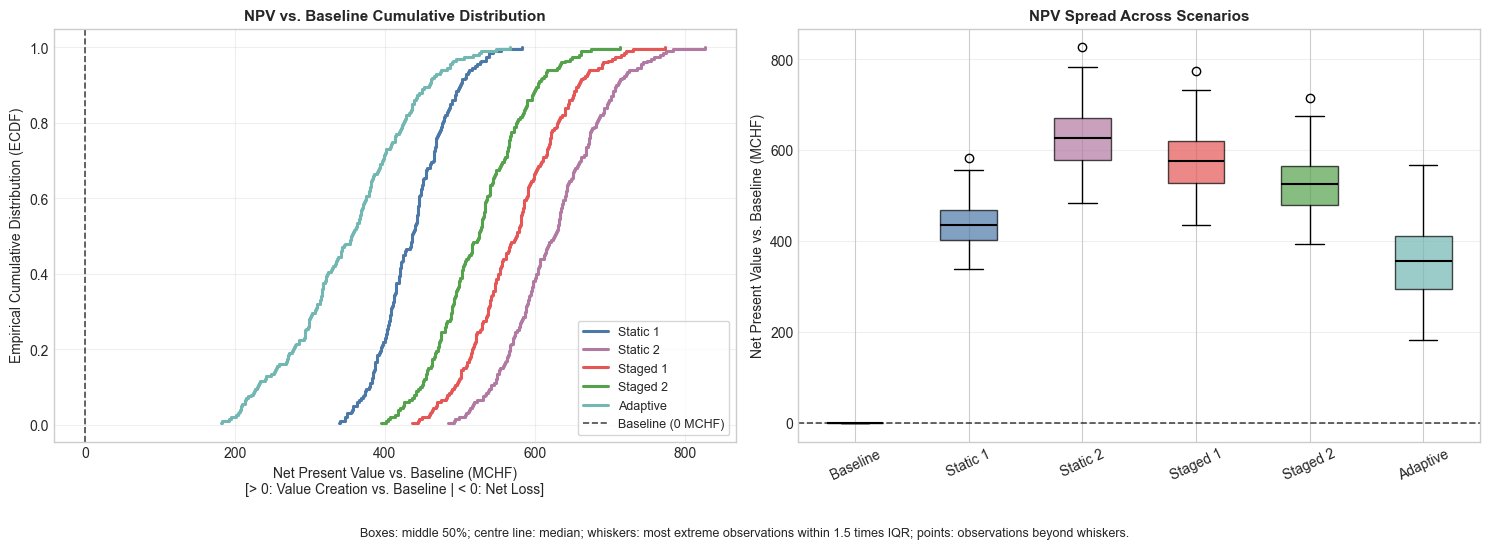

Plan Net Present Value (NPV) Performance Summary (MCHF vs. Baseline):


,Mean,Std,Median,p10,p25,p75,p90,IQR,positive_NPV_fraction
Baseline,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0
Static 1,436.95,47.75,436.05,379.77,403.44,468.15,500.16,64.71,1.0
Static 2,625.20,66.08,625.89,542.03,578.10,671.84,708.87,93.73,1.0
Staged 1,574.45,65.05,575.45,493.14,528.00,619.96,657.39,91.97,1.0
Staged 2,524.13,61.45,525.86,448.97,480.27,566.04,603.66,85.77,1.0
Adaptive,350.92,82.79,355.31,230.46,294.62,410.86,459.30,116.24,1.0


Positive-NPV fractions describe the sampled scenarios, conditional on their distributions.


In [9]:
# 1. Pairwise scenario Net Present Value (NPV) relative to baseline:
#    NPV_plan = NPC_baseline - NPC_plan  (> 0 means net societal benefit over doing nothing)
baseline_map = df[df['plan'] == 'baseline'].set_index('scenario')['NPC_total_MCHF']
df['NPV_MCHF'] = df['scenario'].map(baseline_map) - df['NPC_total_MCHF']
df['NPC_diff_baseline_MCHF'] = -df['NPV_MCHF']  # Kept for backward compatibility

diff_sorted = {}
for s in PLANS:
    sub = df[df['plan'] == s].sort_values('NPV_MCHF').reset_index(drop=True)
    sub['percentile'] = (sub.index + 1) / len(sub)
    diff_sorted[s] = sub

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# -----------------------------------------------------------------------------
# Panel 1: ECDF of Net Present Value vs. Baseline
# -----------------------------------------------------------------------------
for s in DISPLAY_PLANS:
    if s == 'baseline':
        continue  # The zero-reference line already represents the baseline.
    sub = diff_sorted[s]
    axes[0].step(sub['NPV_MCHF'], sub['percentile'], where='post',
                 label=plan_label(s), color=COLORS[s], linewidth=2.2)

axes[0].axvline(0, color='black', linestyle='--', linewidth=1.2, alpha=0.7, label='Baseline (0 MCHF)')
axes[0].set_xlabel('Net Present Value vs. Baseline (MCHF)\n[> 0: Value Creation vs. Baseline | < 0: Net Loss]', fontsize=10)
axes[0].set_ylabel('Empirical Cumulative Distribution (ECDF)', fontsize=10)
axes[0].set_title('NPV vs. Baseline Cumulative Distribution', fontsize=11, fontweight='bold')

# Use the observed NPV range, including zero, for both panels.
npv_values = df.loc[df.plan.isin(DISPLAY_PLANS), 'NPV_MCHF'].to_numpy(dtype=float)
npv_values = npv_values[np.isfinite(npv_values)]
npv_min = npv_values.min(initial=0.0)
npv_max = npv_values.max(initial=0.0)
padding = max((npv_max - npv_min) * 0.05, 1.0)
npv_limits = (npv_min - padding, npv_max + padding)
axes[0].set_xlim(npv_limits)
axes[0].legend(fontsize=9, loc='best', frameon=True)
axes[0].grid(alpha=0.3)

# -----------------------------------------------------------------------------
# Panel 2: Boxplot of NPV Spread Across Scenarios
# -----------------------------------------------------------------------------
npv_data = [df.loc[df['plan'] == s, 'NPV_MCHF'].values for s in DISPLAY_PLANS]
bp = axes[1].boxplot(npv_data, tick_labels=[plan_label(s) for s in DISPLAY_PLANS], patch_artist=True,
                     medianprops=dict(color='black', linewidth=1.5))

for patch, s in zip(bp['boxes'], DISPLAY_PLANS):
    patch.set_facecolor(COLORS[s])
    patch.set_alpha(0.7)

axes[1].axhline(0, color='black', linestyle='--', linewidth=1.2, alpha=0.7)
axes[1].set_ylabel('Net Present Value vs. Baseline (MCHF)', fontsize=10)
axes[1].set_title('NPV Spread Across Scenarios', fontsize=11, fontweight='bold')
axes[1].tick_params(axis='x', rotation=25)
axes[1].grid(axis='y', alpha=0.3)
axes[1].set_ylim(npv_limits)

fig.text(0.5, 0.015, 'Boxes: middle 50%; centre line: median; whiskers: most extreme observations within 1.5 times IQR; points: observations beyond whiskers.',
         ha='center', fontsize=9)
fig.tight_layout(rect=(0, 0.06, 1, 1))
save_figure(FIGURES_DIR / '05_npv_performance.png', dpi=150, bbox_inches='tight')
plt.show()

# -----------------------------------------------------------------------------
# 2. Performance Summary Table with Probability of Value Creation P(NPV > 0)
# -----------------------------------------------------------------------------
perf_summary = df.groupby('plan')['NPV_MCHF'].agg(
    Mean='mean',
    Std='std',
    Median='median',
    p10=lambda x: np.percentile(x, 10),
    p25=lambda x: np.percentile(x, 25),
    p75=lambda x: np.percentile(x, 75),
    p90=lambda x: np.percentile(x, 90),
    IQR=lambda x: np.percentile(x, 75) - np.percentile(x, 25),
    positive_NPV_fraction=lambda x: (x > 0).mean(),
).loc[PLANS]

perf_summary.index = [plan_label(s) for s in perf_summary.index]
print('Plan Net Present Value (NPV) Performance Summary (MCHF vs. Baseline):')
display(perf_summary.loc[[plan_label(plan) for plan in DISPLAY_PLANS]].round(2))
export_table(perf_summary, '05_npv_performance_summary', index=True)
print('Positive-NPV fractions describe the sampled scenarios, conditional on their distributions.')


## 2.2 NPV component breakdown (mandatory task)

Decompose the **Net Present Value (NPV)** relative to the baseline counterfactual into its core economic benefit and cost components across all 6 plans ($\text{NPV}_k = \text{NPC}_{k, \text{baseline}} - \text{NPC}_{k, \text{plan}}$):
- **Societal & User Benefits ($> 0\text{ MCHF}$)**: Car, cycling and walking time savings; PT in-vehicle, waiting, access, egress and transfer walking savings; capacity crowding relief; and reduced externalities (climate $\text{CO}_2$, air pollutants, noise, and traffic accidents).
- **Construction Climate Cost:** Physical construction emissions multiplied by the carbon value in their construction year, reported separately from operating road/rail emissions and from CAPEX.
- **Direct Project Costs ($< 0\text{ MCHF}$)**: Capital expenditure ($C_{\text{INV}}$) for Stage 1 (Connecting Stations A3, A4, A5) and Stage 2 (Core Tunnel & Winterthur Hub A0, A1, A2), alongside incremental operations & maintenance ($C_{\text{OP}}$).

The **terminal residual value** credits eligible construction capital with remaining service life at the end of the horizon.

This clarifies *why* plans differ: whether net economic value stems from avoiding capital lock-in by deferring investments, lower ongoing operating costs, or substantial reductions in passenger travel times and congestion.

Carbon costs use a common CHF/tonne value for car tailpipe emissions and rail electricity emissions. The reference value grows by calendar year. Annual outputs report car, rail and combined tonnes separately.

PT waiting, access/egress and transfer walking have separate CHF/person-hour values in `parameters.py`. Initial and transfer waiting use `C_TT_PT_WAITING`. Transfer walking uses `C_TT_PT_TRANSFER`.

The figures combine modelled and supplementary passengers (external flow) by benefit type: in-vehicle time with in-vehicle time, access with access, and crowding with crowding. Each passenger cohort is counted once. The detailed exports retain the cohort breakdown. When supplementary flows are disabled, the same figures report modelled passengers only.
The figure retains the main contributions and groups smaller entries as **Others**. The exported table retains every component. The displayed BCR is the ratio of ensemble mean benefits to ensemble mean net agency costs, not the mean of individual scenario ratios.


cell running: 00:00

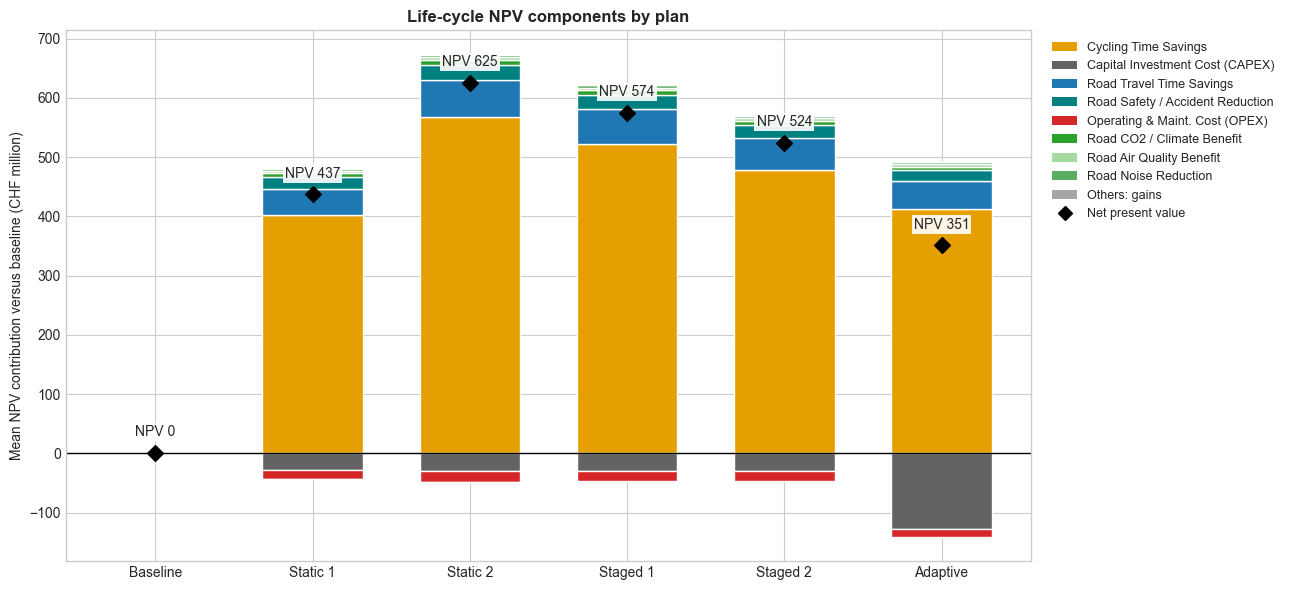

,Baseline,Static 1,Static 2,Staged 1,Staged 2,Adaptive
Road Travel Time Savings,0.0,43.92,63.39,59.24,53.85,47.70
Road CO2 / Climate Benefit,0.0,6.87,8.30,7.81,7.36,6.34
Road Noise Reduction,0.0,3.81,4.60,4.32,4.11,3.49
Road Air Quality Benefit,0.0,4.00,4.86,4.52,4.28,3.56
Road Safety / Accident Reduction,0.0,20.12,24.33,22.77,21.61,18.24
PT In-Vehicle Time Savings,0.0,0.00,0.00,0.00,0.00,0.00
PT Crowding Relief,0.0,0.00,0.00,0.00,0.00,0.00
PT Waiting Time Savings,0.0,0.00,0.00,0.00,0.00,0.00
Additional Rail CO2 Cost,0.0,0.00,0.00,0.00,0.00,0.00
Additional Rail Noise Cost,0.0,0.00,0.00,0.00,0.00,0.00


In [10]:
from textwrap import fill
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import pandas as pd
import numpy as np

# =============================================================================
# 1. COMPONENT MAPPING & PAIRWISE NPV DIFFERENCES
# =============================================================================
all_potential_comps = [
    'NPC_car_time_MCHF', 'NPC_car_co2_MCHF', 
    'NPC_car_noise_MCHF', 'NPC_car_air_MCHF', 'NPC_car_acc_MCHF',
    'NPC_pt_time_MCHF', 'NPC_pt_crowding_MCHF', 'NPC_pt_waiting_MCHF', 'NPC_pt_co2_MCHF', 
    'NPC_pt_noise_MCHF', 'NPC_pt_air_MCHF', 'NPC_pt_acc_MCHF', 
    'NPC_pt_access_MCHF', 'NPC_pt_egress_MCHF', 'NPC_pt_transfer_walk_MCHF',
    'NPC_bike_time_MCHF', 'NPC_walk_time_MCHF',
    'NPC_external_time_MCHF', 'NPC_external_delay_MCHF', 'NPC_external_crowding_MCHF',
    'NPC_inv_MCHF', 'NPC_op_MCHF', 'NPC_residual_MCHF', 'NPC_construction_co2_MCHF'
]

all_potential_comps += [c for c in ('NPC_bike_health_MCHF', 'NPC_walk_health_MCHF', 'NPC_pt_socioeconomic_MCHF')
                        if c in df.columns and df[c].ne(0).any()]
comp_cols = [c for c in all_potential_comps if c in df.columns]

# Pairwise scenario differences: NPV_k = NPC_k,baseline - NPC_k,plan
npv_comp_cols = []
for c in comp_cols:
    npv_col = c.replace('NPC_', 'NPV_')
    base_map = df[df['plan'] == 'baseline'].set_index('scenario')[c]
    df[npv_col] = df['scenario'].map(base_map) - df[c]
    npv_comp_cols.append(npv_col)

comp_labels = {
    'NPV_car_time_MCHF':    'Road Travel Time Savings',
    'NPV_pt_time_MCHF':     'PT In-Vehicle Time Savings',
    'NPV_pt_crowding_MCHF': 'PT Crowding Relief',
    'NPV_pt_waiting_MCHF':  'PT Waiting Time Savings',
    'NPV_pt_access_MCHF':   'PT Access Time Savings',
    'NPV_pt_egress_MCHF':   'PT Egress Time Savings',
    'NPV_pt_transfer_walk_MCHF': 'PT Transfer Walking Savings',
    'NPV_bike_time_MCHF':   'Cycling Time Savings',
    'NPV_walk_time_MCHF':   'Walking Time Savings',
    'NPV_bike_health_MCHF': 'Cycling Health Benefits',
    'NPV_walk_health_MCHF': 'Walking Health Benefits',
    'NPV_pt_socioeconomic_MCHF': 'Additional PT Socioeconomic Benefits',
    'NPV_external_time_MCHF': 'Supplementary Passenger Time Savings',
    'NPV_external_delay_MCHF': 'Supplementary Passenger Road Delay',
    'NPV_external_crowding_MCHF': 'Supplementary Passenger Crowding Relief',
    'NPV_car_co2_MCHF':     'Road CO2 / Climate Benefit',
    'NPV_car_noise_MCHF':   'Road Noise Reduction',
    'NPV_car_air_MCHF':     'Road Air Quality Benefit',
    'NPV_car_acc_MCHF':     'Road Safety / Accident Reduction',
    'NPV_pt_co2_MCHF':      'Additional Rail CO2 Cost',
    'NPV_pt_noise_MCHF':    'Additional Rail Noise Cost',
    'NPV_pt_air_MCHF':      'Additional Rail Air-Pollution Cost',
    'NPV_pt_acc_MCHF':      'Additional Rail Accident Cost',
    'NPV_construction_co2_MCHF': 'Construction CO2 Cost',
    'NPV_residual_MCHF':    'Terminal Residual Value',
    'NPV_inv_MCHF':         'Capital Investment Cost (CAPEX)',
    'NPV_op_MCHF':          'Operating & Maint. Cost (OPEX)',
}

# Thematic color families:
# Blues/Purples = User Time | Greens/Teals = Road Externalities | Olives/Pinks = Rail Externalities | Grays/Reds = Costs
comp_colors = {
    'NPV_car_time_MCHF':    '#1f77b4',   # Deep Blue
    'NPV_pt_time_MCHF':     '#3b528b',   # Navy Blue
    'NPV_pt_crowding_MCHF': '#665191',   # Violet
    'NPV_pt_waiting_MCHF':  '#7b3294',   # Purple
    'NPV_pt_access_MCHF':   '#8c6bb1',
    'NPV_pt_egress_MCHF':   '#9e9ac8',
    'NPV_pt_transfer_walk_MCHF': '#bcbddc',
    'NPV_bike_time_MCHF':   '#e69f00',
    'NPV_walk_time_MCHF':   '#cc79a7',
    'NPV_bike_health_MCHF': '#66a61e',
    'NPV_walk_health_MCHF': '#b2df8a',
    'NPV_pt_socioeconomic_MCHF': '#1b9e77',
    'NPV_external_time_MCHF': '#a6761d',
    'NPV_external_delay_MCHF': '#8c564b',
    'NPV_external_crowding_MCHF': '#bc80bd',
    'NPV_car_co2_MCHF':     '#2ca02c',   # Green
    'NPV_car_noise_MCHF':   '#5aae61',   # Sage Green
    'NPV_car_air_MCHF':     '#a6dba0',   # Pale Green
    'NPV_car_acc_MCHF':     '#008080',   # Teal
    'NPV_pt_co2_MCHF':      '#bcbd22',   # Olive
    'NPV_pt_noise_MCHF':    '#e377c2',   # Rose Pink
    'NPV_pt_air_MCHF':      '#17becf',   # Cyan
    'NPV_pt_acc_MCHF':      '#9edae5',   # Light Cyan
    'NPV_construction_co2_MCHF': '#8c564b',   # Brown
    'NPV_residual_MCHF':    '#b8860b',   # Gold
    'NPV_inv_MCHF':         '#636363',   # Slate Gray
    'NPV_op_MCHF':          '#d62728',   # Red
}

legend_handles = [mpatches.Patch(facecolor=comp_colors[c], label=comp_labels[c]) for c in npv_comp_cols]

# =============================================================================
# 2. COMPUTE MEAN NPV & MACRO-SUBTOTALS
# =============================================================================
mean_npv_comps = df.groupby('plan')[npv_comp_cols].mean().loc[PLANS]

# User Benefits (Travel + Wait Time)
user_time_cols = [c for c in [
    'NPV_car_time_MCHF', 'NPV_pt_time_MCHF', 'NPV_pt_crowding_MCHF', 'NPV_pt_waiting_MCHF',
    'NPV_pt_access_MCHF', 'NPV_pt_egress_MCHF', 'NPV_pt_transfer_walk_MCHF',
    'NPV_bike_time_MCHF', 'NPV_walk_time_MCHF',
    'NPV_external_time_MCHF', 'NPV_external_delay_MCHF', 'NPV_external_crowding_MCHF',
] if c in mean_npv_comps.columns]
# Externalities (Environment, Safety and Optional Health/Socioeconomic Benefits)
externality_cols = [c for c in [
    f'NPV_{mode}_{effect}_MCHF'
    for mode in ('car', 'pt') for effect in ('co2', 'noise', 'air', 'acc')
] + ['NPV_construction_co2_MCHF', 'NPV_bike_health_MCHF', 'NPV_walk_health_MCHF',
     'NPV_pt_socioeconomic_MCHF'] if c in mean_npv_comps.columns]
# Net agency costs: construction and operations less terminal residual value.
cost_cols = [c for c in ['NPV_inv_MCHF', 'NPV_op_MCHF', 'NPV_residual_MCHF'] if c in mean_npv_comps.columns]

total_mean_npv = mean_npv_comps.sum(axis=1)
assert np.allclose(total_mean_npv, df.groupby('plan')['NPV_MCHF'].mean().loc[PLANS]), \
    'The component breakdown must include every monetized cost exactly once.' 

# Modelled and supplementary passengers share the same benefit categories.
report_components, supplementary_components = combined_time_components(df, traj_df, npv_comp_cols)
report_component_cols = report_components.columns.tolist()
mean_report_components = report_components.groupby(df.plan).mean().loc[PLANS]
export_table(df[["scenario", "plan"] + npv_comp_cols], "05_npv_components_by_cohort", index=False)
if not supplementary_components.empty:
    export_table(pd.concat([df[["scenario", "plan"]], supplementary_components], axis=1),
                 "05_supplementary_time_components", index=False)

# Show the largest combined components separately; preserve all components in the table.
MAX_COMPONENTS_IN_LEGEND = 8
COMPONENTS_TO_SHOW = None  # Or a list of NPV_*_MCHF columns from mean_report_components.
if COMPONENTS_TO_SHOW is None:
    materiality = mean_report_components.loc[DISPLAY_PLANS].abs().max().sort_values(ascending=False)
    visible_components = materiality[materiality > 1e-9].head(MAX_COMPONENTS_IN_LEGEND).index.tolist()
else:
    visible_components = list(COMPONENTS_TO_SHOW)
    unknown = set(visible_components) - set(report_component_cols)
    if unknown:
        raise ValueError(f"Unknown component columns: {sorted(unknown)}")
hidden_components = [column for column in report_component_cols if column not in visible_components]
plotted_components = mean_report_components[visible_components].copy()
plot_labels = {column: comp_labels[column] for column in visible_components}
plot_colors = {column: comp_colors[column] for column in visible_components}
if hidden_components:
    # Keep opposite signs visible instead of hiding cancellation inside Others.
    other = mean_report_components[hidden_components]
    for key, values, label, color in (
        ("other_gains", other.clip(lower=0).sum(axis=1), "Others: gains", "#a6a6a6"),
        ("other_costs", other.clip(upper=0).sum(axis=1), "Others: costs", "#d0d0d0"),
    ):
        if values.abs().max() > 1e-9:
            plotted_components[key] = values
            plot_labels[key], plot_colors[key] = label, color
assert np.allclose(plotted_components.sum(axis=1), total_mean_npv)

fig, ax = plt.subplots(figsize=(13, 6))
plotted_components.loc[DISPLAY_PLANS].rename(columns=plot_labels).plot(
    kind="bar", stacked=True, ax=ax, edgecolor="white", width=0.64,
    color=[plot_colors[column] for column in plotted_components], legend=False,
)
ax.scatter(range(len(DISPLAY_PLANS)), total_mean_npv.loc[DISPLAY_PLANS], color="black", s=65, marker="D", zorder=5)
for position, plan in enumerate(DISPLAY_PLANS):
    value = total_mean_npv.loc[plan]
    ax.annotate(f"NPV {value:,.0f}", (position, value), xytext=(0, 10),
                textcoords="offset points", ha="center", va="bottom", fontsize=10,
                bbox=dict(facecolor="white", edgecolor="none", alpha=.9, pad=1.5), zorder=6)
ax.axhline(0, color="black", linewidth=1)
ax.set_ylabel("Mean NPV contribution versus baseline (CHF million)")
ax.set_title("Life-cycle NPV components by plan", fontweight="bold")
ax.set_xticklabels([fill(plan_label(plan), 16) for plan in DISPLAY_PLANS], rotation=0)
ax.set_xlabel("")
handles = [mpatches.Patch(facecolor=plot_colors[column], label=plot_labels[column])
           for column in plotted_components]
handles.append(Line2D([0], [0], marker="D", color="none", markerfacecolor="black",
                      markersize=7, label="Net present value"))
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
fig.tight_layout()
save_figure(FIGURES_DIR / "05_npv_component_decomposition_mean.png")
plt.show()

# Detailed component values and subtotals remain available for interpretation.
table_df = mean_report_components.rename(columns=comp_labels).T
subtotals = pd.DataFrame({
    "User time and access benefits": mean_npv_comps[user_time_cols].sum(axis=1),
    "Net externality benefits": mean_npv_comps[externality_cols].sum(axis=1),
    "Net infrastructure costs (CAPEX + OPEX - residual)": mean_npv_comps[cost_cols].sum(axis=1),
    "Net present value": total_mean_npv,
    "Benefit-cost ratio": (mean_npv_comps[user_time_cols].sum(axis=1)
                           + mean_npv_comps[externality_cols].sum(axis=1))
                          / (-mean_npv_comps[cost_cols].sum(axis=1)).replace(0, np.nan),
}).T
full_display = pd.concat([table_df, subtotals])
full_display.columns = [plan_label(plan) for plan in full_display]
display(full_display.round(2).fillna("—"))
export_table(full_display, "05_npv_component_breakdown", index=True)
export_table(plotted_components.rename(columns=plot_labels), "05_npv_component_plot_groups", index=True)
export_table(pd.concat([df[["scenario", "plan"]], report_components], axis=1),
             "05_npv_components_by_benefit", index=False)


## 2.3 Component-level NPV ECDF (tutorial/supporting task)

While the mean stacked bar chart condenses performance into single summary numbers, it masks uncertainty spreads and tail risks. Two plans can have similar expected travel-time savings yet carry very different risk profiles under extreme demand or severe road congestion scenarios.

The ECDF grid below plots the cumulative probability distribution $F(x)$ for each **Net Present Value (NPV) component** relative to baseline ($\text{NPV}_k = \text{NPC}_{k, \text{baseline}} - \text{NPC}_{k, \text{plan}}$) across all 6 plans. Values $> 0\text{ MCHF}$ represent net societal benefits, while values $< 0\text{ MCHF}$ represent additional societal costs or project expenditures.
The components use the same combined passenger categories as Section 2.2.


cell running: 00:00

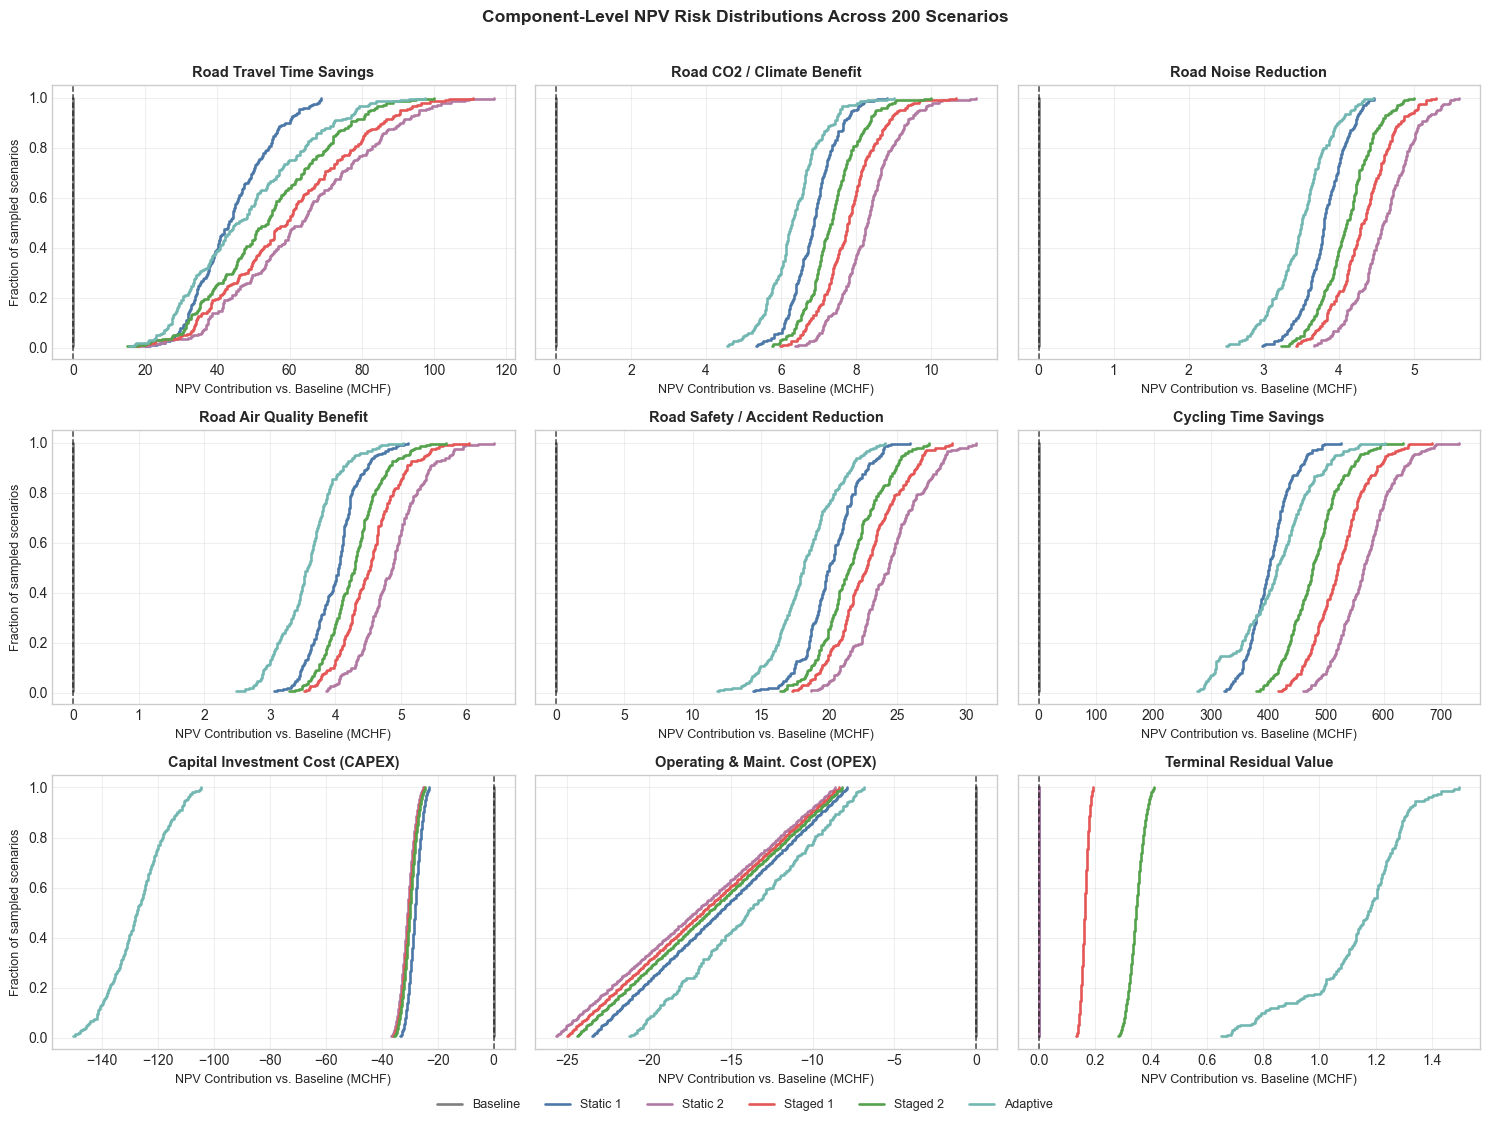

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# Use the same combined benefit categories as Section 2.2.
if "report_components" not in globals():
    raise RuntimeError("Run Section 2.2 before the component distributions.")
npv_cols = [column for column in report_component_cols if report_components[column].abs().max() > 1e-9]
npv_labels = comp_labels

# =============================================================================
# 2. PLOT COMPONENT-LEVEL ECDF GRID
# =============================================================================
if npv_cols:
    n_cols = 3
    n_rows = int(np.ceil(len(npv_cols) / n_cols))

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3.6 * n_rows), sharey=True)
    axes_flat = np.atleast_1d(axes).flatten()

    for i, (ax, col) in enumerate(zip(axes_flat, npv_cols)):
        for s in DISPLAY_PLANS:
            vals = np.sort(report_components.loc[df['plan'] == s, col].values)
            ecdf_y = np.arange(1, len(vals) + 1) / len(vals)
            ax.step(vals, ecdf_y, where='post', color=COLORS[s], label=plan_label(s), linewidth=1.9)
        
        # Zero baseline reference line (break-even against doing nothing)
        ax.axvline(0, color='black', linestyle='--', linewidth=1.1, alpha=0.7)
        
        ax.set_title(npv_labels.get(col, col), fontsize=10.5, fontweight='bold')
        ax.set_xlabel('NPV Contribution vs. Baseline (MCHF)', fontsize=9)
        if i % n_cols == 0:
            ax.set_ylabel('Fraction of sampled scenarios', fontsize=9)
        ax.grid(alpha=0.3)

    # Clean up empty subplots and use the first empty panel for a clean legend
    for j in range(len(npv_cols), len(axes_flat)):
        axes_flat[j].set_axis_off()
        
    # Place dedicated legend in the first unoccupied subplot
    if len(npv_cols) < len(axes_flat):
        legend_ax = axes_flat[len(npv_cols)]
        handles, labels = axes_flat[0].get_legend_handles_labels()
        legend_ax.legend(handles, labels, loc='center', fontsize=10, title="Investment Plans", 
                         title_fontsize=10.5, frameon=True)
    else:
        handles, labels = axes_flat[0].get_legend_handles_labels()
        fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, -0.02),
                   ncol=len(DISPLAY_PLANS), fontsize=9, frameon=False)

    plt.suptitle(f'Component-Level NPV Risk Distributions Across {df.scenario.nunique()} Scenarios', 
                 y=1.01, fontsize=12.5, fontweight='bold')
    plt.tight_layout()
    save_figure(FIGURES_DIR / '05_component_npv_ecdf_grid.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('Component columns not available in this dataset.')


## 2.4 Parallel-coordinates multi-dimensional performance (tutorial/supporting task)

Parallel coordinates show economic value and requirement protection across the same scenarios. Select the axes in the following cell. All axes place favourable observed values at the top; the exported ranges retain their physical units.

The median profiles describe **central performance**, not robustness or one realised scenario. Section 2.5 separately reports economic downside, regret and requirement attainment. Implementation dates are assessed through their economic consequences in Part 3.

Select displayed axes in `PARCOORD_COLS`. The indicator catalogue supplies units and default directions for ordinary mode outcomes, including cycling and walking. Section indicators are available only when configured.


cell running: 00:00

,indicator,label_and_unit,favourable_direction
0,NPV_MCHF,NPV versus baseline (CHF million),higher
1,pct_acceptable_years,Years meeting all requirements (%),higher
2,failure_years,Years failing any requirement,lower
3,delta_final_pt_share_pp,Final PT-share change (percentage points),higher
4,avoided_co2_tonnes,Avoided life-cycle CO2 (tonnes),higher
5,additional_expenditure_MCHF,"Additional CAPEX + OPEX (CHF million, discounted)",lower
6,final_pt_trips,Final PT trips (trips/peak hour),higher
7,final_bike_trips,Final Cycling trips (trips/peak hour),higher
8,final_walk_trips,Final Walking trips (trips/peak hour),higher
9,final_car_trips,Final Car trips (trips/peak hour),lower


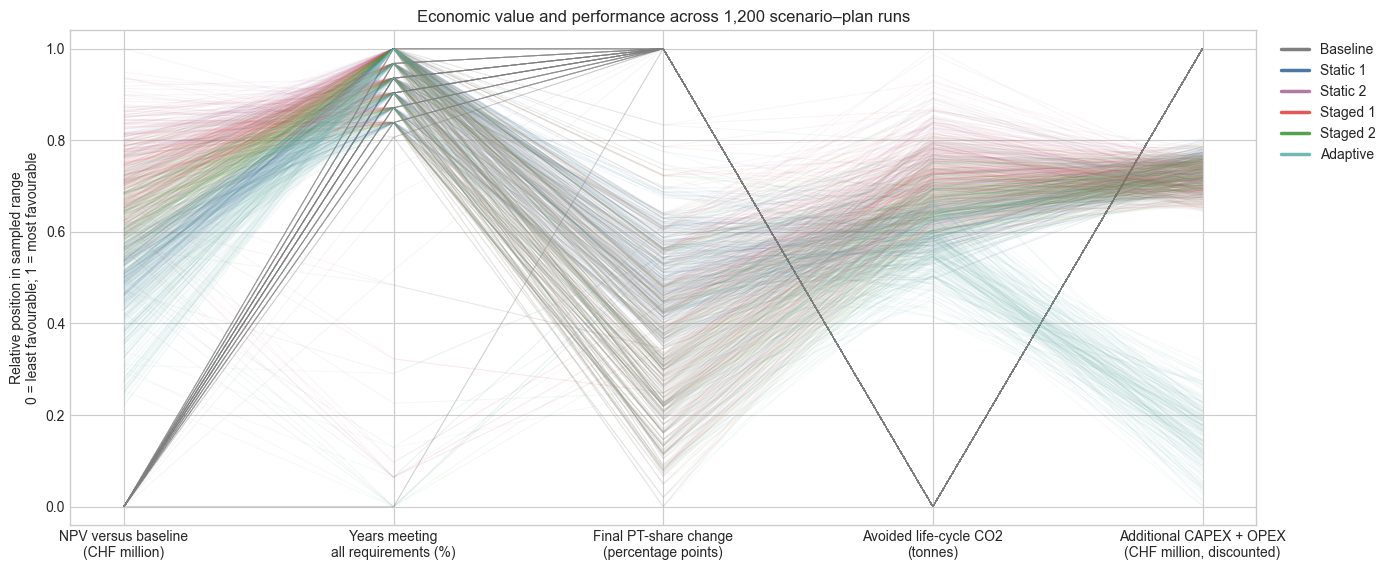

,indicator,favourable_direction,sample_minimum,sample_maximum
0,NPV_MCHF,higher,0.000000,826.221985
1,pct_acceptable_years,higher,22.500000,100.000000
2,delta_final_pt_share_pp,higher,-0.394795,0.000000
3,avoided_co2_tonnes,higher,0.000000,55748.551698
4,additional_expenditure_MCHF,lower,0.000000,167.943483


In [12]:
# Select displayed indicators and the favourable direction for each one.
PARCOORD_COLS = ["NPV_MCHF", "pct_acceptable_years", "delta_final_pt_share_pp",
                 "avoided_co2_tonnes", "additional_expenditure_MCHF"]
PARCOORD_DIRECTIONS = {
    "NPV_MCHF": "higher", "pct_acceptable_years": "higher",
    "failure_years": "lower", "delta_final_pt_share_pp": "higher",
    "avoided_co2_tonnes": "higher", "additional_expenditure_MCHF": "lower",
}
PARCOORD_LABELS_BY_COLUMN = {
    "NPV_MCHF": "NPV versus baseline\n(CHF million)",
    "pct_acceptable_years": "Years meeting\nall requirements (%)",
    "failure_years": "Years failing\nany requirement",
    "delta_final_pt_share_pp": "Final PT-share change\n(percentage points)",
    "avoided_co2_tonnes": "Avoided life-cycle CO2\n(tonnes)",
    "additional_expenditure_MCHF": "Additional CAPEX + OPEX\n(CHF million, discounted)",
}
for name, specification in ANNUAL_DISPLAY_INDICATORS.items():
    column = "final_" + name
    PARCOORD_DIRECTIONS.setdefault(column, specification["direction"])
    PARCOORD_LABELS_BY_COLUMN.setdefault(column,
        f'Final {specification["label"]}\n({specification["unit"]})')
baseline_rows = df.loc[df.plan.eq("baseline")].set_index("scenario")
if "final_pt_share" in df:
    df["delta_final_pt_share_pp"] = 100 * (df.final_pt_share - df.scenario.map(baseline_rows.final_pt_share))
if "total_co2_tonnes" in df:
    df["avoided_co2_tonnes"] = df.scenario.map(baseline_rows.total_co2_tonnes) - df.total_co2_tonnes
df["additional_expenditure_MCHF"] = sum(
    df[column] - df.scenario.map(baseline_rows[column])
    for column in ["NPC_inv_MCHF", "NPC_op_MCHF"]
)
unknown_columns = [column for column in PARCOORD_COLS if column not in df]
if unknown_columns:
    raise ValueError(f"Unavailable parallel-coordinate indicators: {unknown_columns}. Select columns from df.")
if any(PARCOORD_DIRECTIONS.get(column) not in ("higher", "lower") for column in PARCOORD_COLS):
    raise ValueError("Set higher or lower as the favourable direction for every selected indicator.")
unavailable = [column for column in PARCOORD_COLS if not np.isfinite(pd.to_numeric(df[column], errors="coerce")).all()]
if unavailable:
    raise ValueError(f"Indicators unavailable for some results: {unavailable}. Choose active indicators for this project.")
available_indicators = pd.DataFrame([
    {"indicator": column, "label_and_unit": label.replace("\n", " "),
     "favourable_direction": PARCOORD_DIRECTIONS[column]}
    for column, label in PARCOORD_LABELS_BY_COLUMN.items()
    if column in df and pd.to_numeric(df[column], errors="coerce").notna().any()
])
display(available_indicators)
export_table(available_indicators, "05_available_display_indicators")
parcoord_data = df[PARCOORD_COLS].apply(pd.to_numeric, errors="raise")
norm_bounds = {column: (parcoord_data[column].min(), parcoord_data[column].max()) for column in PARCOORD_COLS}

def normalize(data_frame):
    out = pd.DataFrame(index=data_frame.index)
    for column in PARCOORD_COLS:
        lo, hi = norm_bounds[column]
        values = (data_frame[column] - lo) / (hi - lo) if hi > lo else data_frame[column] * 0 + 0.5
        out[column] = 1 - values if PARCOORD_DIRECTIONS[column] == "lower" else values
    return out

norm_all = normalize(parcoord_data)
x_pos = np.arange(len(PARCOORD_COLS))
PARCOORD_LABELS = [PARCOORD_LABELS_BY_COLUMN.get(column, column.replace("_", " ")) for column in PARCOORD_COLS]
fig, ax = plt.subplots(figsize=(14, 5.8))
for plan in DISPLAY_PLANS:
    for _, row in norm_all.loc[df.plan.eq(plan)].iterrows():
        ax.plot(x_pos, row, color=COLORS[plan], alpha=0.07, linewidth=0.7)
for x in x_pos:
    ax.axvline(x, color="lightgray", linewidth=0.8, linestyle="--", zorder=0)
ax.set(xticks=x_pos, xticklabels=PARCOORD_LABELS, ylim=(-0.04, 1.04),
       ylabel="Relative position in sampled range\n0 = least favourable; 1 = most favourable",
       title=f"Economic value and performance across {len(df):,} scenario–plan runs")
handles = [plt.Line2D([0], [0], color=COLORS[plan], linewidth=2.5) for plan in DISPLAY_PLANS]
ax.legend(handles, [plan_label(plan) for plan in DISPLAY_PLANS], loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
save_figure(FIGURES_DIR / "05_parcoords_runs.png")
plt.show()
axis_definitions = pd.DataFrame([
    {"indicator": column, "favourable_direction": PARCOORD_DIRECTIONS[column],
     "sample_minimum": norm_bounds[column][0], "sample_maximum": norm_bounds[column][1]}
    for column in PARCOORD_COLS
])
display(axis_definitions)
export_table(axis_definitions, "05_parcoords_axes")
export_table(df[["scenario", "plan", *PARCOORD_COLS]], "05_parcoords_values")


cell running: 00:00

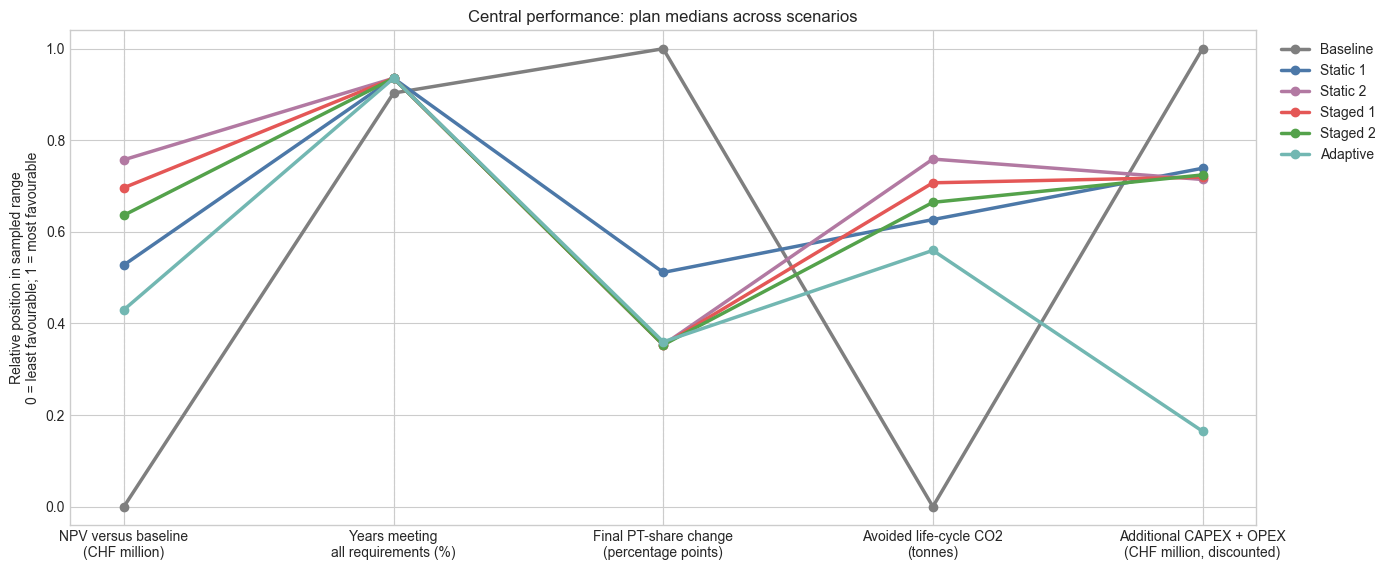

Each axis shows its own median. These profiles are not individual scenarios or a robustness score.


In [13]:
fig, ax = plt.subplots(figsize=(14, 5.8))
for plan in DISPLAY_PLANS:
    med = norm_all.loc[df.plan.eq(plan), PARCOORD_COLS].median()
    ax.plot(x_pos, med, color=COLORS[plan], linewidth=2.5, marker="o", label=plan_label(plan))
for x in x_pos:
    ax.axvline(x, color="lightgray", linewidth=0.8, linestyle="--", zorder=0)
ax.set(xticks=x_pos, xticklabels=PARCOORD_LABELS, ylim=(-0.04, 1.04),
       ylabel="Relative position in sampled range\n0 = least favourable; 1 = most favourable",
       title="Central performance: plan medians across scenarios")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
save_figure(FIGURES_DIR / "05_parcoords_plan_summary.png")
plt.show()
print("Each axis shows its own median. These profiles are not individual scenarios or a robustness score.")
export_table(df.groupby("plan")[PARCOORD_COLS].median().reindex(PLANS),
             "05_central_performance_medians", index=True)


## 2.5 Economic value, regret and requirement robustness (mandatory task)

**Economic regret** measures the opportunity cost of choosing plan $s$ in scenario $\omega$ compared with the best tested plan in hindsight:
$$\mathrm{Regret}(s,\omega)=\max_{s'}\mathrm{NPV}(s',\omega)-\mathrm{NPV}(s,\omega).$$

The baseline is included in this comparison. **Downside loss** is the amount by which NPV falls below zero. **Regret** is the gap to the best tested plan in the same scenario. A plan can reduce severe losses while forgoing benefits in favourable scenarios.

The mean loss below zero averages `max(−NPV, 0)` across all scenarios, including zero losses in profitable scenarios. Tail means average the worst configured fraction of the ensemble, separately for each plan and metric. Maximum sampled regret is the largest observed opportunity loss. It depends on the sample and is not a guarantee about scenarios outside it.

Report economic value alongside each requirement's attainment and failure duration. The joint comparison distinguishes positive NPV with requirements protected, economic success only, requirement protection only, and neither. These are separate dimensions, not an additive score. Fractions describe this sampled ensemble and depend on the selected scenario distributions.


In [14]:
# Tail measures average the worst ceil(TAIL_FRACTION × number of scenarios) values.
TAIL_FRACTION = 0.10
if not 0 < TAIL_FRACTION <= 1:
    raise ValueError("TAIL_FRACTION must be greater than 0 and no greater than 1.")

# Regret is the NPV forgone relative to the best available plan in the same scenario.
df["meets_targets"] = df["all_requirements_met"]
wide_npv = df.pivot(index="scenario", columns="plan", values="NPV_MCHF").reindex(columns=PLANS)
assert wide_npv.notna().all().all(), "Each scenario must evaluate every plan."
assert np.isfinite(wide_npv.to_numpy()).all(), "NPVs must be finite."
regret_wide = wide_npv.rsub(wide_npv.max(axis=1), axis=0)
assert (regret_wide.to_numpy() >= -1e-8).all()
tail_count = max(1, int(np.ceil(TAIL_FRACTION * len(wide_npv))))
tail_label = f"worst {100 * TAIL_FRACTION:g}%"
rob_rows = []
for plan in PLANS:
    vals, regrets = wide_npv[plan], regret_wide[plan]
    subset = df.loc[df.plan.eq(plan)]
    rob_rows.append({
        "plan": plan, "mean_NPV": vals.mean(), "median_NPV": vals.median(),
        "p10_NPV": vals.quantile(0.10), "p90_NPV": vals.quantile(0.90),
        "worst_NPV": vals.min(), "mean_regret": regrets.mean(),
        "median_regret": regrets.median(), "max_regret": regrets.max(),
        "positive_NPV_fraction": vals.gt(0).mean(),
        "negative_NPV_fraction": vals.lt(0).mean(),
        "expected_downside_loss": (-vals).clip(lower=0).mean(),
        "mean_worst_tail_NPV": vals.nsmallest(tail_count).mean(),
        "mean_worst_tail_regret": regrets.nlargest(tail_count).mean(),
        "tail_scenario_count": tail_count,
        "target_robustness": 100 * subset.all_requirements_met.mean(),
        "mean_failure_years": subset.failure_years.mean(),
        "joint_success_fraction": (subset.NPV_MCHF.gt(0) & subset.all_requirements_met).mean(),
    })
rob_df = pd.DataFrame(rob_rows).set_index("plan").reindex(PLANS)
print(f"Economic value, downside and regret (CHF million). Tail means use {tail_count} of {len(wide_npv)} scenarios per plan.")
value_and_risk = rob_df[["mean_NPV", "negative_NPV_fraction", "expected_downside_loss", "mean_worst_tail_NPV"]].copy()
value_and_risk["negative_NPV_fraction"] *= 100
display(value_and_risk.rename(columns={
    "mean_NPV": "Mean NPV", "negative_NPV_fraction": "Negative NPV (%)",
    "expected_downside_loss": "Mean loss below zero", "mean_worst_tail_NPV": f"Mean NPV: {tail_label}",
}).rename(index=plan_label).round(2))
display(rob_df[["mean_regret", "mean_worst_tail_regret", "max_regret"]].rename(columns={
    "mean_regret": "Mean regret", "mean_worst_tail_regret": f"Mean regret: {tail_label}",
    "max_regret": "Maximum sampled regret",
}).rename(index=plan_label).round(2))
protection_scorecard = rob_df[["target_robustness", "mean_failure_years", "joint_success_fraction"]].copy()
protection_scorecard["joint_success_fraction"] *= 100
display(protection_scorecard.rename(columns={
    "target_robustness": "All requirements met (%)", "mean_failure_years": "Mean failure years",
    "joint_success_fraction": "Positive NPV and requirements met (%)",
}).rename(index=plan_label).round(2))
export_table(rob_df, "05_economic_and_requirement_scorecard", index=True)
export_table(regret_wide, "05_paired_economic_regret", index=True)

requirement_rows = []
for requirement in ACTIVE_REQUIREMENTS:
    for plan in PLANS:
        subset = df.loc[df.plan.eq(plan)]
        requirement_rows.append({
            "plan": plan, "requirement": requirement["label"],
            "scenarios_meeting_requirement_percent": 100 * (~subset[f'{requirement["id"]}_failed']).mean(),
            "mean_failure_years": subset[f'{requirement["id"]}_failure_years'].mean(),
        })
requirement_scorecard = pd.DataFrame(requirement_rows)
if not requirement_scorecard.empty:
    display(requirement_scorecard.round(2))
    export_table(requirement_scorecard, "05_requirement_protection")


cell running: 00:00

Economic value, downside and regret (CHF million). Tail means use 20 of 200 scenarios per plan.


,Mean NPV,Negative NPV (%),Mean loss below zero,Mean NPV: worst 10%
plan,,,,
Baseline,0.00,0.0,0.0,0.00
Static 1,436.95,0.0,0.0,360.09
Static 2,625.20,0.0,0.0,517.22
Staged 1,574.45,0.0,0.0,468.33
Staged 2,524.13,0.0,0.0,424.37
Adaptive,350.92,0.0,0.0,209.23


,Mean regret,Mean regret: worst 10%,Maximum sampled regret
plan,,,
Baseline,625.20,744.54,826.22
Static 1,188.25,221.16,242.88
Static 2,0.00,0.00,0.00
Staged 1,50.74,52.75,53.39
Staged 2,101.06,109.40,113.10
Adaptive,274.28,317.22,336.51


,All requirements met (%),Mean failure years,Positive NPV and requirements met (%)
plan,,,
Baseline,10.0,3.63,0.0
Static 1,33.5,2.48,33.5
Static 2,34.0,2.37,34.0
Staged 1,34.0,2.37,34.0
Staged 2,33.5,2.44,33.5
Adaptive,33.5,2.48,33.5


,plan,requirement,scenarios_meeting_requirement_percent,mean_failure_years
0,baseline,"bike_share_trips > 0.16, Years 10–40",89.0,1.26
1,static1,"bike_share_trips > 0.16, Years 10–40",97.5,0.65
2,static2,"bike_share_trips > 0.16, Years 10–40",97.5,0.56
3,staged1,"bike_share_trips > 0.16, Years 10–40",97.5,0.56
4,staged2,"bike_share_trips > 0.16, Years 10–40",97.5,0.60
5,flexible,"bike_share_trips > 0.16, Years 10–40",97.5,0.65
6,baseline,"bike_share > 0.1, Years 10–40",53.0,1.62
7,static1,"bike_share > 0.1, Years 10–40",99.0,0.23
8,static2,"bike_share > 0.1, Years 10–40",99.5,0.10
9,staged1,"bike_share > 0.1, Years 10–40",99.5,0.10


cell running: 00:00

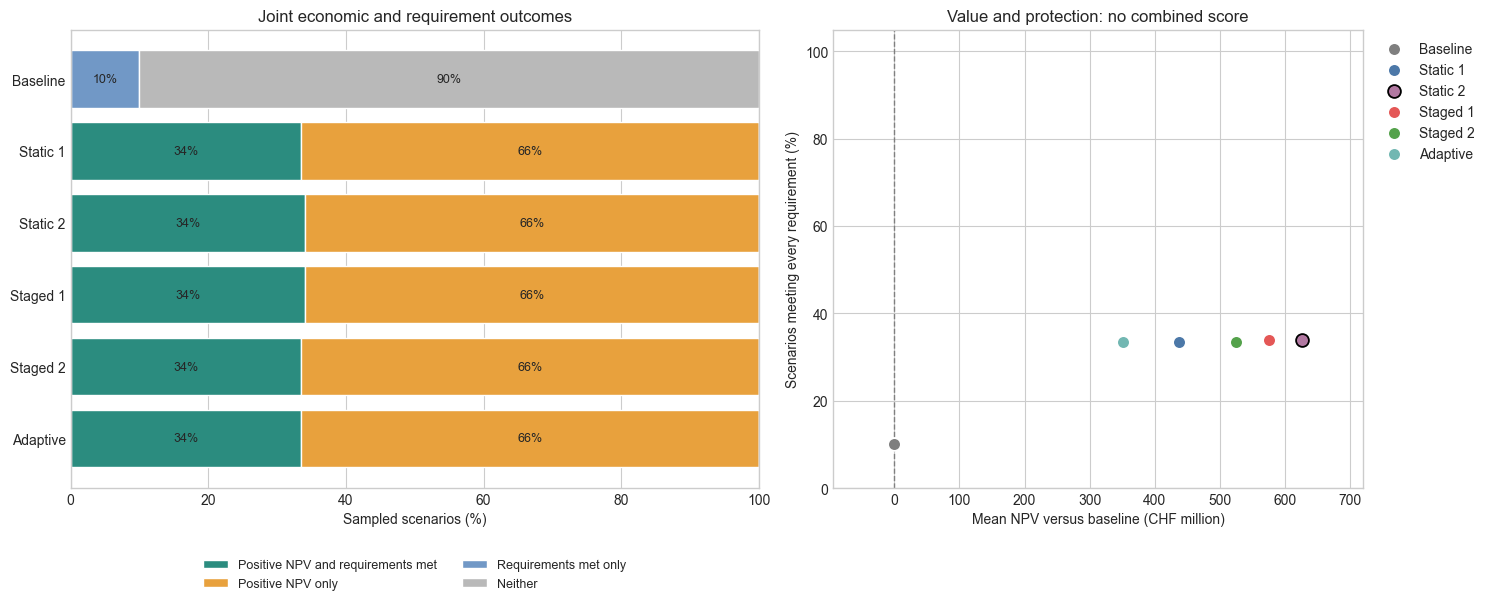

Black-outlined points are not dominated on these two aggregate measures; this is not a complete ranking.
Baseline NPV is zero: it is a neutral economic reference, not a negative-NPV investment.


In [15]:
# Report economic value and policy requirements separately, then show their overlap.
joint_categories = ["Positive NPV and requirements met", "Positive NPV only",
                    "Requirements met only", "Neither"]
joint_colors = ["#2b8c7f", "#e8a13d", "#7198c6", "#b9b9b9"]
joint_rows = []
for plan in PLANS:
    subset = df.loc[df.plan.eq(plan)]
    positive, protected = subset.NPV_MCHF.gt(0), subset.all_requirements_met
    counts = [(positive & protected).mean(), (positive & ~protected).mean(),
              (~positive & protected).mean(), (~positive & ~protected).mean()]
    joint_rows.append({"plan": plan, **{key: 100 * value for key, value in zip(joint_categories, counts)}})
joint_outcomes = pd.DataFrame(joint_rows).set_index("plan").reindex(PLANS)
assert np.allclose(joint_outcomes.sum(axis=1), 100)
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1.3, 1]})
xs = np.arange(len(DISPLAY_PLANS))
left = np.zeros(len(DISPLAY_PLANS))
for category, color in zip(joint_categories, joint_colors):
    values = joint_outcomes.loc[DISPLAY_PLANS, category].to_numpy()
    axes[0].barh(xs, values, left=left, label=category, color=color, edgecolor="white")
    for y, value, offset in zip(xs, values, left):
        if value >= 8:
            axes[0].text(offset + value / 2, y, f"{value:.0f}%", ha="center", va="center", fontsize=9)
    left += values
axes[0].set(yticks=xs, yticklabels=[plan_label(plan) for plan in DISPLAY_PLANS], xlim=(0, 100),
            xlabel="Sampled scenarios (%)", title="Joint economic and requirement outcomes")
axes[0].invert_yaxis()
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, fontsize=9)
for i, plan in enumerate(DISPLAY_PLANS):
    row = rob_df.loc[plan]
    dominated = ((rob_df.mean_NPV >= row.mean_NPV) & (rob_df.target_robustness >= row.target_robustness)
                 & ((rob_df.mean_NPV > row.mean_NPV) | (rob_df.target_robustness > row.target_robustness))).any()
    axes[1].scatter(row.mean_NPV, row.target_robustness, color=COLORS[plan], s=85,
                    edgecolor="black" if not dominated else "white", linewidth=1.3, zorder=3, label=plan_label(plan))
axes[1].axvline(0, color="gray", linestyle="--", linewidth=1)
axes[1].set(xlabel="Mean NPV versus baseline (CHF million)",
            ylabel="Scenarios meeting every requirement (%)", ylim=(0, 105),
            title="Value and protection: no combined score")
axes[1].margins(x=0.15)
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, fontsize=10)
fig.tight_layout()
fig.subplots_adjust(bottom=0.24)
save_figure(FIGURES_DIR / "05_joint_value_and_requirement_outcomes.png")
plt.show()
print("Black-outlined points are not dominated on these two aggregate measures; this is not a complete ranking.")
export_table(joint_outcomes, "05_joint_value_requirement_outcomes", index=True)

print("Baseline NPV is zero: it is a neutral economic reference, not a negative-NPV investment.")


cell running: 00:00

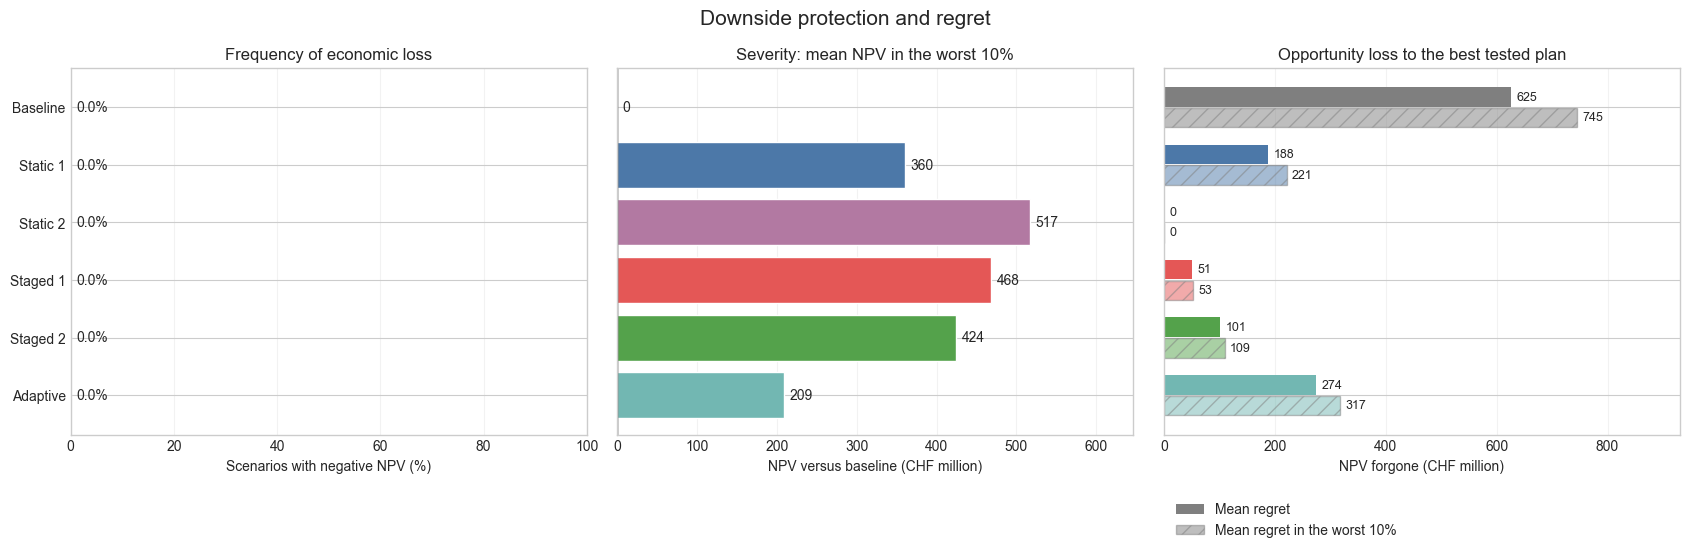

Lower loss frequency and regret are favourable; a higher worst-tail NPV indicates milder economic losses.
Each tail is selected separately for its plan and metric. It is not a common set of adverse scenarios.


In [16]:
# Compare frequency, severity and opportunity loss without combining them into a score.
fig, risk_axes = plt.subplots(1, 3, figsize=(17, max(5.5, 0.7 * len(DISPLAY_PLANS) + 1.4)), sharey=True)
risk_y = np.arange(len(DISPLAY_PLANS))
risk_values = rob_df.loc[DISPLAY_PLANS]
risk_colors = [COLORS[plan] for plan in DISPLAY_PLANS]
risk_axes[0].barh(risk_y, 100 * risk_values.negative_NPV_fraction, color=risk_colors, edgecolor="white")
risk_axes[0].set(title="Frequency of economic loss", xlabel="Scenarios with negative NPV (%)", xlim=(0, 100))
risk_axes[1].barh(risk_y, risk_values.mean_worst_tail_NPV, color=risk_colors, edgecolor="white")
risk_axes[1].axvline(0, color="black", linewidth=1)
risk_axes[1].set(title=f"Severity: mean NPV in the {tail_label}", xlabel="NPV versus baseline (CHF million)")
risk_axes[2].barh(risk_y - 0.18, risk_values.mean_regret, height=0.34, color=risk_colors, label="Mean regret")
risk_axes[2].barh(risk_y + 0.18, risk_values.mean_worst_tail_regret, height=0.34, color=risk_colors,
                  alpha=0.5, hatch="//", edgecolor="gray", label=f"Mean regret in the {tail_label}")
risk_axes[2].set(title="Opportunity loss to the best tested plan", xlabel="NPV forgone (CHF million)")
risk_axes[2].legend(loc="upper left", bbox_to_anchor=(0, -0.15), fontsize=10)
# Labels show both the loss frequency and the monetary magnitude.
for y, value in zip(risk_y, 100 * risk_values.negative_NPV_fraction):
    risk_axes[0].annotate(f"{value:.1f}%", (value, y), xytext=(-4 if value > 90 else 4, 0),
                          textcoords="offset points", va="center", ha="right" if value > 90 else "left", fontsize=10)
for y, value in zip(risk_y, risk_values.mean_worst_tail_NPV):
    risk_axes[1].annotate(f"{value:,.0f}", (value, y), xytext=(-4 if value < 0 else 4, 0),
                          textcoords="offset points", va="center", ha="right" if value < 0 else "left", fontsize=10)
for offset, column in ((-.18, "mean_regret"), (.18, "mean_worst_tail_regret")):
    for y, value in zip(risk_y + offset, risk_values[column]):
        risk_axes[2].annotate(f"{value:,.0f}", (value, y), xytext=(4, 0),
                              textcoords="offset points", va="center", fontsize=9)
risk_axes[1].margins(x=.25)
risk_axes[2].margins(x=.25)
risk_axes[0].set_yticks(risk_y, [plan_label(plan) for plan in DISPLAY_PLANS])
risk_axes[0].invert_yaxis()
for risk_ax in risk_axes:
    risk_ax.grid(axis="x", alpha=0.25)
    risk_ax.set_axisbelow(True)
fig.suptitle("Downside protection and regret", fontsize=15)
fig.tight_layout()
fig.subplots_adjust(bottom=0.22)
save_figure(FIGURES_DIR / "05_downside_and_regret.png")
plt.show()
print("Lower loss frequency and regret are favourable; a higher worst-tail NPV indicates milder economic losses.")
print("Each tail is selected separately for its plan and metric. It is not a common set of adverse scenarios.")


### 2.5.1 Reading regret and robustness

Regret — "how much worse off am I, for this particular scenario, than if I'd picked the best plan for that exact scenario?"

For each sampled scenario (one joint draw of the selected scenario uncertainties — i.e. one hypothetical 40-year future), every plan is evaluated against that same scenario and produces an NPV relative to its baseline. Regret is zero where a plan is the best choice, and positive elsewhere: it is the opportunity cost of not knowing the future in advance.

Robustness — the broader property of performing acceptably across the whole range of plausible scenarios, not just doing well on average or in one assumed future.

Mean NPV depends on the chosen scenario distributions. Regret and target robustness complement it by showing how plans perform in adverse scenarios when those probabilities are uncertain.
A plan is non-dominated in the displayed mean-NPV/requirement-protection comparison when no other plan is at least as good on both and strictly better on one. This is a trade-off screen, not an automatic recommendation.

Use the tables and figures together: a strategy can have fewer severe losses and lower extreme regret, yet lower mean NPV or more frequent small losses. The upfront adaptive premium can remain a cost even when construction is avoided. Report these trade-offs alongside requirement protection; neither economic risk nor regret replaces the planning objectives.


# Part 3 — Understand the value and price of waiting

Adaptive implementation can defer or avoid expenditure, but also defer or forgo benefits. Compare the adaptive plan with a fixed schedule under the **same scenario**. The comparator plans are selected once in the display settings in Part 1.

Positive paired contributions favour the adaptive plan. Savings may come from later implementation or from packages that never open within the horizon.


In [17]:
WAITING_FOCUS_PLAN = ADAPTIVE_PLAN
WAITING_COMPARATORS = COMPARISON_PLANS.copy()
WAITING_AVAILABLE = WAITING_FOCUS_PLAN is not None and bool(WAITING_COMPARATORS)
if not WAITING_AVAILABLE:
    print("Select an adaptive plan and comparator plans in the display settings to show paired waiting analyses.")
else:
    if WAITING_FOCUS_PLAN not in PLANS or not WAITING_COMPARATORS:
        raise ValueError("Select an available focus plan and at least one comparator.")
    if any(plan not in PLANS or plan == WAITING_FOCUS_PLAN for plan in WAITING_COMPARATORS):
        raise ValueError("Comparators must be available plans different from the focus plan.")
    waiting_groups = {
        "CAPEX": ["NPV_inv_MCHF"],
        "OPEX": ["NPV_op_MCHF"],
        "Residual value": ["NPV_residual_MCHF"],
        "Time and access": [column for column in user_time_cols if column in report_component_cols and "crowding" not in column],
        "Crowding": [column for column in user_time_cols if column in report_component_cols and "crowding" in column],
        "Other effects": externality_cols,
    }
    assert sorted(column for columns in waiting_groups.values() for column in columns) == sorted(report_component_cols)
    waiting_data = df.drop(columns=npv_comp_cols).join(report_components)
    focus = waiting_data.loc[waiting_data.plan.eq(WAITING_FOCUS_PLAN)].set_index("scenario")
    waiting_records, waiting_summary_rows = [], []
    for comparator in WAITING_COMPARATORS:
        comparison = waiting_data.loc[waiting_data.plan.eq(comparator)].set_index("scenario").reindex(focus.index)
        if comparison.NPV_MCHF.isna().any():
            raise ValueError("Waiting comparisons require the same scenarios for both plans.")
        paired = pd.DataFrame({"scenario": focus.index, "focus_plan": WAITING_FOCUS_PLAN, "comparator": comparator}).set_index("scenario")
        for label, columns in waiting_groups.items():
            paired[label] = focus[columns].sum(axis=1) - comparison[columns].sum(axis=1)
        paired["NPV_difference_MCHF"] = focus.NPV_MCHF - comparison.NPV_MCHF
        paired["expenditure_saving_MCHF"] = paired.CAPEX + paired.OPEX
        paired["extra_failure_years"] = focus.failure_years - comparison.failure_years
        paired["focus_meets_requirements"] = focus.all_requirements_met
        paired["comparator_meets_requirements"] = comparison.all_requirements_met
        assert np.allclose(paired[list(waiting_groups)].sum(axis=1), paired.NPV_difference_MCHF)
        waiting_records.append(paired.reset_index())
        waiting_summary_rows.append({
            "comparator": comparator, **paired[list(waiting_groups)].mean().to_dict(),
            "NPV_difference_MCHF": paired.NPV_difference_MCHF.mean(),
            "expenditure_saving_MCHF": paired.expenditure_saving_MCHF.mean(),
            "extra_failure_years": paired.extra_failure_years.mean(),
            "fraction_higher_NPV": paired.NPV_difference_MCHF.gt(0).mean(),
            "fraction_cheaper_without_extra_failure": (paired.expenditure_saving_MCHF.ge(0) & paired.extra_failure_years.le(0)).mean(),
        })
    waiting_pairs = pd.concat(waiting_records, ignore_index=True)
    waiting_summary = pd.DataFrame(waiting_summary_rows).set_index("comparator")
    print("Mean paired component differences across all scenarios (CHF million):")
    display(waiting_summary.round(2).rename(index=plan_label))
    export_table(waiting_pairs, "05_waiting_paired_differences")
    export_table(waiting_summary, "05_waiting_summary", index=True)

    # Separate non-implementation and commitments from pure deferral.
    opening_columns = [column for column in ["stage1_opening_year", "stage2_opening_year"] if column in focus]
    scheduled_columns = [column for column in ["stage1_scheduled_opening_year", "stage2_scheduled_opening_year"] if column in focus]
    if opening_columns:
        opened = focus[opening_columns].gt(0) & focus[opening_columns].le(N_YEARS)
        implementation = pd.DataFrame({"packages_opened_within_horizon": opened.sum(axis=1),
                                       "NPV_MCHF": focus.NPV_MCHF})
        if scheduled_columns:
            implementation["committed_packages_opening_after_horizon"] = focus[scheduled_columns].gt(N_YEARS).sum(axis=1)
        implementation_summary = implementation.groupby("packages_opened_within_horizon").agg(
            scenario_count=("NPV_MCHF", "size"), mean_NPV_MCHF=("NPV_MCHF", "mean"))
        display(implementation_summary.round(1))
        if scheduled_columns:
            print(f"{implementation.committed_packages_opening_after_horizon.sum():.0f} committed package openings occur after Year {N_YEARS}.")
        export_table(implementation.reset_index(), "05_waiting_implementation_status")
        export_table(implementation_summary, "05_waiting_implementation_summary", index=True)


cell running: 00:00

Mean paired component differences across all scenarios (CHF million):


,CAPEX,OPEX,Residual value,Time and access,Crowding,Other effects,NPV_difference_MCHF,expenditure_saving_MCHF,extra_failure_years,fraction_higher_NPV,fraction_cheaper_without_extra_failure
comparator,,,,,,,,,,,
Staged 1,-97.10,2.78,0.97,-122.39,0.0,-7.79,-223.54,-94.33,0.12,0.0,0.0
Static 2,-96.67,3.22,1.13,-171.49,0.0,-10.47,-274.28,-93.46,0.12,0.0,0.0


,scenario_count,mean_NPV_MCHF
packages_opened_within_horizon,,
1,29,219.5
2,171,373.2


4 committed package openings occur after Year 40.


## 3.1 Savings, economic value and objective protection (mandatory)

The left panel distinguishes expenditure savings from additional years of requirement failure. The right panel tests whether those same scenarios gain or lose NPV after accounting for forgone benefits. Every point compares the same scenario under two plans. An extra failure year counts once even if several requirements fail in it.

**Task:** In which scenarios is waiting economical without weakening protection? Where does saving money forgo more benefit than it saves? Use the component table to explain the difference. Requirement protection is reported alongside NPV.
The component table above this section reports **averages across scenarios**. The scenario explorer below the figure identifies individual cases and shows their component differences and applied final-year inputs.

Select `SCENARIO_COMPARATOR` and `SCENARIO_FILTER`, then optionally enter an ID in `SELECTED_SCENARIO`. Here, “economical without weakening protection” means **higher NPV and no new requirement failure in any applicable year**. It does not mean that both plans meet every requirement: both can share an existing shortfall. This check prevents an improvement in one year or objective from hiding a new failure elsewhere.


cell running: 00:00

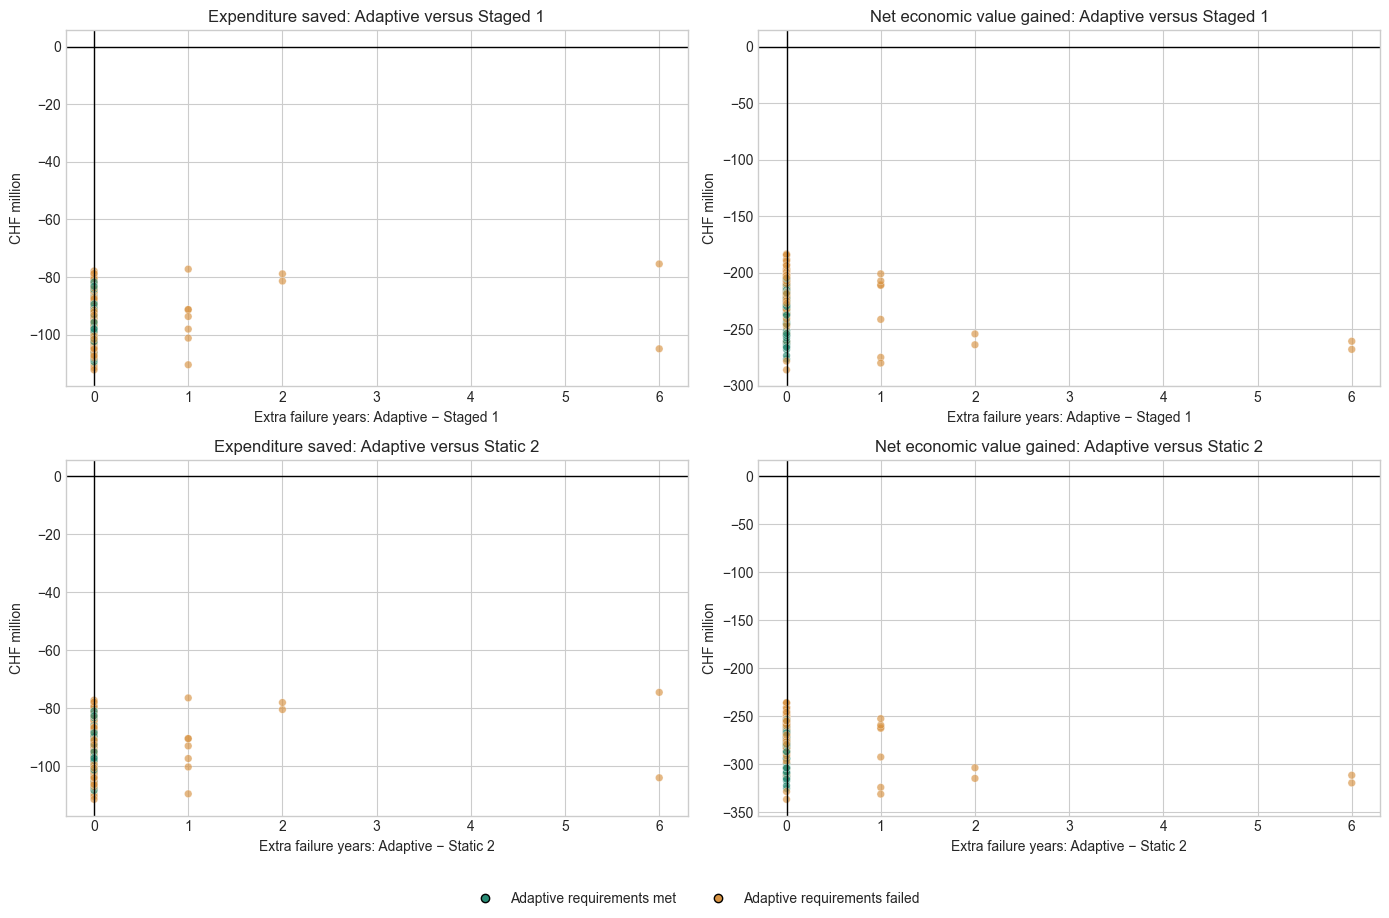

In [18]:
if WAITING_AVAILABLE:
    fig, axes = plt.subplots(len(WAITING_COMPARATORS), 2, figsize=(14, 4.6 * len(WAITING_COMPARATORS)), squeeze=False)
    for row, comparator in enumerate(WAITING_COMPARATORS):
        paired = waiting_pairs.loc[waiting_pairs.comparator.eq(comparator)]
        for ax, column, title in (
            (axes[row, 0], "expenditure_saving_MCHF", "Expenditure saved"),
            (axes[row, 1], "NPV_difference_MCHF", "Net economic value gained"),
        ):
            ax.scatter(paired.extra_failure_years, paired[column], c=paired.focus_meets_requirements.map({True: "#298c75", False: "#d89342"}),
                       alpha=0.65, s=30, edgecolors="white", linewidths=0.3)
            ax.axhline(0, color="black", linewidth=1)
            ax.axvline(0, color="black", linewidth=1)
            ax.set(xlabel=f"Extra failure years: {plan_label(WAITING_FOCUS_PLAN)} − {plan_label(comparator)}",
                   ylabel="CHF million", title=f"{title}: {plan_label(WAITING_FOCUS_PLAN)} versus {plan_label(comparator)}")
    handles = [plt.Line2D([0], [0], color="none", marker="o", markerfacecolor=color, label=label)
               for color, label in (("#298c75", plan_label(WAITING_FOCUS_PLAN) + " requirements met"), ("#d89342", plan_label(WAITING_FOCUS_PLAN) + " requirements failed"))]
    fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False)
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    save_figure(FIGURES_DIR / "05_waiting_value_protection_tradeoffs.png")
    plt.show()


In [19]:
# Select a comparator, a question and (optionally) a specific scenario to inspect.
SCENARIO_COMPARATOR = WAITING_COMPARATORS[0] if WAITING_COMPARATORS else None
SCENARIO_FILTER = "higher_npv_no_new_failure"
# Other filters: "saving_but_lower_npv", "new_requirement_failures", "all".
SELECTED_SCENARIO = None  # A scenario ID, or None for the first matching scenario.
SCENARIOS_TO_SHOW = 10

if WAITING_AVAILABLE:
    if SCENARIO_COMPARATOR not in WAITING_COMPARATORS:
        raise ValueError("Select SCENARIO_COMPARATOR from WAITING_COMPARATORS (Part 1.2).")
    if not isinstance(SCENARIOS_TO_SHOW, int) or SCENARIOS_TO_SHOW < 1:
        raise ValueError("SCENARIOS_TO_SHOW must be a positive whole number.")

    # Compare every requirement in the same year; fewer failures elsewhere cannot offset a new one.
    failure_flags = ~requirement_tests(traj_df)
    failure_flags.index = pd.MultiIndex.from_frame(traj_df[["scenario", "plan", "year"]])
    focus_failures = failure_flags.xs(WAITING_FOCUS_PLAN, level="plan").sort_index()
    scenario_comparisons = []
    for comparator in WAITING_COMPARATORS:
        other_failures = failure_flags.xs(comparator, level="plan").reindex(focus_failures.index)
        if other_failures.isna().any().any():
            raise ValueError("Scenario inspection requires matching annual rows for both plans.")
        new_failures = focus_failures & ~other_failures
        paired = waiting_pairs.loc[waiting_pairs.comparator.eq(comparator)].copy().set_index("scenario")
        paired["new_failure_years"] = new_failures.any(axis=1).groupby(level="scenario").sum()
        for rule in ACTIVE_REQUIREMENTS:
            paired[rule["id"] + "_new_failure_years"] = new_failures[rule["id"]].groupby(level="scenario").sum()
        paired["higher_npv_no_new_failure"] = paired.NPV_difference_MCHF.gt(0) & paired.new_failure_years.eq(0)
        paired["saving_but_lower_npv"] = paired.expenditure_saving_MCHF.gt(0) & paired.NPV_difference_MCHF.lt(0)
        paired["new_requirement_failures"] = paired.new_failure_years.gt(0)
        scenario_comparisons.append(paired.reset_index())
    waiting_scenario_details = pd.concat(scenario_comparisons, ignore_index=True)
    export_table(waiting_scenario_details, "05_waiting_scenario_diagnostics")

    filter_labels = {
        "higher_npv_no_new_failure": "Higher NPV without new requirement failures",
        "saving_but_lower_npv": "Expenditure saved, but lower NPV",
        "new_requirement_failures": "At least one new requirement failure",
        "all": "All scenarios",
    }
    if SCENARIO_FILTER not in filter_labels:
        raise ValueError(f"Choose SCENARIO_FILTER from {list(filter_labels)}.")
    cases = waiting_scenario_details.loc[waiting_scenario_details.comparator.eq(SCENARIO_COMPARATOR)].set_index("scenario")
    matching = cases if SCENARIO_FILTER == "all" else cases.loc[cases[SCENARIO_FILTER]]
    print(f"{plan_label(WAITING_FOCUS_PLAN)} versus {plan_label(SCENARIO_COMPARATOR)}: "
          f"{filter_labels[SCENARIO_FILTER]} — {len(matching)}/{len(cases)} scenarios.")
    print("Positive monetary differences favour the adaptive plan. No new failures does not imply that all requirements are met.")
    display(matching[["NPV_difference_MCHF", "expenditure_saving_MCHF", "extra_failure_years",
                      "new_failure_years", "focus_meets_requirements", "comparator_meets_requirements"]]
            .head(SCENARIOS_TO_SHOW).rename(columns={
                "NPV_difference_MCHF": "NPV gain (CHF million)",
                "expenditure_saving_MCHF": "Expenditure saved (CHF million)",
                "extra_failure_years": "Net extra failure years",
                "new_failure_years": "Years with new failures",
                "focus_meets_requirements": "Adaptive meets all requirements",
                "comparator_meets_requirements": "Comparator meets all requirements",
            }).round(2))
    export_table(matching.reset_index(), "05_waiting_matching_scenarios")

    component_table = pd.DataFrame(columns=["Difference (CHF million)"])
    requirement_detail = pd.DataFrame(columns=["requirement", "new_failure_years"])
    selected_inputs = pd.DataFrame(columns=["scenario", *SAMPLED_NAMES])
    selected_scenario = SELECTED_SCENARIO
    if selected_scenario is None and not matching.empty:
        selected_scenario = matching.index[0]
    if selected_scenario is None:
        print("No matching scenarios. Change the filter or choose a scenario ID explicitly.")
    elif selected_scenario not in cases.index:
        raise ValueError("SELECTED_SCENARIO must be a saved scenario ID; see the scenario-input table in Section 1.1.")
    else:
        if selected_scenario not in matching.index:
            print("The explicitly selected scenario does not meet the current filter; it is shown for comparison.")
        selected_case = cases.loc[selected_scenario]
        print(f"Scenario {selected_scenario}: {plan_label(WAITING_FOCUS_PLAN)} minus {plan_label(SCENARIO_COMPARATOR)}")
        for plan in (WAITING_FOCUS_PLAN, SCENARIO_COMPARATOR):
            value = df.loc[df.scenario.eq(selected_scenario) & df.plan.eq(plan), "NPV_MCHF"].iloc[0]
            print(f"{plan_label(plan)} NPV versus baseline: CHF {value:,.2f} million.")
        component_table = selected_case[[*waiting_groups, "NPV_difference_MCHF"]].rename(
            index={"NPV_difference_MCHF": "Total NPV difference"}).astype(float).to_frame("Difference (CHF million)")
        display(component_table.round(2))
        requirement_detail = pd.DataFrame([
            {"requirement": rule["label"],
             "new_failure_years": selected_case[rule["id"] + "_new_failure_years"]}
            for rule in ACTIVE_REQUIREMENTS])
        display(requirement_detail)
        selected_inputs = physical_scenario_inputs.set_index("scenario").loc[[selected_scenario], SAMPLED_NAMES]
        if len(SAMPLED_NAMES):
            print("Applied final-year scenario inputs:")
            display(selected_inputs.T.rename(columns={selected_scenario: "Value"}).round(4))
        selected_inputs = selected_inputs.reset_index()
    # Empty selections also replace previous exports, so old selected cases cannot be mistaken for this run.
    export_table(component_table.assign(scenario=selected_scenario, comparator=SCENARIO_COMPARATOR),
                 "05_waiting_selected_components", index=True)
    export_table(requirement_detail.assign(scenario=selected_scenario, comparator=SCENARIO_COMPARATOR),
                 "05_waiting_selected_requirements")
    export_table(selected_inputs, "05_waiting_selected_inputs")


cell running: 00:00

Adaptive versus Staged 1: Higher NPV without new requirement failures — 0/200 scenarios.
Positive monetary differences favour the adaptive plan. No new failures does not imply that all requirements are met.


,NPV gain (CHF million),Expenditure saved (CHF million),Net extra failure years,Years with new failures,Adaptive meets all requirements,Comparator meets all requirements
scenario,,,,,,


No matching scenarios. Change the filter or choose a scenario ID explicitly.


## 3.2 Downside protection and investments avoided (mandatory)

Each point below compares the same scenario under two plans. Above the diagonal, the selected adaptive plan has higher NPV; below it, the comparator has higher NPV. Points left of zero identify scenarios where the comparator loses money. Colours show how many packages the selected plan commits to, including packages scheduled to open after the horizon.

The table reports the full ensemble as well as the adverse comparator scenarios. Avoiding a package does not guarantee positive NPV: the adaptive option premium is still paid. The component-difference plot explains where the economic gain or loss comes from; each contribution is measured from zero, and their sum is the paired NPV difference.


cell running: 00:00

Economic amounts below are means in CHF million. Positive differences favour the selected plan.
Loss reduction compares losses below zero; it excludes any further positive NPV.


Scenarios  \
comparator population                                            
Staged 1   All scenarios                                   200   
           Comparator NPV < 0                                0   
           Comparator NPV < 0; no package committed          0   
Static 2   All scenarios                                   200   
           Comparator NPV < 0                                0   
           Comparator NPV < 0; no package committed          0   

                                                     Comparator NPV  \
comparator population                                                 
Staged 1   All scenarios                                      574.5   
           Comparator NPV < 0                                   NaN   
           Comparator NPV < 0; no package committed             NaN   
Static 2   All scenarios                                      625.2   
           Comparator NPV < 0                                   NaN   
           Comparator NPV < 0; no package committed             NaN   

                                                     Selected plan NPV  \
comparator population                                                    
Staged 1   All scenarios                                         350.9   
           Comparator NPV < 0                                      NaN   
           Comparator NPV < 0; no package committed                NaN   
Static 2   All scenarios                                         350.9   
           Comparator NPV < 0                                      NaN   
           Comparator NPV < 0; no package committed                NaN   

                                                     NPV improvement  \
comparator population                                                  
Staged 1   All scenarios                                      -223.5   
           Comparator NPV < 0                                    NaN   
           Comparator NPV < 0; no package committed              NaN   
Static 2   All scenarios                                      -274.3   
           Comparator NPV < 0                                    NaN   
           Comparator NPV < 0; no package committed              NaN   

                                                     Loss reduction  \
comparator population                                                 
Staged 1   All scenarios                                        0.0   
           Comparator NPV < 0                                   NaN   
           Comparator NPV < 0; no package committed             NaN   
Static 2   All scenarios                                        0.0   
           Comparator NPV < 0                                   NaN   
           Comparator NPV < 0; no package committed             NaN   

                                                     Expenditure saved  \
comparator population                                                    
Staged 1   All scenarios                                         -94.3   
           Comparator NPV < 0                                      NaN   
           Comparator NPV < 0; no package committed                NaN   
Static 2   All scenarios                                         -93.5   
           Comparator NPV < 0                                      NaN   
           Comparator NPV < 0; no package committed                NaN   

                                                     No package committed  \
comparator population                                                       
Staged 1   All scenarios                                                0   
           Comparator NPV < 0                                           0   
           Comparator NPV < 0; no package committed                     0   
Static 2   All scenarios                                                0   
           Comparator NPV < 0                                           0   
           Comparator NPV < 0; no package committed                     0   

      

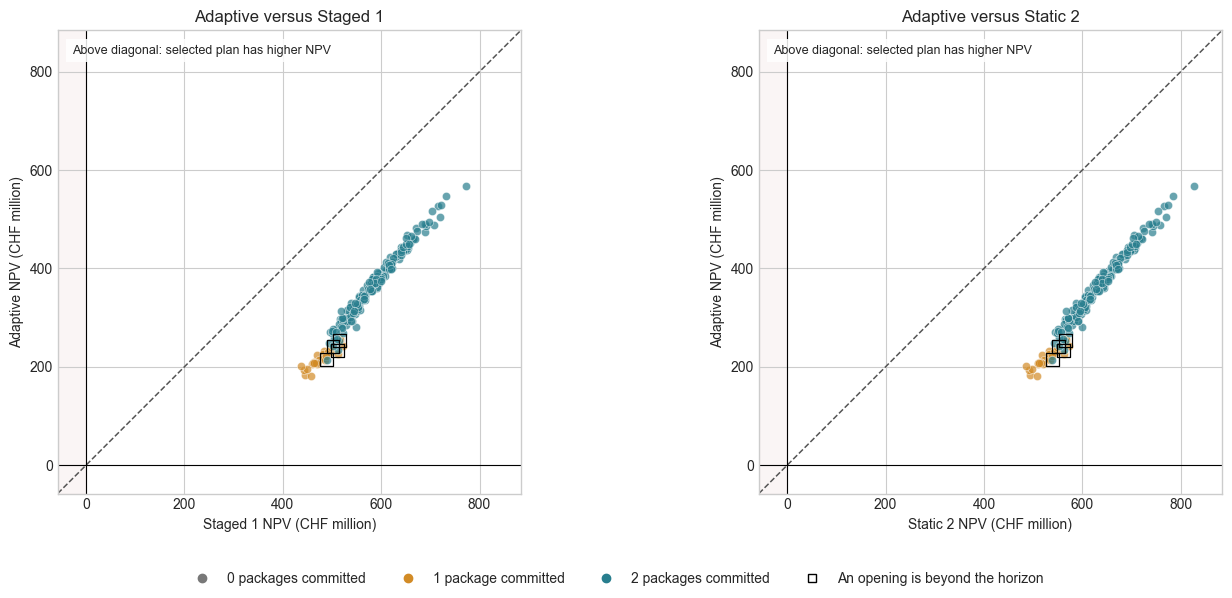

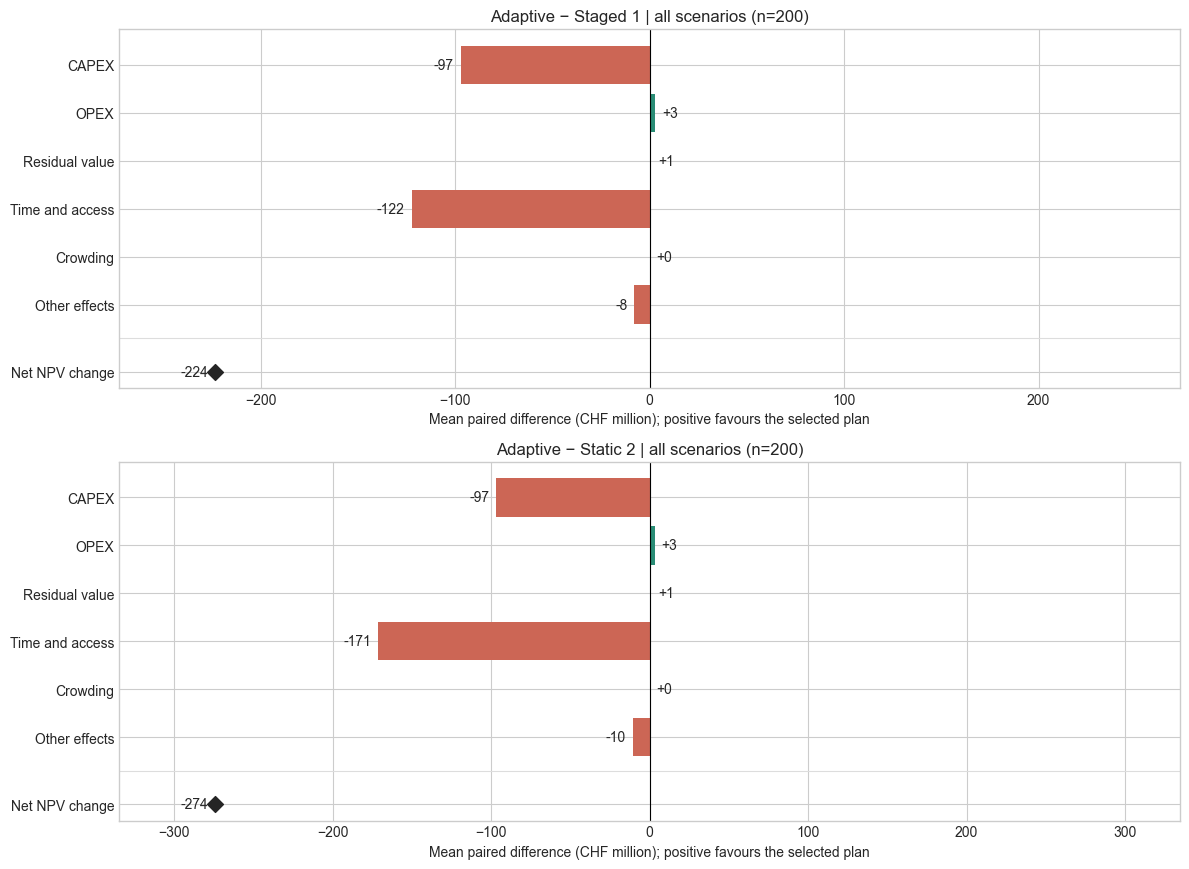

In [20]:
if WAITING_AVAILABLE:
    # Keep the full ensemble, or inspect cases where the comparator has negative NPV.
    WAITING_COMPONENT_POPULATION = "all"  # "all" or "comparator_negative"

    if WAITING_COMPONENT_POPULATION not in {"all", "comparator_negative"}:
        raise ValueError("WAITING_COMPONENT_POPULATION must be 'all' or 'comparator_negative'.")

    # A package may be committed even though it has not opened by the final year.
    package_numbers = sorted({column[len("stage"):-len("_scheduled_opening_year")]
                              for column in focus if column.startswith("stage")
                              and column.endswith("_scheduled_opening_year")})
    if not package_numbers:
        raise ValueError("Package scheduled-opening years are needed to distinguish commitments from openings.")
    commitments = pd.DataFrame(index=focus.index)
    pending_openings = pd.DataFrame(index=focus.index)
    for number in package_numbers:
        scheduled = pd.to_numeric(focus[f"stage{number}_scheduled_opening_year"], errors="coerce")
        opened = pd.to_numeric(focus.get(f"stage{number}_opening_year", pd.Series(np.nan, index=focus.index)), errors="coerce")
        decision = pd.to_numeric(focus.get(f"decision{number}_year", pd.Series(np.nan, index=focus.index)), errors="coerce")
        commitments[number] = scheduled.gt(0) | opened.gt(0) | decision.gt(0)
        pending_openings[number] = scheduled.gt(N_YEARS)
    committed_count = commitments.sum(axis=1)
    pending_count = pending_openings.sum(axis=1)

    waiting_downside_records, waiting_case_records = [], []
    for comparator in WAITING_COMPARATORS:
        other = df.loc[df.plan.eq(comparator)].set_index("scenario").reindex(focus.index)
        pair = waiting_pairs.loc[waiting_pairs.comparator.eq(comparator)].set_index("scenario").reindex(focus.index)
        cases = pd.DataFrame({
            "focus_plan": WAITING_FOCUS_PLAN, "comparator": comparator,
            "focus_NPV_MCHF": focus.NPV_MCHF, "comparator_NPV_MCHF": other.NPV_MCHF,
            "NPV_difference_MCHF": pair.NPV_difference_MCHF,
            "expenditure_saving_MCHF": pair.expenditure_saving_MCHF,
            "packages_committed": committed_count,
            "committed_packages_opening_after_horizon": pending_count,
        }, index=focus.index)
        cases["comparator_negative_NPV"] = cases.comparator_NPV_MCHF.lt(0)
        cases["focus_negative_NPV"] = cases.focus_NPV_MCHF.lt(0)
        cases["loss_reduction_MCHF"] = (-cases.comparator_NPV_MCHF).clip(lower=0) - (-cases.focus_NPV_MCHF).clip(lower=0)
        waiting_case_records.append(cases.reset_index())
        populations = {
            "All scenarios": pd.Series(True, index=cases.index),
            "Comparator NPV < 0": cases.comparator_negative_NPV,
            "Comparator NPV < 0; no package committed": cases.comparator_negative_NPV & cases.packages_committed.eq(0),
        }
        for population, mask in populations.items():
            selected = cases.loc[mask]
            waiting_downside_records.append({
                "comparator": comparator, "population": population, "scenario_count": len(selected),
                "mean_comparator_NPV_MCHF": selected.comparator_NPV_MCHF.mean(),
                "mean_focus_NPV_MCHF": selected.focus_NPV_MCHF.mean(),
                "mean_NPV_improvement_MCHF": selected.NPV_difference_MCHF.mean(),
                "mean_loss_reduction_MCHF": selected.loss_reduction_MCHF.mean(),
                "mean_expenditure_saving_MCHF": selected.expenditure_saving_MCHF.mean(),
                "fraction_higher_NPV": selected.NPV_difference_MCHF.gt(0).mean() if len(selected) else np.nan,
                "no_package_committed_scenarios": int(selected.packages_committed.eq(0).sum()),
                "pending_opening_scenarios": int(selected.committed_packages_opening_after_horizon.gt(0).sum()),
                "pending_package_openings": int(selected.committed_packages_opening_after_horizon.sum()),
            })
    waiting_cases = pd.concat(waiting_case_records, ignore_index=True)
    waiting_downside = pd.DataFrame(waiting_downside_records)
    display_columns = {
        "scenario_count": "Scenarios", "mean_comparator_NPV_MCHF": "Comparator NPV",
        "mean_focus_NPV_MCHF": "Selected plan NPV", "mean_NPV_improvement_MCHF": "NPV improvement",
        "mean_loss_reduction_MCHF": "Loss reduction", "mean_expenditure_saving_MCHF": "Expenditure saved",
        "no_package_committed_scenarios": "No package committed", "pending_opening_scenarios": "Pending opening",
    }
    print("Economic amounts below are means in CHF million. Positive differences favour the selected plan.")
    print("Loss reduction compares losses below zero; it excludes any further positive NPV.")
    downside_display = waiting_downside.assign(comparator=waiting_downside.comparator.map(plan_label)).set_index(["comparator", "population"])
    display(downside_display[list(display_columns)].rename(columns=display_columns).round(1))
    export_table(waiting_cases, "05_waiting_downside_scenarios")
    export_table(waiting_downside, "05_waiting_downside_summary")

    columns = min(2, len(WAITING_COMPARATORS))
    rows = int(np.ceil(len(WAITING_COMPARATORS) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(7.2 * columns, 6 * rows), squeeze=False)
    values = waiting_cases[["focus_NPV_MCHF", "comparator_NPV_MCHF"]].to_numpy()
    low, high = min(0, np.nanmin(values)), max(0, np.nanmax(values))
    padding = max(50, (high - low) * .07)
    limits = (low - padding, high + padding)
    commitment_colours = ["#787878", "#d28b26", "#287e8e"]
    if len(package_numbers) > 2:
        commitment_colours = [plt.get_cmap("tab10")(i) for i in range(len(package_numbers) + 1)]
    for ax, comparator in zip(axes.flat, WAITING_COMPARATORS):
        cases = waiting_cases.loc[waiting_cases.comparator.eq(comparator)]
        ax.axvspan(limits[0], 0, color="#ba5d55", alpha=.06, zorder=0)
        for count in range(len(package_numbers) + 1):
            selected = cases.loc[cases.packages_committed.eq(count)]
            ax.scatter(selected.comparator_NPV_MCHF, selected.focus_NPV_MCHF,
                       color=commitment_colours[count], s=35, alpha=.7,
                       edgecolors="white", linewidths=.4, zorder=3)
        pending = cases.loc[cases.committed_packages_opening_after_horizon.gt(0)]
        ax.scatter(pending.comparator_NPV_MCHF, pending.focus_NPV_MCHF,
                   facecolors="none", edgecolors="black", marker="s", s=85, linewidths=.9, zorder=4)
        ax.plot(limits, limits, color="#555555", linestyle="--", linewidth=1.1, zorder=1)
        ax.axvline(0, color="black", linewidth=.8)
        ax.axhline(0, color="black", linewidth=.8)
        ax.set(xlim=limits, ylim=limits, aspect="equal",
               xlabel=f"{plan_label(comparator)} NPV (CHF million)",
               ylabel=f"{plan_label(WAITING_FOCUS_PLAN)} NPV (CHF million)",
               title=f"{plan_label(WAITING_FOCUS_PLAN)} versus {plan_label(comparator)}")
        ax.text(.03, .97, "Above diagonal: selected plan has higher NPV", transform=ax.transAxes,
                ha="left", va="top", fontsize=9, bbox=dict(facecolor="white", alpha=.85, edgecolor="none"))
    for ax in list(axes.flat)[len(WAITING_COMPARATORS):]:
        ax.set_visible(False)
    handles = [plt.Line2D([0], [0], marker="o", linestyle="none", color=colour,
                         label=f"{count} package{'s' if count != 1 else ''} committed")
               for count, colour in enumerate(commitment_colours)]
    handles.append(plt.Line2D([0], [0], marker="s", linestyle="none", markerfacecolor="none",
                             color="black", label="An opening is beyond the horizon"))
    fig.legend(handles=handles, loc="lower center", ncol=min(4, len(handles)), frameon=False)
    fig.tight_layout(rect=(0, .08, 1, 1))
    save_figure(FIGURES_DIR / "05_waiting_paired_npv_scatter.png")
    plt.show()

    # Every paired contribution is measured from zero.
    fig, axes = plt.subplots(len(WAITING_COMPARATORS), 1,
                             figsize=(12, 4.4 * len(WAITING_COMPARATORS)), squeeze=False)
    component_rows = []
    for ax, comparator in zip(axes.flat, WAITING_COMPARATORS):
        pairs = waiting_pairs.loc[waiting_pairs.comparator.eq(comparator)].set_index("scenario")
        cases = waiting_cases.loc[waiting_cases.comparator.eq(comparator)].set_index("scenario")
        if WAITING_COMPONENT_POPULATION == "comparator_negative":
            pairs = pairs.loc[cases.index[cases.comparator_negative_NPV]]
        if pairs.empty:
            ax.text(.5, .5, "No scenarios in this population", transform=ax.transAxes, ha="center", va="center")
            ax.set_axis_off()
            continue
        contributions = pairs[list(waiting_groups)].mean()
        net = pairs.NPV_difference_MCHF.mean()
        assert np.isclose(contributions.sum(), net)
        for label, value in contributions.items():
            component_rows.append({"comparator": comparator, "population": WAITING_COMPONENT_POPULATION,
                                   "scenario_count": len(pairs), "component": label, "mean_difference_MCHF": value})
        component_rows.append({"comparator": comparator, "population": WAITING_COMPONENT_POPULATION,
                               "scenario_count": len(pairs), "component": "Net NPV change", "mean_difference_MCHF": net})
        positions = np.arange(len(contributions))
        ax.barh(positions, contributions, color=["#298c75" if value >= 0 else "#cc6655" for value in contributions])
        net_position = len(contributions) + .4
        ax.axhline(len(contributions) - .3, color="#dddddd", linewidth=.8)
        ax.scatter([net], [net_position], marker="D", s=65, color="#252525", zorder=3)
        span = max(np.abs(np.r_[contributions.to_numpy(), net]).max(), 1)
        for position, value in zip([*positions, net_position], [*contributions, net]):
            ax.annotate(f"{value:+,.0f}", (value, position), xytext=(5 if value >= 0 else -5, 0),
                        textcoords="offset points", ha="left" if value >= 0 else "right", va="center", fontsize=10)
        ax.axvline(0, color="black", linewidth=.8)
        ax.set(yticks=[*positions, net_position], yticklabels=[*contributions.index, "Net NPV change"],
               xlim=(-span * 1.22, span * 1.22), xlabel="Mean paired difference (CHF million); positive favours the selected plan",
               title=f"{plan_label(WAITING_FOCUS_PLAN)} − {plan_label(comparator)} | "
                     f"{'all scenarios' if WAITING_COMPONENT_POPULATION == 'all' else 'comparator NPV < 0'} (n={len(pairs)})")
        ax.invert_yaxis()
    fig.tight_layout()
    export_table(pd.DataFrame(component_rows), "05_waiting_component_differences")
    save_figure(FIGURES_DIR / "05_waiting_component_differences.png")
    plt.show()


# Part 4 — Explain results and test assumptions

To identify the conditions under which plans succeed or fail, we apply a two-tier diagnostic:
1. **Directional driver check:** Spearman rank correlation assessing how sampled scenario uncertainties relate to incremental economic value.
2. **Patient Rule Induction Method (PRIM):** scenario discovery identifying concentrated regions of economic loss or physical requirement failure.

## 4.1 Directional driver check (mandatory task)

The next cell computes, for every plan, the Spearman rank correlation between selected scenario uncertainties and NPV or its components, all relative to the same-scenario baseline. Positive correlation means higher input values are associated with a higher NPV contribution. Correlation is descriptive, not proof of causation; constant outcomes have no defined correlation.


cell running: 00:00

uncertainty                   ACCIDENT_COST_MULTIPLIER BIKE_ASC_SHIFT  \
plan     outcome                                                        
staged1  NPV_MCHF                                0.011           0.49   
         NPV_car_time_MCHF                      -0.005          0.078   
         NPV_inv_MCHF                            0.007         -0.109   
         NPV_op_MCHF                            -0.026         -0.084   
         NPV_pt_crowding_MCHF                      n/a            n/a   
         NPV_pt_time_MCHF                          n/a            n/a   
static2  NPV_MCHF                                0.012          0.483   
         NPV_car_time_MCHF                      -0.005          0.072   
         NPV_inv_MCHF                            0.007         -0.109   
         NPV_op_MCHF                            -0.026         -0.084   
         NPV_pt_crowding_MCHF                      n/a            n/a   
         NPV_pt_time_MCHF                          n/a            n/a   
flexible NPV_MCHF                               -0.001          0.531   
         NPV_car_time_MCHF                      -0.019          0.157   
         NPV_inv_MCHF                              0.0         -0.126   
         NPV_op_MCHF                            -0.026         -0.107   
         NPV_pt_crowding_MCHF                      n/a            n/a   
         NPV_pt_time_MCHF                          n/a            n/a   

uncertainty                   CAPEX_MULTIPLIER CAR_CO2_KG_PER_VEHICLE_KM  \
plan     outcome                                                           
staged1  NPV_MCHF                          0.0                    -0.035   
         NPV_car_time_MCHF               -0.02                     0.001   
         NPV_inv_MCHF                     -1.0                     0.102   
         NPV_op_MCHF                     0.041                     -0.05   
         NPV_pt_crowding_MCHF              n/a                       n/a   
         NPV_pt_time_MCHF                  n/a                       n/a   
static2  NPV_MCHF                          0.0                    -0.034   
         NPV_car_time_MCHF              -0.022                     0.001   
         NPV_inv_MCHF                     -1.0                     0.102   
         NPV_op_MCHF                     0.041                     -0.05   
         NPV_pt_crowding_MCHF              n/a                       n/a   
         NPV_pt_time_MCHF                  n/a                       n/a   
flexible NPV_MCHF                       -0.073                     -0.04   
         NPV_car_time_MCHF               0.001                    -0.012   
         NPV_inv_MCHF                   -0.998                     0.112   
         NPV_op_MCHF                     0.041                    -0.048   
         NPV_pt_crowding_MCHF              n/a                       n/a   
         NPV_pt_time_MCHF                  n/a                       n/a   

uncertainty                   EBIKE_SHARE LOCAL_AIR_COST_MULTIPLIER  \
plan     outcome                                                      
staged1  NPV_MCHF                   0.087                    -0.005   
         NPV_car_time_MCHF         -0.038                    -0.004   
         NPV_inv_MCHF               0.033                    -0.003   
         NPV_op_MCHF                0.049                    -0.071   
         NPV_pt_crowding_MCHF         n/a                       n/a   
         NPV_pt_time_MCHF             n/a                       n/a   
static2  NPV_MCHF                   0.085                    -0.004   
         NPV_car_time_MCHF         -0.034                    -0.003   
         NPV_inv_MCHF               0.033                    -0.003   
         NPV_op_MCHF                0.049                    -0.071   
         NPV_pt_crowding_MCHF         n/a                       n/a   
         NPV_pt_time_MCHF             n/a                       n/a   
flexible NPV_MCHF       

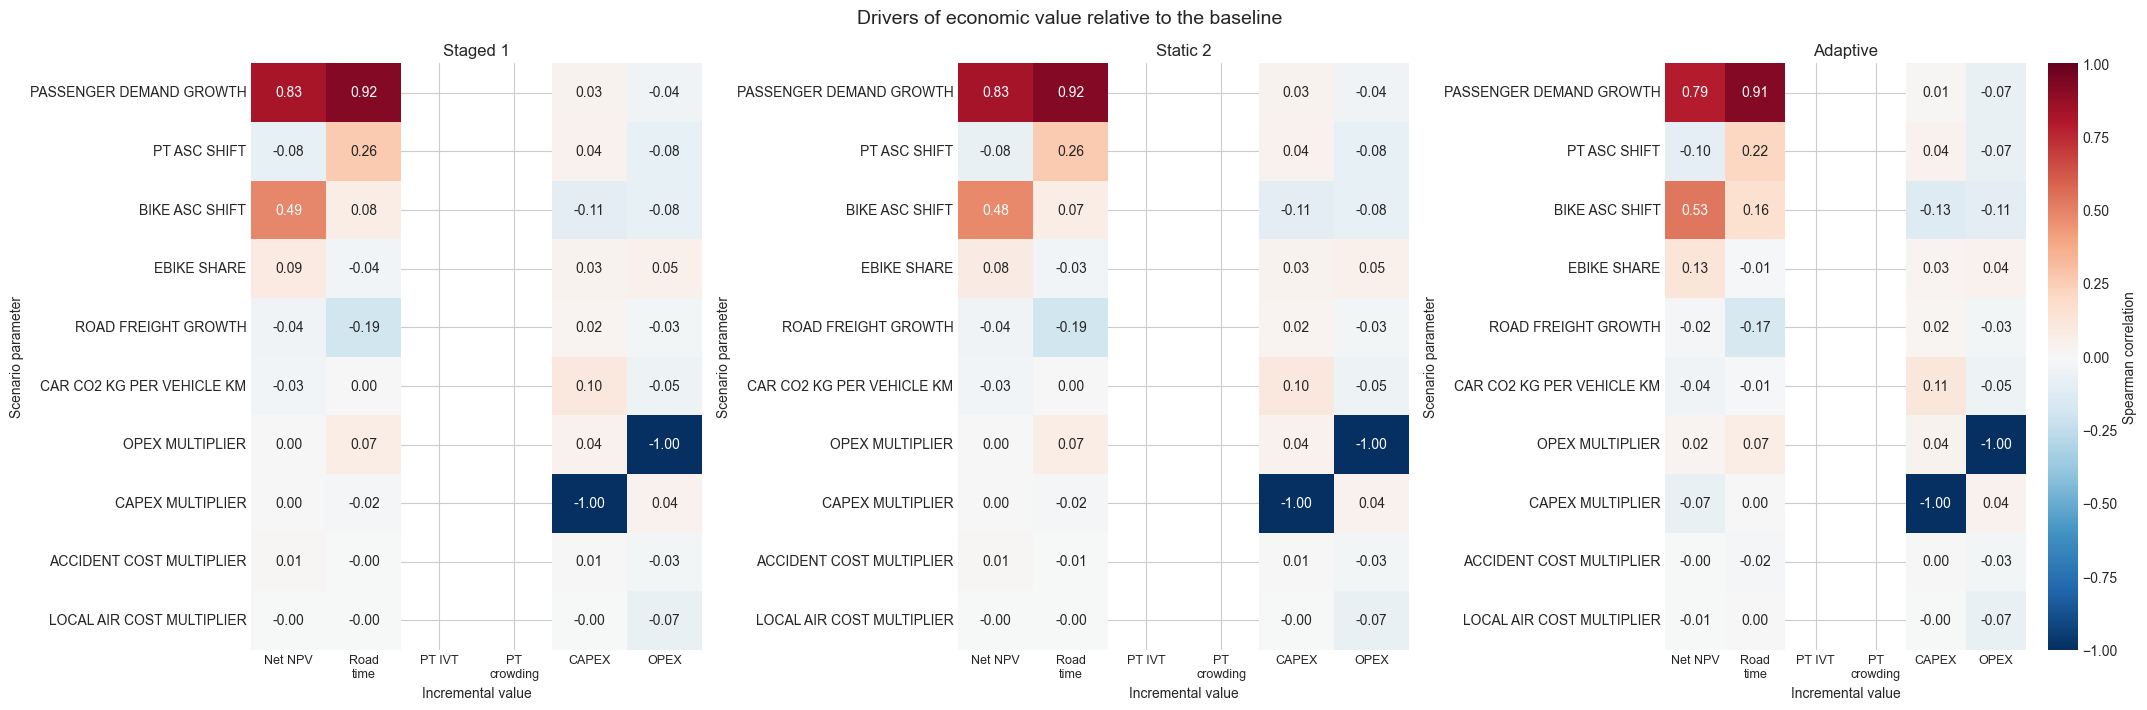

In [21]:
# Select scenario inputs, combined benefit categories and displayed plans.
DRIVER_INPUTS = SAMPLED_NAMES.copy()
DRIVER_OUTCOMES = [
    'NPV_MCHF', 'NPV_car_time_MCHF', 'NPV_pt_time_MCHF',
    'NPV_pt_crowding_MCHF', 'NPV_inv_MCHF', 'NPV_op_MCHF',
]
DRIVER_PLOT_PLANS = list(dict.fromkeys(COMPARISON_PLANS + ([ADAPTIVE_PLAN] if ADAPTIVE_PLAN else [])))
# Replace DRIVER_PLOT_PLANS with a list of available plan IDs to focus this figure.
DRIVER_OUTCOME_LABELS = {
    'NPV_MCHF': 'Net NPV', 'NPV_car_time_MCHF': 'Road time',
    'NPV_pt_time_MCHF': 'PT IVT', 'NPV_pt_crowding_MCHF': 'PT crowding',
    'NPV_inv_MCHF': 'CAPEX', 'NPV_op_MCHF': 'OPEX',
}

unknown = set(DRIVER_INPUTS) - set(physical_scenario_inputs.columns)
if unknown:
    raise ValueError(f'DRIVER_INPUTS contains unavailable scenario inputs: {sorted(unknown)}')
if len(set(DRIVER_INPUTS)) != len(DRIVER_INPUTS) or len(set(DRIVER_OUTCOMES)) != len(DRIVER_OUTCOMES):
    raise ValueError('Choose distinct driver inputs and outcomes.')
if any(plan not in PLANS for plan in DRIVER_PLOT_PLANS):
    raise ValueError('Choose available plans for DRIVER_PLOT_PLANS.')
# Use exactly the passenger categories shown in the component figures.
driver_values = df.copy()
for column in report_components:
    driver_values[column] = report_components[column]
missing = set(DRIVER_OUTCOMES) - set(driver_values.columns)
if missing:
    raise ValueError(f'DRIVER_OUTCOMES contains unavailable outputs: {sorted(missing)}')
driver_data = driver_values.drop(columns=DRIVER_INPUTS, errors='ignore').merge(
    physical_scenario_inputs[['scenario', *DRIVER_INPUTS]],
    on='scenario', how='left', validate='many_to_one')
driver_rows = []
for plan_name in PLANS:
    subset = driver_data.loc[driver_data['plan'] == plan_name]
    for outcome in DRIVER_OUTCOMES:
        for parameter in DRIVER_INPUTS:
            paired = subset[[parameter, outcome]].replace([np.inf, -np.inf], np.nan).dropna()
            varying = len(paired) >= 3 and paired[parameter].nunique() > 1 and paired[outcome].nunique() > 1
            driver_rows.append({
                'plan': plan_name, 'outcome': outcome, 'uncertainty': parameter,
                'spearman_correlation': paired[parameter].corr(paired[outcome], method='spearman') if varying else np.nan,
                'scenarios': len(paired), 'status': 'Estimated' if varying else 'Insufficient variation',
            })
drivers_df = pd.DataFrame(driver_rows, columns=[
    'plan', 'outcome', 'uncertainty', 'spearman_correlation', 'scenarios', 'status'])
export_table(drivers_df, '05_directional_drivers')
if len(drivers_df) and DRIVER_PLOT_PLANS:
    driver_table = drivers_df.pivot(index=['plan', 'outcome'], columns='uncertainty', values='spearman_correlation')
    display(driver_table.loc[DRIVER_PLOT_PLANS].round(3).fillna('n/a'))
    from textwrap import fill
    fig, axes = plt.subplots(1, len(DRIVER_PLOT_PLANS),
        figsize=(6.5 * len(DRIVER_PLOT_PLANS) + 2, max(5.5, .52 * len(DRIVER_INPUTS) + 2)), squeeze=False)
    for ax, plan_name in zip(axes.flat, DRIVER_PLOT_PLANS):
        scores = driver_table.loc[plan_name].reindex(index=DRIVER_OUTCOMES, columns=DRIVER_INPUTS).T
        scores.columns = [fill(DRIVER_OUTCOME_LABELS.get(name, comp_labels.get(name, name.replace('_', ' '))), 7, break_long_words=False, break_on_hyphens=False)
                          for name in scores.columns]
        scores.index = [fill(name.replace('_', ' '), 28) for name in scores.index]
        sns.heatmap(scores, ax=ax, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1,
                    mask=scores.isna(), cbar=ax is axes.flat[-1], cbar_kws={'label': 'Spearman correlation'})
        ax.set(title=plan_label(plan_name), xlabel='Incremental value', ylabel='Scenario parameter')
        ax.tick_params(axis='x', rotation=0, labelsize=9)
        ax.tick_params(axis='y', rotation=0, labelsize=10)
    fig.suptitle('Drivers of economic value relative to the baseline', fontsize=14)
    fig.tight_layout()
    save_figure('05_incremental_value_drivers.png')
    plt.show()
else:
    print('Select varying scenario inputs, outcomes and at least one plan to plot the driver diagnostic.')


## 4.2 Economic and requirement vulnerability (mandatory task)

Economic vulnerability means NPV below zero relative to the same-scenario baseline. Physical vulnerability means at least one breach of an active requirement during its specified assessment years. The chart keeps these mechanisms separate: a plan may have positive NPV and still fail a requirement.


cell running: 00:00

,plan,mechanism,scenarios,failures,failure_share,mean_failure_years
0,baseline,negative_npv,200,0,0.000,NaN
1,baseline,requirement_1,200,22,0.110,1.265
2,baseline,requirement_2,200,94,0.470,1.615
3,baseline,requirement_3,200,141,0.705,2.075
4,flexible,negative_npv,200,0,0.000,NaN
5,flexible,requirement_1,200,5,0.025,0.650
6,flexible,requirement_2,200,2,0.010,0.230
7,flexible,requirement_3,200,132,0.660,1.830
8,staged1,negative_npv,200,0,0.000,NaN
9,staged1,requirement_1,200,5,0.025,0.565


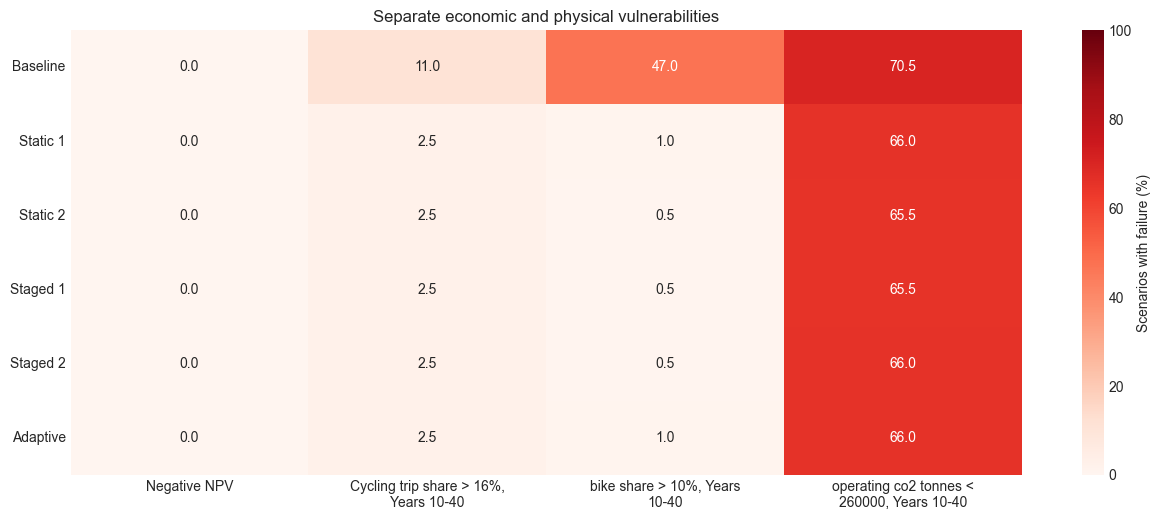

In [22]:
VULNERABILITY_PLANS = DISPLAY_PLANS.copy()
vulnerability_labels = {'negative_npv': 'Negative NPV'}
from textwrap import fill

def requirement_plot_label(rule):
    names = {"pt_share": "Strategic PT passenger-km share", "section_load_ratio": "Peak section load / capacity",
             "bike_share_trips": "Cycling trip share", "walk_share_trips": "Walking trip share",
             "bike_trips": "Cycling trips", "walk_trips": "Walking trips", "pt_trips": "PT trips"}
    indicator = rule['indicator']
    threshold = f"{rule['threshold']:.0%}" if indicator.endswith('_share') or indicator.endswith('_share_trips') or indicator == 'section_load_ratio' else f"{rule['threshold']:g}"
    name = names.get(indicator, indicator.replace('_', ' '))
    return f"{name} {rule['operator']} {threshold}, Years {rule['start_year']}-{rule['end_year']}"

vulnerability_labels.update({rule['id']: requirement_plot_label(rule) for rule in ACTIVE_REQUIREMENTS})
if not VULNERABILITY_PLANS or any(plan not in PLANS for plan in VULNERABILITY_PLANS):
    raise ValueError('Select at least one available plan for VULNERABILITY_PLANS.')
vulnerability_frames = []
for mechanism, label in vulnerability_labels.items():
    block = df[['scenario', 'plan']].copy()
    block['mechanism'] = mechanism
    block['label'] = label
    block['failed'] = df['NPV_MCHF'].lt(0).to_numpy() if mechanism == 'negative_npv' else df[f'{mechanism}_failed'].to_numpy()
    block['failure_years'] = np.nan if mechanism == 'negative_npv' else df[f'{mechanism}_failure_years'].to_numpy()
    vulnerability_frames.append(block)
vulnerability_outcomes = pd.concat(vulnerability_frames, ignore_index=True)
df['vulnerable'] = ~df['all_requirements_met']
vulnerability_summary = vulnerability_outcomes.groupby(['plan', 'mechanism'], observed=True).agg(
    scenarios=('failed', 'size'), failures=('failed', 'sum'),
    failure_share=('failed', 'mean'), mean_failure_years=('failure_years', 'mean')).reset_index()
export_table(vulnerability_summary, '05_vulnerability_by_mechanism')
export_table(vulnerability_outcomes, '05_vulnerability_scenarios')
display(vulnerability_summary.round(3))

rates = vulnerability_summary.pivot(index='plan', columns='mechanism', values='failure_share')
rates = rates.reindex(index=VULNERABILITY_PLANS, columns=list(vulnerability_labels)) * 100
rates.index = [plan_label(name) for name in rates.index]
rates.columns = [fill(vulnerability_labels[name], 27) for name in rates.columns]
fig, ax = plt.subplots(figsize=(max(9, 3.2 * len(rates.columns)), max(4.8, .55 * len(rates) + 2)))
sns.heatmap(rates, annot=True, fmt='.1f', cmap='Reds', vmin=0, vmax=100, ax=ax,
            cbar_kws={'label': 'Scenarios with failure (%)'})
ax.set(title='Separate economic and physical vulnerabilities', xlabel='', ylabel='')
ax.tick_params(axis='x', rotation=0, labelsize=10)
ax.tick_params(axis='y', rotation=0, labelsize=10)
fig.tight_layout()
save_figure('05_vulnerability_by_plan.png', dpi=150, bbox_inches='tight')
plt.show()


## 4.3 PRIM scenario discovery by failure mechanism (advanced task)

PRIM is run separately for negative NPV and for each active physical requirement. Select plans, physical scenario inputs and the density threshold below.

The selected box must reach 75% failure density and restrict at least one input. Among qualifying boxes, the one covering the most failures is selected. If none qualifies, the unrestricted initial box is retained as a clearly labelled reference.


In [23]:
PRIM_INPUTS = SAMPLED_NAMES.copy()
PRIM_PLANS = list(dict.fromkeys(COMPARISON_PLANS + ([ADAPTIVE_PLAN] if ADAPTIVE_PLAN else [])))
# Add 'baseline' to PRIM_PLANS when a physical reference comparison is useful.
PRIM_MECHANISMS = list(vulnerability_labels)
PRIM_PLOT_INPUTS = list(dict.fromkeys(
    [name for name in ('PASSENGER_DEMAND_GROWTH', 'PT_ASC_SHIFT') if name in PRIM_INPUTS] + PRIM_INPUTS
))[:2]  # Choose any two selected physical inputs for the projection.
PRIM_DENSITY_THRESHOLD = 0.75
MIN_CASES_PER_CLASS_FOR_PRIM = 15
PRIM_FOCUS = ('negative_npv', ADAPTIVE_PLAN)  # (mechanism, plan) for the peeling-trajectory plot

if len(set(PRIM_INPUTS)) != len(PRIM_INPUTS) or any(name not in SAMPLED_NAMES for name in PRIM_INPUTS):
    raise ValueError('PRIM_INPUTS must contain distinct selected uncertainty names.')
if not 0 < PRIM_DENSITY_THRESHOLD <= 1:
    raise ValueError('PRIM_DENSITY_THRESHOLD must be in (0, 1].')
if any(name not in PLANS for name in PRIM_PLANS) or any(name not in vulnerability_labels for name in PRIM_MECHANISMS):
    raise ValueError('Choose available plans and failure mechanisms for PRIM.')

vulnerability_inputs = vulnerability_outcomes.merge(
    physical_scenario_inputs[['scenario', *PRIM_INPUTS]], on='scenario', how='left', validate='many_to_one')
if vulnerability_inputs[PRIM_INPUTS].isna().any().any():
    raise ValueError('Some requirement outcomes have no matching physical scenario inputs.')

prim_results, prim_status_rows, prim_bound_rows = {}, [], []
for mechanism in PRIM_MECHANISMS:
    for plan_name in PRIM_PLANS:
        subset = vulnerability_inputs.loc[(vulnerability_inputs['plan'] == plan_name)
                                          & (vulnerability_inputs['mechanism'] == mechanism)].reset_index(drop=True)
        varying = [name for name in PRIM_INPUTS if subset[name].nunique() > 1]
        failed = subset['failed'].to_numpy(dtype=bool)
        failures, successes = int(failed.sum()), int((~failed).sum())
        box, accepted, selected_step = None, False, None
        if not len(subset):
            status = 'No scenarios'
        elif not failures:
            status = 'No failures'
        elif not successes:
            status = 'Every scenario fails'
        elif not varying:
            status = 'No varying selected inputs'
        elif min(failures, successes) < MIN_CASES_PER_CLASS_FOR_PRIM:
            status = f'Too few cases: need {MIN_CASES_PER_CLASS_FOR_PRIM} per class'
        else:
            algorithm = prim.Prim(subset[varying], failed, threshold=PRIM_DENSITY_THRESHOLD, peel_alpha=.1)
            box = algorithm.find_box()
            if box is None:
                status = 'No box returned'
            else:
                peeling = box.peeling_trajectory
                qualifying = peeling.loc[(peeling['density'] >= PRIM_DENSITY_THRESHOLD)
                                          & (peeling['res_dim'] > 0)]
                accepted = not qualifying.empty
                selected_step = int(qualifying.sort_values(
                    ['coverage', 'density', 'res_dim'], ascending=[False, False, True]).index[0]) if accepted else 0
                box.select(selected_step)
                status = 'Qualifying box' if accepted else 'No qualifying box; unrestricted sample reference'
                export_table(peeling, f'05_prim_{mechanism}_{plan_name}_peeling', index=True)
                for parameter in box.box_lim.columns:
                    lower, upper = box.box_lim[parameter].to_numpy(dtype=float)
                    restricted = not (np.isclose(lower, subset[parameter].min()) and np.isclose(upper, subset[parameter].max()))
                    prim_bound_rows.append({'mechanism': mechanism, 'plan': plan_name,
                        'parameter': parameter, 'lower': lower, 'upper': upper, 'restricted': restricted,
                        'accepted': accepted, 'selected_step': selected_step})
        prim_results[(mechanism, plan_name)] = {'box': box, 'accepted': accepted, 'status': status, 'subset': subset}
        prim_status_rows.append({'mechanism': mechanism, 'plan': plan_name, 'scenarios': len(failed),
            'failures': failures, 'failure_share': failed.mean() if len(failed) else np.nan,
            'status': status, 'accepted': accepted, 'density': box.density if box is not None else np.nan,
            'coverage': box.coverage if box is not None else np.nan, 'selected_step': selected_step,
            'density_threshold': PRIM_DENSITY_THRESHOLD})

prim_status = pd.DataFrame(prim_status_rows, columns=['mechanism', 'plan', 'scenarios', 'failures',
    'failure_share', 'status', 'accepted', 'density', 'coverage', 'selected_step', 'density_threshold'])
prim_bounds = pd.DataFrame(prim_bound_rows, columns=[
    'mechanism', 'plan', 'parameter', 'lower', 'upper', 'restricted', 'accepted', 'selected_step'])
export_table(prim_status, '05_prim_status')
export_table(prim_bounds, '05_prim_physical_bounds')
display(prim_status.round(3))
display(prim_bounds.loc[prim_bounds['restricted']].round(4))
focus_result = prim_results.get(PRIM_FOCUS)
if focus_result is not None and focus_result['box'] is not None:
    focus_box = focus_result['box']
    peeling = focus_box.peeling_trajectory
    selected_step = int(prim_status.loc[(prim_status.mechanism == PRIM_FOCUS[0]) &
                                         (prim_status.plan == PRIM_FOCUS[1]), 'selected_step'].iloc[0])
    selected = peeling.loc[selected_step]
    fig, ax = plt.subplots(figsize=(8, 5.5))
    ax.plot(peeling.coverage, peeling.density, color='#cccccc', linewidth=1, zorder=1)
    points = ax.scatter(peeling.coverage, peeling.density, c=peeling.res_dim, cmap='viridis', s=50, zorder=2)
    fig.colorbar(points, ax=ax, label='Restricted inputs', ticks=sorted(peeling.res_dim.unique()))
    ax.axhline(PRIM_DENSITY_THRESHOLD, color='#a94442', linestyle='--', linewidth=1.3,
               label=f'Required failure density: {PRIM_DENSITY_THRESHOLD:.0%}')
    ax.scatter([selected.coverage], [selected.density], marker='*', s=250, color='#e69f00',
               edgecolor='black', linewidth=.8, zorder=4,
               label='Selected qualifying box' if focus_result['accepted'] else 'Unrestricted reference')
    ax.set(xlabel='Coverage: share of failures inside box', ylabel='Density: failure share inside box',
           xlim=(-.03, 1.03), ylim=(-.03, 1.03),
           title=f"{plan_label(PRIM_FOCUS[1])}: {vulnerability_labels[PRIM_FOCUS[0]]}\n{focus_result['status']}")
    ax.legend(loc='lower left', fontsize=9)
    fig.tight_layout()
    save_figure('05_prim_tradeoff.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('No peeling trajectory is available for PRIM_FOCUS; inspect the status table.')


cell running: 00:00

,mechanism,plan,scenarios,failures,failure_share,status,accepted,density,coverage,selected_step,density_threshold
0,negative_npv,staged1,200,0,0.000,No failures,False,NaN,NaN,NaN,0.75
1,negative_npv,static2,200,0,0.000,No failures,False,NaN,NaN,NaN,0.75
2,negative_npv,flexible,200,0,0.000,No failures,False,NaN,NaN,NaN,0.75
3,requirement_1,staged1,200,5,0.025,Too few cases: need 15 per class,False,NaN,NaN,NaN,0.75
4,requirement_1,static2,200,5,0.025,Too few cases: need 15 per class,False,NaN,NaN,NaN,0.75
5,requirement_1,flexible,200,5,0.025,Too few cases: need 15 per class,False,NaN,NaN,NaN,0.75
6,requirement_2,staged1,200,1,0.005,Too few cases: need 15 per class,False,NaN,NaN,NaN,0.75
7,requirement_2,static2,200,1,0.005,Too few cases: need 15 per class,False,NaN,NaN,NaN,0.75
8,requirement_2,flexible,200,2,0.010,Too few cases: need 15 per class,False,NaN,NaN,NaN,0.75
9,requirement_3,staged1,200,131,0.655,Qualifying box,True,0.809,1.000,2.0,0.75


,mechanism,plan,parameter,lower,upper,restricted,accepted,selected_step
0,requirement_3,staged1,PASSENGER_DEMAND_GROWTH,0.0308,0.4694,True,True,2
10,requirement_3,static2,PASSENGER_DEMAND_GROWTH,0.0308,0.4694,True,True,2
20,requirement_3,flexible,PASSENGER_DEMAND_GROWTH,0.0308,0.4694,True,True,2


No peeling trajectory is available for PRIM_FOCUS; inspect the status table.


## 4.4 PRIM box comparison (advanced task)

Each row shows one failure mechanism and each column a selected plan. Choose two physical inputs in `PRIM_PLOT_INPUTS`(in 4.3). If a plan has no qualifying box, a qualifying Baseline box is shown as a labelled reference when available, with density and coverage recalculated for that plan. Otherwise, the unrestricted initial sample box is shown when PRIM was run. Neither reference is a successful discovery for that plan.

The rectangle is a two-dimensional projection. Restrictions on all other inputs still apply when calculating density and coverage and remain visible in the bounds table.


cell running: 00:00

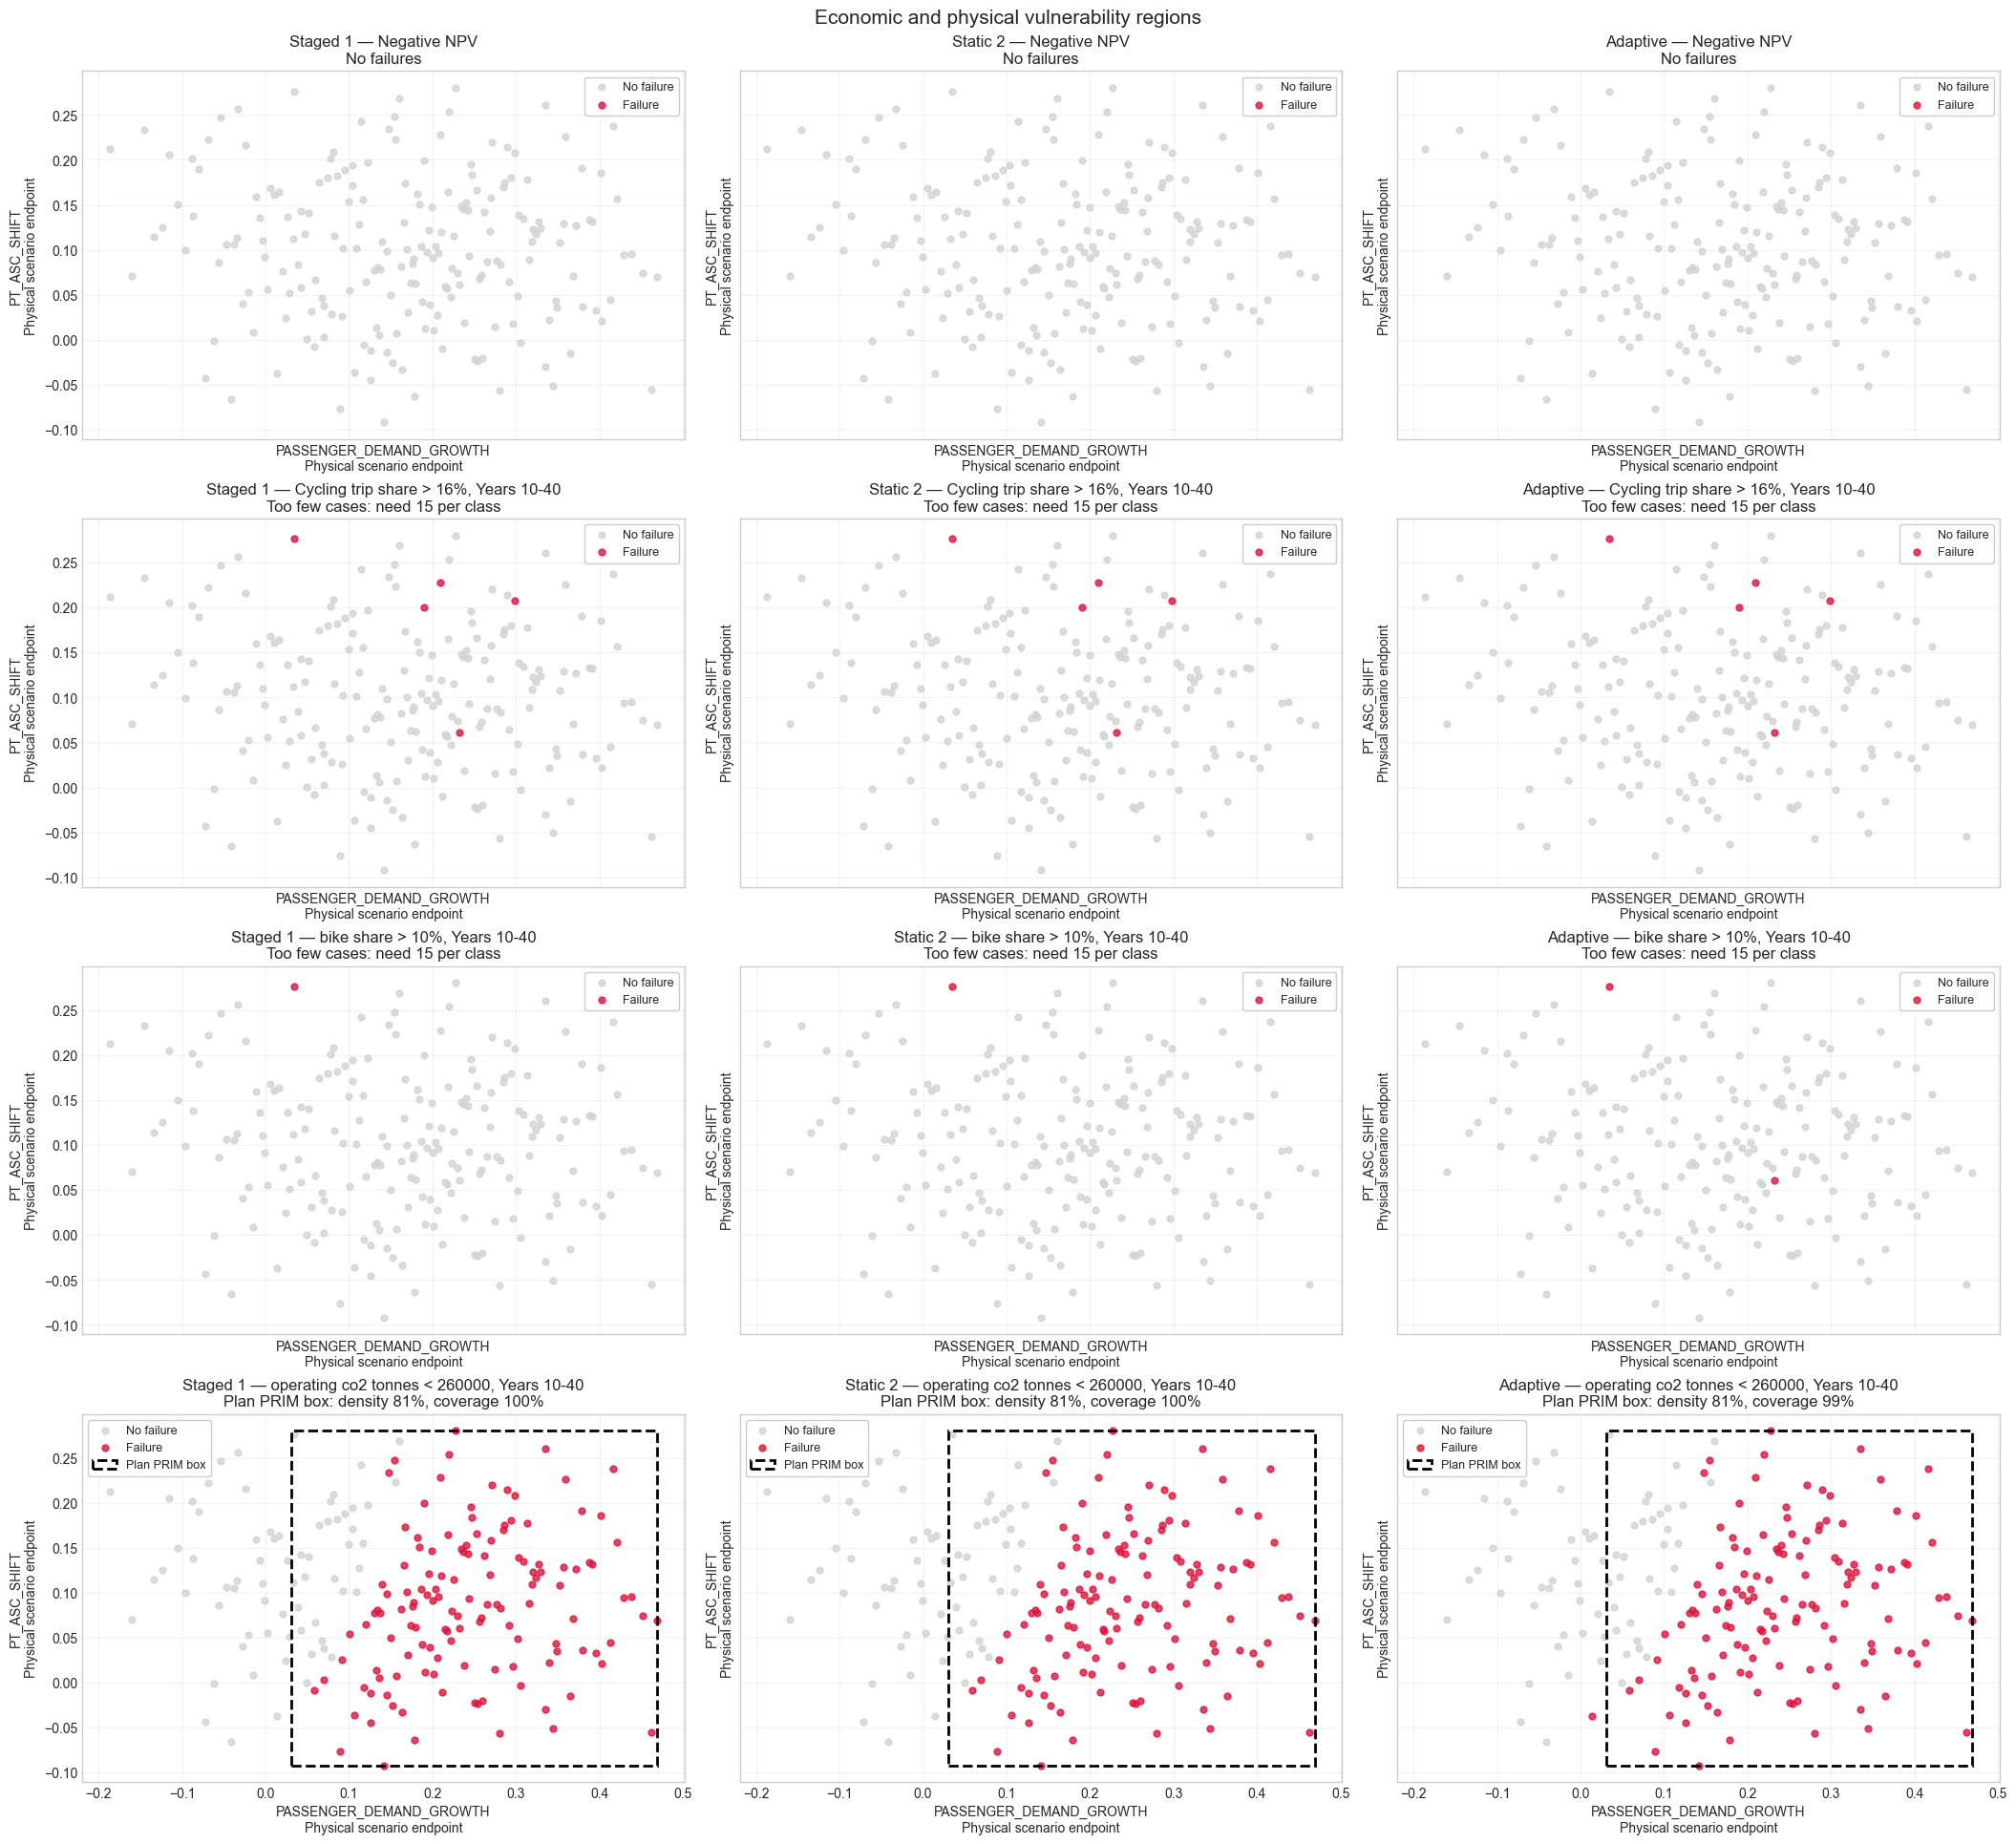

In [24]:
from matplotlib.patches import Rectangle
from textwrap import fill

if (len(PRIM_PLOT_INPUTS) != 2 or len(set(PRIM_PLOT_INPUTS)) != 2
        or any(name not in PRIM_INPUTS for name in PRIM_PLOT_INPUTS)):
    print('Choose two distinct PRIM_INPUTS in PRIM_PLOT_INPUTS to show the projections.')
elif not PRIM_MECHANISMS or not PRIM_PLANS:
    print('Select at least one failure mechanism and one plan to compare boxes.')
else:
    x_name, y_name = PRIM_PLOT_INPUTS
    fig, axes = plt.subplots(len(PRIM_MECHANISMS), len(PRIM_PLANS),
        figsize=(7 * len(PRIM_PLANS), 4.8 * len(PRIM_MECHANISMS)), squeeze=False,
        sharex=True, sharey=True, layout='constrained')
    shown_rows = []
    for row, mechanism in enumerate(PRIM_MECHANISMS):
        reference = prim_results.get((mechanism, 'baseline'))
        for ax, plan_name in zip(axes[row], PRIM_PLANS):
            if mechanism == 'negative_npv' and plan_name == 'baseline':
                ax.remove()  # Baseline NPV is identically zero; retain its physical comparisons.
                continue
            result = prim_results[(mechanism, plan_name)]
            subset = result['subset']
            for failed, color, label in [(False, 'lightgray', 'No failure'), (True, 'crimson', 'Failure')]:
                points = subset.loc[subset['failed'] == failed]
                ax.scatter(points[x_name], points[y_name], color=color, s=25, alpha=.8, label=label)
            if result['accepted']:
                shown_box, source = result['box'], 'Plan PRIM box'
            elif reference is not None and reference['accepted'] and plan_name != 'baseline':
                shown_box, source = reference['box'], 'Baseline reference box'
            else:
                shown_box, source = result['box'], 'Unrestricted sample reference'
            density = coverage = np.nan
            subtitle = result['status']
            if shown_box is not None:
                inside = np.ones(len(subset), dtype=bool)
                for name in shown_box.box_lim.columns:
                    lower, upper = shown_box.box_lim[name]
                    inside &= subset[name].between(lower, upper).to_numpy()
                failed_inside, total_failures = int(subset.loc[inside, 'failed'].sum()), int(subset['failed'].sum())
                density = failed_inside / inside.sum() if inside.any() else np.nan
                coverage = failed_inside / total_failures if total_failures else np.nan
                limits = {name: (shown_box.box_lim[name].to_numpy() if name in shown_box.box_lim
                                else subset[name].agg(['min', 'max']).to_numpy()) for name in PRIM_PLOT_INPUTS}
                (x0, x1), (y0, y1) = limits[x_name], limits[y_name]
                ax.add_patch(Rectangle((x0, y0), x1-x0, y1-y0, fill=False,
                    edgecolor='black' if result['accepted'] else '#555555', linewidth=2,
                    linestyle='--' if result['accepted'] else ':', label=source, zorder=5))
                subtitle = f'{source}: density {density:.0%}, coverage {coverage:.0%}'
                if not result['accepted']:
                    subtitle = 'No qualifying plan box; ' + subtitle
            shown_rows.append({'mechanism': mechanism, 'plan': plan_name,
                'box_source': source if shown_box is not None else 'none',
                'density_in_plan': density, 'coverage_in_plan': coverage})
            ax.set(title=f"{plan_label(plan_name)} — {fill(vulnerability_labels[mechanism], 45)}\n{fill(subtitle, 65)}",
                   xlabel=f'{x_name}\nPhysical scenario endpoint', ylabel=f'{y_name}\nPhysical scenario endpoint')
            ax.legend(fontsize=9, loc='best', frameon=True, facecolor='white', framealpha=1)
            ax.tick_params(labelsize=10)
            ax.grid(alpha=.25)
    fig.suptitle('Economic and physical vulnerability regions', fontsize=15)
    export_table(pd.DataFrame(shown_rows), '05_prim_shown_boxes')
    save_figure('05_prim_box_overlay.png', dpi=150, bbox_inches='tight')
    plt.show()


## 4.5 One-at-a-time appraisal-assumption sensitivity (mandatory task)

Vary each uncertainty marked `use="sensitivity"` separately at its configured test quantiles. Other parameters follow their nominal values and paths. Every plan is compared with a baseline evaluated under the same assumptions; this isolates the effect on incremental NPV.

`SENSITIVITY_UNCERTAINTIES = ALL` selects the configured set. Use a list to focus on selected assumptions and edit `SENSITIVITY_QUANTILES` to choose the cases.

For MehrSpur, the peak-hours cases test 3 and 5 hours around the nominal 4. They change peak congestion and crowding exposure; ordinary daily time savings keep their mode-specific daily conversion. These are appraisal assumptions, not all monetary valuations.

The tornado plot shows the selected plan's NPV change from its nominal appraisal. The table reports the tested **parameter inputs**, with units and their reference basis. Carbon uses the configured reference-year value; the model applies calendar-year escalation afterwards. A constant reference input therefore does not mean a constant annual carbon value. For a transient parameter, the start and end columns describe its selected input path.


cell running: 00:00

Appraisal-assumption sensitivity:   0%|          | 0/4 [00:00<?, ?it/s]

static1     434.4
static2     626.2
staged1     575.2
staged2     524.1
flexible    354.2
Name: Nominal NPV (CHF million), dtype: float64

plan                          flexible  staged1  staged2  static1  static2
uncertainty             case                                              
CO2_VALUE_CHF_PER_TONNE P10       -1.3     -1.6     -1.5     -1.4     -1.7
                        P90        2.9      3.5      3.4      3.2      3.8
C_TT_CAR                P10      -10.0    -12.6    -11.4     -8.9    -13.4
                        P90       10.0     12.6     11.4      8.9     13.4
C_TT_PT                 P10       -0.0     -0.0     -0.0      0.0     -0.0
                        P90       -0.0     -0.0      0.0      0.0     -0.0
NUMBER_OF_PEAK_HOURS    P10      -12.5    -15.7    -14.2    -11.1    -16.8
                        P90       12.5     15.7     14.2     11.1     16.8

,uncertainty,case,input_start,input_end,units,input_basis
0,C_TT_PT,P10,21.22,21.22,CHF/person-hour,Configured parameter input
5,C_TT_PT,P90,31.82,31.82,CHF/person-hour,Configured parameter input
10,C_TT_CAR,P10,34.04,34.04,CHF/person-hour,Configured parameter input
15,C_TT_CAR,P90,51.05,51.05,CHF/person-hour,Configured parameter input
20,CO2_VALUE_CHF_PER_TONNE,P10,97.96,97.96,CHF/tonne CO2,Reference-year value (2015); calendar escalation applied
25,CO2_VALUE_CHF_PER_TONNE,P90,179.9,179.9,CHF/tonne CO2,Reference-year value (2015); calendar escalation applied
30,NUMBER_OF_PEAK_HOURS,P10,3,3,hours/day,Configured parameter input
35,NUMBER_OF_PEAK_HOURS,P90,5,5,hours/day,Configured parameter input


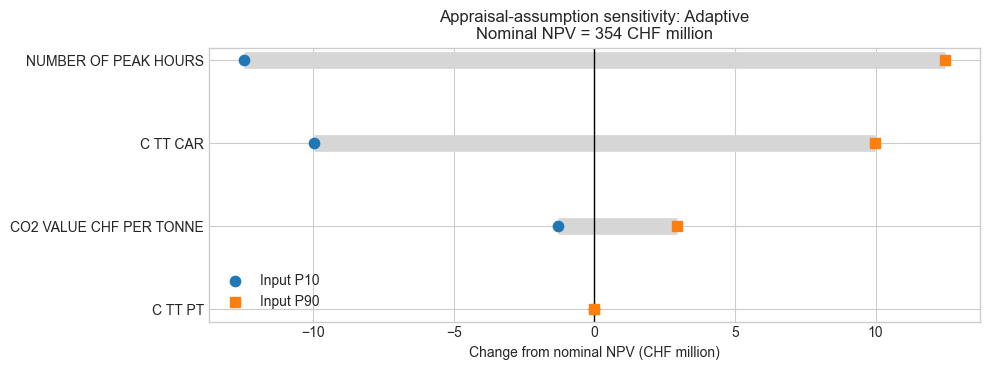

One input changes at a time around nominal paths; the endpoints are not joint uncertainty bounds.


In [25]:
SENSITIVITY_UNCERTAINTIES = ALL
sensitivity_names = [name for name in uc.select_uncertainties(SENSITIVITY_UNCERTAINTIES, use="sensitivity")
                     if not uc.is_deterministic(name)]
SENSITIVITY_QUANTILES = {"P10": 0.10, "P90": 0.90}
SENSITIVITY_PLAN = (ADAPTIVE_PLAN if ADAPTIVE_PLAN in PLANS and ADAPTIVE_PLAN != "baseline"
                    else next((plan for plan in PLANS if plan != "baseline"), None))
# Add units here for any other selected appraisal assumptions.
SENSITIVITY_UNITS = {
    "CO2_VALUE_CHF_PER_TONNE": "CHF/tonne CO2",
    "NUMBER_OF_PEAK_HOURS": "hours/day",
    "DISCOUNT_RATE": "fraction/year",
}
if not SENSITIVITY_QUANTILES or any(not np.isfinite(q) or not 0 <= q <= 1 for q in SENSITIVITY_QUANTILES.values()):
    raise ValueError("SENSITIVITY_QUANTILES must contain labelled quantiles between 0 and 1.")

def sensitivity_input_details(name):
    units = SENSITIVITY_UNITS.get(name, "CHF/person-hour" if name.startswith("C_TT_") else "parameter units")
    basis = (f"Reference-year value ({ANALYSIS_PARAMS['CO2_REFERENCE_YEAR']:g}); calendar escalation applied"
             if name == "CO2_VALUE_CHF_PER_TONNE" else "Configured parameter input")
    return units, basis

def appraise_sensitivity(draws):
    run_options = dict(draws, params=ANALYSIS_PARAMS, shapes=SELECTED_SHAPES,
                       transport_emulator=transport_emulator, include_welfare=True)
    baseline, _ = ap.run_plan(PLAN_SPECS["baseline"], STAGE_METRICS, **run_options)
    baseline_npc = m.npc_by_component(m.matched_appraisal_trajectory(baseline, baseline_results=baseline))["total"]
    values = {}
    for plan in PLANS:
        if plan == "baseline":
            values[plan] = 0.0
            continue
        result, _ = ap.run_plan(PLAN_SPECS[plan], STAGE_METRICS, **run_options)
        npc = m.npc_by_component(m.matched_appraisal_trajectory(result, baseline_results=baseline))["total"]
        values[plan] = baseline_npc - npc
    return values

if sensitivity_names:
    if SENSITIVITY_PLAN not in PLANS or SENSITIVITY_PLAN == "baseline":
        raise ValueError("Select a project plan for SENSITIVITY_PLAN.")
    nominal_npv = appraise_sensitivity({})
    sensitivity_rows = []
    for name in tqdm(sensitivity_names, desc="Appraisal-assumption sensitivity"):
        for label, quantile in SENSITIVITY_QUANTILES.items():
            values = appraise_sensitivity({name: quantile})
            path = uc.get_trajectory(name, quantile, SELECTED_SHAPES.get(name, "linear"), nominal=ANALYSIS_PARAMS)
            units, basis = sensitivity_input_details(name)
            for plan, npv in values.items():
                if plan != "baseline":
                    sensitivity_rows.append({
                        "uncertainty": name, "case": label, "input_start": path[0],
                        "input_end": path[-1], "units": units, "input_basis": basis, "plan": plan,
                        "NPV_MCHF": npv, "change_from_nominal_MCHF": npv - nominal_npv[plan],
                    })
    sensitivity_df = pd.DataFrame(sensitivity_rows)
    nominal_table = pd.Series(nominal_npv, name="Nominal NPV (CHF million)").drop("baseline")
    sensitivity_changes = sensitivity_df.pivot_table(index=["uncertainty", "case"], columns="plan",
                                                     values="change_from_nominal_MCHF")
    sensitivity_inputs = sensitivity_df[["uncertainty", "case", "input_start", "input_end", "units", "input_basis"]].drop_duplicates()
    display(nominal_table.round(1))
    display(sensitivity_changes.round(1))
    display(sensitivity_inputs.style.format({"input_start": "{:.4g}", "input_end": "{:.4g}"}))
    export_table(sensitivity_df, "05_appraisal_sensitivity")
    export_table(nominal_table, "05_sensitivity_nominal_npv", index=True)
    export_table(sensitivity_changes, "05_sensitivity_npv_changes", index=True)
    export_table(sensitivity_inputs, "05_sensitivity_input_values")

    tornado = sensitivity_df.loc[sensitivity_df.plan.eq(SENSITIVITY_PLAN)].pivot(
        index="uncertainty", columns="case", values="change_from_nominal_MCHF")
    tornado = tornado.loc[tornado.abs().max(axis=1).sort_values().index]
    fig, ax = plt.subplots(figsize=(10, max(3.8, 0.55 * len(tornado) + 1.6)))
    positions = np.arange(len(tornado))
    for y, (_, row) in zip(positions, tornado.iterrows()):
        ax.plot([row.min(), row.max()], [y, y], color="#d6d6d6", linewidth=12, solid_capstyle="butt", zorder=1)
    markers = ["o", "s", "^", "D", "v", "P", "X", "<", ">"]
    palette = plt.get_cmap("tab10")
    for i, label in enumerate(SENSITIVITY_QUANTILES):
        ax.scatter(tornado[label], positions, color=palette(i % 10), marker=markers[i % len(markers)],
                   s=55, label=f"Input {label}", zorder=3)
    ax.axvline(0, color="black", linewidth=1)
    ax.set(yticks=positions, yticklabels=[name.replace("_", " ") for name in tornado.index],
           xlabel="Change from nominal NPV (CHF million)",
           title=f"Appraisal-assumption sensitivity: {plan_label(SENSITIVITY_PLAN)}\nNominal NPV = {nominal_npv[SENSITIVITY_PLAN]:,.0f} CHF million")
    ax.legend(loc="best")
    fig.tight_layout()
    save_figure(FIGURES_DIR / "05_appraisal_sensitivity_tornado.png")
    plt.show()
    print("One input changes at a time around nominal paths; the endpoints are not joint uncertainty bounds.")
else:
    print("No appraisal-assumption sensitivities selected.")


# Part 5 — Improve the plan and recommend

## 5.1 Explore monitoring thresholds (advanced task)

Search/optimise the monitoring thresholds of one adaptive plan under the same scenarios used above. Select the plan, search ranges and resolution in the next cell. Ranges use each monitoring indicator's own units; leaving them unspecified searches around its current threshold and the observed variation. Persistence, construction lead times and the monitoring indicators themselves remain unchanged.

The grid reuses saved annual transport states and matched welfare. Its current-threshold result is checked against the saved appraisal before searching. One or two adaptive rules can be explored. A plan without adaptive rules has no threshold search.

The best tested (optimised) thresholds maximise **mean NPV** on this ensemble. The comparison then checks their requirement protection, downside losses, regret and commitments, so a higher mean does not automatically make them preferable. Regret uses the same candidate set for every displayed plan: all existing plans plus the best tested plan. It can therefore differ from Section 2.5's original-plan comparison.


cell running: 00:00

/Users/sebastian.bischoff/IP-HS26-MehrSpur-CaseStudy/code/additional/uncertainty.py:229: UserWarning: ROAD_FREIGHT_GROWTH exceeds its surrogate training range; clipping the trajectory to [-0.05451161530839066, 0.25451161530839067]. Review uncertainty tails or rebuild with wider coverage.
  return clip_transport_paths({key: get_trajectory(key, draws.get(key), shapes.get(key, "linear"), nominal=nominal)


Current-threshold audit passed; maximum difference 1.16e-10 MCHF.


,package,monitoring_indicator,current_threshold,search_minimum,search_maximum,observed_P05,observed_P95
0,1,bike_trips,50000.0,42500.0,57500.0,50731.3151,87427.2708
1,2,bike_trips,60000.0,51000.0,69000.0,50731.3151,87427.2708


518 paired threshold combinations tested across 200 scenarios.
Package 1: Peak-hour bike demand > 4.25e+04 — search boundary; consider a wider range.
Package 2: Peak-hour bike demand > 5.1e+04 — search boundary; consider a wider range.


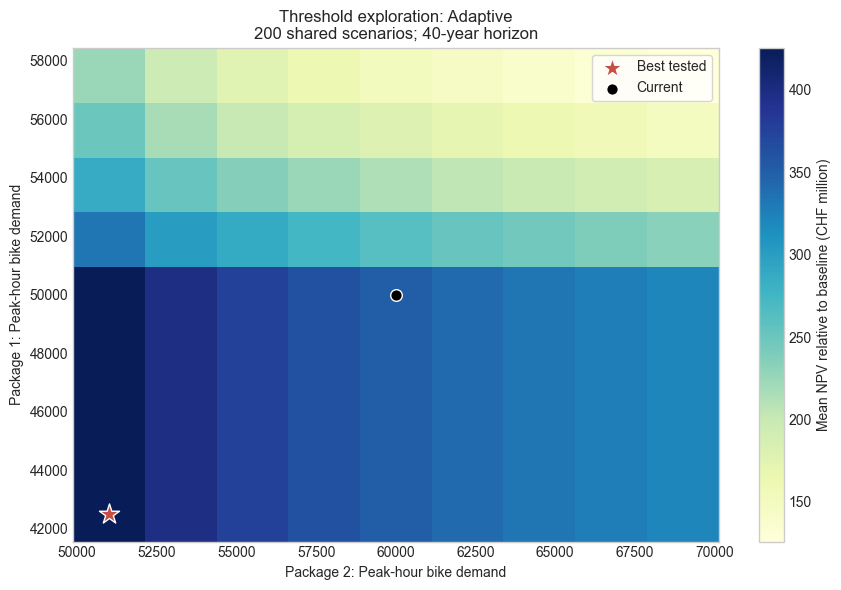

Checking the best tested policy against the planning requirements using the prepared response table.


Selected-policy requirements:   0%|          | 0/200 [00:00<?, ?it/s]

/Users/sebastian.bischoff/IP-HS26-MehrSpur-CaseStudy/code/additional/uncertainty.py:229: UserWarning: ROAD_FREIGHT_GROWTH exceeds its surrogate training range; clipping the trajectory to [-0.05451161530839066, 0.25451161530839067]. Review uncertainty tails or rebuild with wider coverage.
  return clip_transport_paths({key: get_trajectory(key, draws.get(key), shapes.get(key, "linear"), nominal=nominal)


Tail measures use the worst 10% of scenarios for each plan/metric.
Regret benchmark: all existing plans plus the best tested policy, on the same scenarios.


,mean_NPV_MCHF,negative_NPV_percent,expected_downside_loss_MCHF,worst_tail_mean_NPV_MCHF,mean_regret_MCHF,worst_tail_mean_regret_MCHF
plan,,,,,,
Adaptive,350.9,0.0,0.0,209.2,274.3,317.2
Staged 1,574.5,0.0,0.0,468.3,50.7,52.8
Static 2,625.2,0.0,0.0,517.2,0.0,0.0
Best tested thresholds,425.6,0.0,0.0,277.7,199.6,242.4


,requirements_met_percent,mean_failure_years,no_commitment_percent,pending_opening_percent
plan,,,,
Adaptive,33.5,2.5,0.0,2.0
Staged 1,34.0,2.4,0.0,0.0
Static 2,34.0,2.4,0.0,0.0
Best tested thresholds,34.0,2.4,0.0,0.0


In [26]:
# Local controls: thresholds use the selected monitoring indicator's units.
OPTIMIZATION_PLAN = ADAPTIVE_PLAN
OPTIMIZATION_COMPARATORS = COMPARISON_PLANS.copy()
THRESHOLD_RANGES = {}  # Optional {1: (minimum, maximum), 2: (minimum, maximum)}.
THRESHOLD_HALF_WIDTH = 0.15  # Default: at least +/-15% of the current threshold.
COARSE_POINTS = 9
FINE_POINTS = 21
OPTIMIZATION_TAIL_FRACTION = TAIL_FRACTION

from types import SimpleNamespace
from tqdm.auto import tqdm
import additional.trigger_optimization as topt
importlib.reload(topt)


def _threshold_search():
    if OPTIMIZATION_PLAN is None:
        print('No adaptive plan is selected; threshold exploration is skipped.')
        return None
    if OPTIMIZATION_PLAN not in PLAN_SPECS:
        raise ValueError('OPTIMIZATION_PLAN must be an available plan, or None.')
    specification = PLAN_SPECS[OPTIMIZATION_PLAN]
    transitions = {package: specification[f'to{package}'] for package in (1, 2)}
    active = [package for package, rule in transitions.items()
              if rule is not None and rule['type'] == 'trigger']
    if not active:
        print('The selected plan has no adaptive rules; threshold exploration is skipped.')
        return None
    if any(rule is not None and rule['type'] != 'trigger' for rule in transitions.values()):
        print('This fast search supports adaptive or absent transitions. Select a plan '
              'whose later additions are adaptive; fixed openings can be compared in Parts 2–3.')
        return None
    if not (isinstance(COARSE_POINTS, int) and COARSE_POINTS >= 3
            and isinstance(FINE_POINTS, int) and FINE_POINTS >= 3):
        raise ValueError('Use at least three whole-number points for each search resolution.')
    if not np.isfinite(THRESHOLD_HALF_WIDTH) or THRESHOLD_HALF_WIDTH <= 0:
        raise ValueError('THRESHOLD_HALF_WIDTH must be positive.')
    if not 0 < OPTIMIZATION_TAIL_FRACTION <= 1:
        raise ValueError('OPTIMIZATION_TAIL_FRACTION must be in (0, 1].')
    if any(plan not in PLANS for plan in OPTIMIZATION_COMPARATORS):
        raise ValueError('Choose available OPTIMIZATION_COMPARATORS.')

    scenarios = df.loc[df.plan.eq('baseline')].sort_values('scenario').reset_index(drop=True)
    annual_states = pd.concat([traj_df, tunnel_reference_df], ignore_index=True)
    # Temporary adapters retain this notebook's imported plan rules and inputs.
    original_planner, original_parameters, original_uncertainty = topt.ap, topt.p, topt.uc
    try:
        topt.ap = SimpleNamespace(**{**vars(ap), 'get_plans': lambda params: PLAN_SPECS})
        topt.p = SimpleNamespace(**{**vars(p), 'NOMINAL_PARAMS': ANALYSIS_PARAMS})
        topt.uc = SimpleNamespace(**{**vars(uc), 'build_paths':
            lambda draws, shapes=None: uc.build_paths(draws, shapes=shapes, nominal=ANALYSIS_PARAMS)})
        lookup = topt.build_stage_lookup(annual_states, scenarios, plan_name=OPTIMIZATION_PLAN)
    except ValueError as error:
        if 'reference' not in str(error).lower():
            raise
        print(f'Threshold search needs complete constant-state references: {error} '
              'Retain a constant plan for each state, or prepare its annual reference before this optional exercise.')
        return None
    finally:
        topt.ap, topt.p, topt.uc = original_planner, original_parameters, original_uncertainty

    current = {package: float(transitions[package]['threshold']) if package in active else 0.0
               for package in (1, 2)}
    _, audit = topt.simulate_threshold_grid(lookup, [current[1]], [current[2]],
                                          return_scenario_values=True)
    saved = df.loc[df.plan.eq(OPTIMIZATION_PLAN)].set_index('scenario').reindex(lookup['scenario_ids'])
    error = float(np.max(np.abs(audit['npc_MCHF'][0] - saved.NPC_total_MCHF.to_numpy())))
    if error >= 1e-6:
        raise ValueError(f'Current-threshold audit differs from the saved appraisal by {error:.3g} MCHF. '
                         'Check imported plans and annual references before interpreting the search.')
    print(f'Current-threshold audit passed; maximum difference {error:.2e} MCHF.')

    axes, limits, axis_rows = {}, {}, []
    for package in (1, 2):
        if package not in active:
            axes[package] = np.array([0.0])
            continue
        rule = transitions[package]
        observed = lookup[f'trigger{package}_values']
        finite = observed[np.isfinite(observed)]
        q05, q95 = np.quantile(finite, [.05, .95])
        half_width = max(abs(current[package]) * THRESHOLD_HALF_WIDTH,
                         (q95 - q05) * 0.1, np.finfo(float).eps)
        lower, upper = THRESHOLD_RANGES.get(package,
            (current[package] - half_width, current[package] + half_width))
        lower, upper = float(lower), float(upper)
        if not (np.isfinite(lower) and np.isfinite(upper) and lower < upper):
            raise ValueError(f'Package {package}: choose two finite increasing threshold bounds.')
        limits[package] = (lower, upper)
        axes[package] = np.linspace(lower, upper, COARSE_POINTS)
        if lower <= current[package] <= upper:
            axes[package] = np.unique(np.r_[axes[package], current[package]])
        axis_rows.append({'package': package, 'monitoring_indicator': rule['signpost'],
                          'current_threshold': current[package], 'search_minimum': lower,
                          'search_maximum': upper, 'observed_P05': q05, 'observed_P95': q95})
    search_axes = pd.DataFrame(axis_rows)
    display(search_axes.round(4))
    export_table(search_axes, '05_threshold_search_axes')
    coarse = topt.simulate_threshold_grid(lookup, axes[1], axes[2])
    coarse_best = coarse.loc[coarse.mean_NPV_MCHF.idxmax()]
    fine_axes = {}
    for package in (1, 2):
        if package not in active:
            fine_axes[package] = axes[package]
            continue
        lower, upper = limits[package]
        step = (upper - lower) / (COARSE_POINTS - 1)
        centre = coarse_best[f'stage{package}_threshold']
        fine_axes[package] = np.linspace(max(lower, centre - step), min(upper, centre + step), FINE_POINTS)
    fine = topt.simulate_threshold_grid(lookup, fine_axes[1], fine_axes[2])
    grid = pd.concat([coarse, fine], ignore_index=True).drop_duplicates(['stage1_threshold', 'stage2_threshold'])
    best = grid.loc[grid.mean_NPV_MCHF.idxmax()]
    selected_thresholds = {package: float(best[f'stage{package}_threshold']) for package in (1, 2)}
    _, chosen = topt.simulate_threshold_grid(lookup, [selected_thresholds[1]], [selected_thresholds[2]],
                                           return_scenario_values=True)
    print(f'{len(grid):,} paired threshold combinations tested across {len(scenarios)} scenarios.')
    for package in active:
        value = selected_thresholds[package]
        boundary = any(np.isclose(value, bound) for bound in limits[package])
        print(f"Package {package}: {transitions[package]['signpost_label']} > {value:,.4g}"
              + (' — search boundary; consider a wider range.' if boundary else ''))

    fig, ax = plt.subplots(figsize=(9, 6))
    if len(active) == 2:
        surface = coarse.pivot(index='stage1_threshold', columns='stage2_threshold', values='mean_NPV_MCHF')
        mesh = ax.pcolormesh(surface.columns, surface.index, surface.values, cmap='YlGnBu', shading='nearest')
        fig.colorbar(mesh, ax=ax, label='Mean NPV relative to baseline (CHF million)')
        ax.scatter(selected_thresholds[2], selected_thresholds[1], marker='*', s=230, color='#c64e43',
                   edgecolor='white', label='Best tested')
        if all(limits[package][0] <= current[package] <= limits[package][1] for package in active):
            ax.scatter(current[2], current[1], marker='o', s=70, color='black', edgecolor='white', label='Current')
        else:
            print('Current thresholds lie outside the selected search range; they remain in the comparison tables.')
        ax.set(xlabel='Package 2: ' + transitions[2]['signpost_label'],
               ylabel='Package 1: ' + transitions[1]['signpost_label'])
    else:
        package = active[0]
        ordered = grid.sort_values(f'stage{package}_threshold')
        ax.plot(ordered[f'stage{package}_threshold'], ordered.mean_NPV_MCHF, color='#287e8e')
        ax.scatter(selected_thresholds[package], best.mean_NPV_MCHF, marker='*', s=230,
                   color='#c64e43', label='Best tested')
        ax.scatter(current[package], saved.NPV_MCHF.mean(), color='black', s=70, label='Current')
        ax.set(xlabel=f"Package {package}: {transitions[package]['signpost_label']}",
               ylabel='Mean NPV relative to baseline (CHF million)')
    ax.set_title(f'Threshold exploration: {plan_label(OPTIMIZATION_PLAN)}\n'
                 f'{len(scenarios)} shared scenarios; {N_YEARS}-year horizon')
    ax.legend(frameon=True)
    fig.tight_layout()
    save_figure('05_threshold_optimization_heatmap.png')
    plt.show()
    export_table(grid.drop(columns=['mean_NPC_MCHF'], errors='ignore'), '05_threshold_search')

    selected_plan = copy.deepcopy(specification)
    for package in active:
        selected_plan[f'to{package}']['threshold'] = selected_thresholds[package]
    annual_rows, decisions = [], []
    print('Checking the best tested policy against the planning requirements using the prepared response table.')
    for definition in tqdm(scenario_definitions.to_dict('records'), desc='Selected-policy requirements'):
        scenario = int(definition['scenario'])
        draws = {name: float(definition[name]) for name in SAMPLED_NAMES}
        shapes = {name: str(definition[SHAPE_COLUMNS[name]]) for name in TRANSIENT_NAMES}
        annual, metadata = ap.run_plan(selected_plan, STAGE_METRICS, params=ANALYSIS_PARAMS,
            shapes=shapes, transport_emulator=transport_emulator, include_welfare=False,
            return_details=True, **draws)
        annual = add_appraisal_indicators(annual)
        annual['scenario'], annual['plan'] = scenario, '_best_tested'
        annual_rows.append(annual)
        item = {'scenario': scenario, 'plan': '_best_tested'}
        for package in (1, 2):
            opening = metadata[f'opening{package}_year'] or 0
            scheduled = metadata[f'activation{package}_year'] or opening
            item[f'stage{package}_scheduled_opening_year'] = scheduled
            item[f'stage{package}_opening_year'] = opening
            item[f'decision{package}_year'] = metadata[f'decision{package}_year'] or 0
        decisions.append(item)
    selected_annual = pd.concat(annual_rows, ignore_index=True)
    selected_summary = pd.DataFrame(decisions).set_index('scenario').reindex(lookup['scenario_ids'])
    selected_summary['NPV_MCHF'] = chosen['npv_MCHF'][0]
    requirements = evaluate_requirements(selected_annual).reset_index().set_index('scenario')
    for column in ('all_requirements_met', 'failure_years'):
        selected_summary[column] = requirements[column]
    for package in (1, 2):
        scheduled = selected_summary[f'stage{package}_scheduled_opening_year'].to_numpy()
        if not np.array_equal(scheduled, chosen[f'activation{package}_year'][0]):
            raise ValueError('Selected-policy replay and fast search disagree on implementation dates.')
    selected_summary = selected_summary.reset_index()
    # Use one enlarged candidate set for the current and selected policies alike.
    candidate_values = df.pivot(index='scenario', columns='plan', values='NPV_MCHF')
    candidate_values['_best_tested'] = selected_summary.set_index('scenario').NPV_MCHF
    benchmark = candidate_values.max(axis=1)
    names = list(dict.fromkeys([OPTIMIZATION_PLAN, *OPTIMIZATION_COMPARATORS, '_best_tested']))
    comparison_rows = []
    for name in names:
        cases = selected_summary if name == '_best_tested' else df.loc[df.plan.eq(name)]
        npv = cases.set_index('scenario').NPV_MCHF
        regret = benchmark.reindex(npv.index) - npv
        tail_count = max(1, int(np.ceil(OPTIMIZATION_TAIL_FRACTION * len(cases))))
        committed = sum((cases[f'stage{package}_scheduled_opening_year'].gt(0)
                         | cases[f'stage{package}_opening_year'].gt(0)
                         | cases[f'decision{package}_year'].gt(0)).astype(int) for package in (1, 2))
        pending = sum(cases[f'stage{package}_scheduled_opening_year'].gt(N_YEARS).astype(int)
                      for package in (1, 2))
        comparison_rows.append({'plan': name, 'mean_NPV_MCHF': npv.mean(),
            'negative_NPV_percent': 100 * npv.lt(0).mean(),
            'expected_downside_loss_MCHF': (-npv).clip(lower=0).mean(),
            'worst_tail_mean_NPV_MCHF': npv.nsmallest(tail_count).mean(),
            'mean_regret_MCHF': regret.mean(), 'worst_tail_mean_regret_MCHF': regret.nlargest(tail_count).mean(),
            'requirements_met_percent': 100 * cases.all_requirements_met.mean(),
            'mean_failure_years': cases.failure_years.mean(),
            'no_commitment_percent': 100 * committed.eq(0).mean(),
            'pending_opening_percent': 100 * pending.gt(0).mean()})
    comparison = pd.DataFrame(comparison_rows).set_index('plan')
    labels = lambda name: 'Best tested thresholds' if name == '_best_tested' else plan_label(name)
    print(f'Tail measures use the worst {OPTIMIZATION_TAIL_FRACTION:.0%} of scenarios for each plan/metric.')
    print('Regret benchmark: all existing plans plus the best tested policy, on the same scenarios.')
    display(comparison.iloc[:, :6].rename(index=labels).round(1))
    display(comparison.iloc[:, 6:].rename(index=labels).round(1))
    export_table(comparison, '05_threshold_policy_comparison', index=True)
    export_table(selected_summary, '05_threshold_selected_policy_scenarios')
    export_table(requirements.reset_index(), '05_threshold_selected_policy_requirements')
    return {'grid': grid, 'best': best, 'comparison': comparison,
            'selected_scenarios': selected_summary, 'selected_requirements': requirements,
            'max_current_audit_error_MCHF': error}


threshold_search_results = _threshold_search()


## 5.2 Interpret the appraisal results (mandatory task)

Use this final scorecard to justify a recommendation across economic value, downside risk, regret and physical requirement protection. These measures remain separate. Add your own evidence-based interpretation in `INTERPRETATION_NOTES`, using the component breakdown, the value and price of waiting and the separate PRIM mechanisms above. Meeting a requirement is not an additional monetary benefit.

Mean downside loss includes zero losses in profitable scenarios. Tail regret describes the worst configured fraction for each plan. The scorecard reuses Section 2.5's results and regret benchmark for the original plans; if recommending revised thresholds, also refer to Section 5.1's selected-policy comparison. Discuss relevant unpriced effects in your final report.


In [27]:
# Add interpretations after inspecting the current results.
INTERPRETATION_NOTES = {}  # Example: {ADAPTIVE_PLAN: 'Your evidence-based interpretation'}
SUMMARY_ECONOMIC_METRICS = ["mean_NPV_MCHF", "negative_NPV_share", "expected_downside_loss_MCHF",
                            "mean_regret_MCHF", "worst_tail_regret_MCHF"]
# Also available: positive_NPV_share, worst_tail_NPV_MCHF.
SUMMARY_PROTECTION_METRICS = ["requirements_met_share", "positive_NPV_and_requirements_share",
                              "mean_failure_years", "interpretation"]
interpretation_data = df.assign(
    positive_npv=df['NPV_MCHF'] > 0,
    positive_npv_and_requirements=(df['NPV_MCHF'] > 0) & df['all_requirements_met'])
interpretation_table = interpretation_data.groupby('plan').agg(
    mean_NPV_MCHF=('NPV_MCHF', 'mean'),
    positive_NPV_share=('positive_npv', 'mean'),
    requirements_met_share=('all_requirements_met', 'mean'),
    positive_NPV_and_requirements_share=('positive_npv_and_requirements', 'mean'),
    mean_failure_years=('failure_years', 'mean'),
).reindex(PLANS)
risk_columns = {
    "negative_NPV_fraction": "negative_NPV_share",
    "expected_downside_loss": "expected_downside_loss_MCHF",
    "mean_regret": "mean_regret_MCHF",
    "mean_worst_tail_regret": "worst_tail_regret_MCHF",
    "mean_worst_tail_NPV": "worst_tail_NPV_MCHF",
}
interpretation_table = interpretation_table.join(rob_df[list(risk_columns)].rename(columns=risk_columns))
interpretation_table['interpretation'] = [INTERPRETATION_NOTES.get(plan, '') for plan in interpretation_table.index]
export_table(interpretation_table, '05_interpretation', index=True)
summary_labels = {
    "mean_NPV_MCHF": "Mean NPV (CHF m)", "negative_NPV_share": "Negative NPV (%)",
    "positive_NPV_share": "Positive NPV (%)", "expected_downside_loss_MCHF": "Mean downside loss (CHF m)",
    "mean_regret_MCHF": "Mean regret (CHF m)", "worst_tail_regret_MCHF": f"Mean regret: {tail_label} (CHF m)",
    "worst_tail_NPV_MCHF": f"Mean NPV: {tail_label} (CHF m)",
    "requirements_met_share": "All requirements met (%)",
    "positive_NPV_and_requirements_share": "Positive NPV and requirements met (%)",
    "mean_failure_years": "Mean failure years", "interpretation": "Recommendation and evidence",
}
selected_metrics = SUMMARY_ECONOMIC_METRICS + SUMMARY_PROTECTION_METRICS
if set(selected_metrics) - set(summary_labels):
    raise ValueError(f"Select summary metrics from {list(summary_labels)}.")
summary_display = interpretation_table.loc[DISPLAY_PLANS].copy()
for column in [column for column in summary_display if column.endswith("_share")]:
    summary_display[column] *= 100
print("Economic value, downside and regret:")
display(summary_display[SUMMARY_ECONOMIC_METRICS].rename(columns=summary_labels, index=plan_label).round(1))
print("Requirement protection and recommendation:")
display(summary_display[SUMMARY_PROTECTION_METRICS].rename(columns=summary_labels, index=plan_label).round(1))
print('Explain economic losses and physical failures separately before recommending a plan.')


cell running: 00:00

Economic value, downside and regret:


,Mean NPV (CHF m),Negative NPV (%),Mean downside loss (CHF m),Mean regret (CHF m),Mean regret: worst 10% (CHF m)
plan,,,,,
Baseline,0.0,0.0,0.0,625.2,744.5
Static 1,436.9,0.0,0.0,188.3,221.2
Static 2,625.2,0.0,0.0,0.0,0.0
Staged 1,574.5,0.0,0.0,50.7,52.8
Staged 2,524.1,0.0,0.0,101.1,109.4
Adaptive,350.9,0.0,0.0,274.3,317.2


Requirement protection and recommendation:


,All requirements met (%),Positive NPV and requirements met (%),Mean failure years,Recommendation and evidence
plan,,,,
Baseline,10.0,0.0,3.6,
Static 1,33.5,33.5,2.5,
Static 2,34.0,34.0,2.4,
Staged 1,34.0,34.0,2.4,
Staged 2,33.5,33.5,2.4,
Adaptive,33.5,33.5,2.5,


Explain economic losses and physical failures separately before recommending a plan.


# Summary — you're done with Notebook 05!

This notebook turns the planning scenarios into a discounted economic appraisal and compares economic value with protection of the planning requirements.

As in the previous notebooks, **M** marks a mandatory/expected task, **T** a tutorial/supporting task, and **A** an advanced task. Supporting analyses need not become separate report deliverables.

| § | Aspect touched | Task type |
|---|---|---|
| **Part 1 — Define and prepare the appraisal** | | |
| 1.1 | Planning requirements and scenario/rule handover from Notebook 04 | M |
| 1.2 | Display plans, shared comparators and indicator catalogue | T |
| 1.3 | Paired appraisal, matched welfare, annualisation, premiums, residual values and construction emissions | M |
| 1.4 | Compact transport and total-benefit accuracy checks | M |
| **Part 2 — Compare economic value, risk and protection** | | |
| 2.1 | NPV distributions and downside | M |
| 2.2 | Combined component breakdown and benefit-cost ratio | M |
| 2.3 | Component-level NPV distributions | T |
| 2.4 | Economic and requirement-protection profiles | T |
| 2.5 | Downside, regret, requirement attainment and joint outcomes | M |
| **Part 3 — Understand the value and price of waiting** | | |
| 3.1 | Paired expenditure, economic value and requirement trade-offs | M |
| 3.2 | Adverse scenarios, commitments avoided and component differences | M |
| **Part 4 — Explain results and test assumptions** | | |
| 4.1 | Incremental economic drivers | M |
| 4.2 | Economic and requirement failure mechanisms | M |
| 4.3–4.4 | PRIM boxes, restrictions and visual interpretation | A |
| 4.5 | Appraisal-assumption sensitivity and tornado plot | M |
| **Part 5 — Improve the plan and recommend** | | |
| 5.1 | Configurable threshold search and selected-rule performance | A |
| 5.2 | Evidence-based interpretation and unpriced effects | M |

## What you should take away

Compare plans using incremental NPV, its components and economic downside alongside the protection of the planning objectives. Explain when waiting saves resources, when it sacrifices benefits, and which scenarios or valuation assumptions change the judgement. Record relevant unpriced effects separately and use this evidence to justify your final recommendation.

Completed figures and tables are in `figures/05_appraisal/` and `results/05_appraisal/`. Rerunning an analysis replaces its corresponding exports.
